In [2]:
# ============================================================
# Publication Paper v1
# Reproducibility + Environment Check
# ============================================================

import sys
import random
import numpy as np
import pandas as pd
import sklearn

try:
    import tensorflow as tf
    tensorflow_version = tf.__version__
except Exception:
    tf = None
    tensorflow_version = "Not loaded"

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

if tf is not None:
    tf.random.set_seed(SEED)

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("TensorFlow version:", tensorflow_version)
print("Random seed:", SEED)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
TensorFlow version: 2.20.0
Random seed: 42


In [3]:
# ============================================================
# Load Original Dataset
# ============================================================

DATA_PATH = "/content/Crop_recommendationV2.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (2200, 23)

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

First 5 rows:


,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,29.446064,2,...,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,12.851183,3,...,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,29.363913,2,...,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,26.207732,3,...,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,28.236236,2,...,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671



Data types:


,0
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,object
soil_moisture,float64
soil_type,int64



Missing values:


,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0
soil_moisture,0
soil_type,0



Duplicate rows: 0


In [4]:
# ============================================================
# Initial Dataset Audit
# ============================================================

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nUnique values per column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

print("\nNumerical summary:")
display(df.describe().T)

Number of rows: 2200
Number of columns: 23

Unique values per column:
N: 137
P: 117
K: 73
temperature: 2200
humidity: 2200
ph: 2200
rainfall: 2200
label: 22
soil_moisture: 2200
soil_type: 3
sunlight_exposure: 2200
wind_speed: 2200
co2_concentration: 2200
organic_matter: 2200
irrigation_frequency: 6
crop_density: 2200
pest_pressure: 2200
fertilizer_usage: 2200
growth_stage: 3
urban_area_proximity: 2200
water_source_type: 3
frost_risk: 2200
water_usage_efficiency: 2200

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117
soil_moisture,2200.0,20.151388,5.793720,10.024260,15.179949,20.088481,25.255146,29.997860
soil_type,2200.0,1.991364,0.812263,1.000000,1.000000,2.000000,3.000000,3.000000
sunlight_exposure,2200.0,8.570609,1.999382,5.000710,6.904620,8.609968,10.220394,11.991041


# ============================================================
# ERA5 and ERA5-Land Climate Dataset (2015–2025)
# ============================================================

## Real-World Climate and Soil-Moisture Data

This section prepares the real-world meteorological and soil-moisture
datasets used in the publication analysis.

Meteorological variables are obtained from the Copernicus ERA5
reanalysis dataset, while soil-moisture variables are obtained from
ERA5-Land.

The study period covers 2015–2025 and focuses on an agricultural
case-study area in Ireland.

In [5]:
# ============================================================
# Verify Raw Copernicus Data Files
# ============================================================

import os
import zipfile

ERA5_LAND_ZIP = "/content/ERA5LAND_SoilMoisture_2015_2025.zip"
ERA5_WEATHER_ZIP = "/content/ERA5_Weather_2015_2025.zip"

print("ERA5 weather file found:",
      os.path.exists(ERA5_WEATHER_ZIP))

print("ERA5-Land soil moisture file found:",
      os.path.exists(ERA5_LAND_ZIP))

print("\n--- ERA5 WEATHER ZIP CONTENTS ---")
with zipfile.ZipFile(ERA5_WEATHER_ZIP, "r") as z:
    print(z.namelist())

print("\n--- ERA5-LAND SOIL MOISTURE ZIP CONTENTS ---")
with zipfile.ZipFile(ERA5_LAND_ZIP, "r") as z:
    print(z.namelist())

ERA5 weather file found: True
ERA5-Land soil moisture file found: True

--- ERA5 WEATHER ZIP CONTENTS ---
['reanalysis-era5-single-levels-timeseries-sfcxx2bgwwj.csv']

--- ERA5-LAND SOIL MOISTURE ZIP CONTENTS ---
['reanalysis-era5-land-timeseries-sfc-soil-wateri0d7994e.nc']


In [6]:
# ============================================================
# Load ERA5 Meteorological Data
# ============================================================

import zipfile
import pandas as pd

ERA5_WEATHER_ZIP = "/content/ERA5_Weather_2015_2025.zip"

with zipfile.ZipFile(ERA5_WEATHER_ZIP, "r") as z:

    weather_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    print("CSV files found:", weather_files)

    if len(weather_files) != 1:
        raise ValueError(
            f"Expected exactly one CSV file, found {len(weather_files)}"
        )

    with z.open(weather_files[0]) as f:
        era5_weather = pd.read_csv(f)

print("\nERA5 weather dataset loaded successfully.")

print("\nShape:")
print(era5_weather.shape)

print("\nColumns:")
print(era5_weather.columns.tolist())

print("\nFirst 5 rows:")
display(era5_weather.head())

print("\nData types:")
display(era5_weather.dtypes)

print("\nMissing values:")
display(era5_weather.isnull().sum())

print("\nDuplicate rows:")
print(era5_weather.duplicated().sum())

CSV files found: ['reanalysis-era5-single-levels-timeseries-sfcxx2bgwwj.csv']

ERA5 weather dataset loaded successfully.

Shape:
(385728, 9)

Columns:
['valid_time', 'latitude', 'longitude', 'u10', 'v10', 'd2m', 't2m', 'slhf', 'tp']

First 5 rows:


,valid_time,latitude,longitude,u10,v10,d2m,t2m,slhf,tp
0,2015-01-01 00:00:00,53.25,-9.00,1.875244,5.794586,279.85440,282.31104,-45908.0,4.768372e-07
1,2015-01-01 00:00:00,53.25,-8.75,1.797119,5.358063,279.55753,281.94775,-41428.0,0.000000e+00
2,2015-01-01 00:00:00,53.50,-9.00,2.216064,5.866852,280.02628,282.71730,-49940.0,9.536743e-07
3,2015-01-01 00:00:00,53.50,-8.75,2.143799,5.593414,279.68448,282.24854,-51924.0,4.768372e-07
4,2015-01-01 01:00:00,53.25,-9.00,1.956497,6.142731,280.03894,282.36365,-36144.0,3.337860e-06



Data types:


,0
valid_time,object
latitude,float64
longitude,float64
u10,float64
v10,float64
d2m,float64
t2m,float64
slhf,float64
tp,float64



Missing values:


,0
valid_time,0
latitude,0
longitude,0
u10,0
v10,0
d2m,0
t2m,0
slhf,0
tp,0



Duplicate rows:
0


In [7]:
# ============================================================
# Verify ERA5 Temporal and Spatial Coverage
# ============================================================

# Convert time column to datetime
era5_weather["valid_time"] = pd.to_datetime(
    era5_weather["valid_time"]
)

print("Start date:")
print(era5_weather["valid_time"].min())

print("\nEnd date:")
print(era5_weather["valid_time"].max())

print("\nNumber of unique hourly timestamps:")
print(era5_weather["valid_time"].nunique())

print("\nLatitude values:")
print(sorted(era5_weather["latitude"].unique()))

print("\nLongitude values:")
print(sorted(era5_weather["longitude"].unique()))

print("\nUnique grid points:")
grid_points = (
    era5_weather[["latitude", "longitude"]]
    .drop_duplicates()
    .sort_values(["latitude", "longitude"])
    .reset_index(drop=True)
)

display(grid_points)

print("\nNumber of observations per grid point:")
display(
    era5_weather
    .groupby(["latitude", "longitude"])
    .size()
    .reset_index(name="observations")
)

Start date:
2015-01-01 00:00:00

End date:
2025-12-31 23:00:00

Number of unique hourly timestamps:
96432

Latitude values:
[np.float64(53.25), np.float64(53.5)]

Longitude values:
[np.float64(-9.0), np.float64(-8.75)]

Unique grid points:


,latitude,longitude
0,53.25,-9.00
1,53.25,-8.75
2,53.50,-9.00
3,53.50,-8.75



Number of observations per grid point:


,latitude,longitude,observations
0,53.25,-9.00,96432
1,53.25,-8.75,96432
2,53.50,-9.00,96432
3,53.50,-8.75,96432


In [8]:
# ============================================================
# Load and Inspect ERA5-Land Soil Moisture Data
# ============================================================

import zipfile
import xarray as xr
import os

ERA5_LAND_ZIP = "/content/ERA5LAND_SoilMoisture_2015_2025.zip"
ERA5_LAND_DIR = "/content/ERA5LAND_SoilMoisture"

# Create extraction folder
os.makedirs(ERA5_LAND_DIR, exist_ok=True)

# Extract the NetCDF file
with zipfile.ZipFile(ERA5_LAND_ZIP, "r") as z:
    z.extractall(ERA5_LAND_DIR)

    nc_files = [
        name for name in z.namelist()
        if name.lower().endswith(".nc")
    ]

print("NetCDF files found:", nc_files)

if len(nc_files) != 1:
    raise ValueError(
        f"Expected exactly one NetCDF file, found {len(nc_files)}"
    )

ERA5_LAND_NC = os.path.join(
    ERA5_LAND_DIR,
    nc_files[0]
)

# Load NetCDF dataset
era5_land = xr.open_dataset(ERA5_LAND_NC)

print("\nERA5-Land dataset loaded successfully.")

print("\nDataset structure:")
print(era5_land)

print("\nData variables:")
print(list(era5_land.data_vars))

print("\nCoordinates:")
print(list(era5_land.coords))

print("\nDimensions:")
print(dict(era5_land.sizes))

NetCDF files found: ['reanalysis-era5-land-timeseries-sfc-soil-wateri0d7994e.nc']

ERA5-Land dataset loaded successfully.

Dataset structure:
<xarray.Dataset> Size: 15MB
Dimensions:     (valid_time: 96432, latitude: 3, longitude: 3)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 771kB 2015-01-01 ... 2025-12-31T2...
  * latitude    (latitude) float64 24B 53.2 53.3 53.4
  * longitude   (longitude) float64 24B -9.0 -8.9 -8.8
Data variables:
    swvl1       (valid_time, latitude, longitude) float32 3MB ...
    swvl2       (valid_time, latitude, longitude) float32 3MB ...
    swvl3       (valid_time, latitude, longitude) float32 3MB ...
    swvl4       (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2025-02-20T05:15 GRIB to CDM+CF

In [9]:
# ============================================================
# Verify ERA5-Land Temporal, Spatial and Missing-Value Coverage
# ============================================================

import numpy as np

print("Start date:")
print(era5_land["valid_time"].min().values)

print("\nEnd date:")
print(era5_land["valid_time"].max().values)

print("\nNumber of hourly timestamps:")
print(era5_land.sizes["valid_time"])

print("\nLatitude values:")
print(era5_land["latitude"].values)

print("\nLongitude values:")
print(era5_land["longitude"].values)


# Check missing values in each soil-moisture layer
print("\nMissing values by soil-moisture layer:")

for var in ["swvl1", "swvl2", "swvl3", "swvl4"]:
    missing = int(era5_land[var].isnull().sum().values)
    total = era5_land[var].size

    print(
        f"{var}: {missing:,} missing out of {total:,} values "
        f"({missing / total * 100:.2f}%)"
    )


# Identify grid cells that contain missing values
print("\nMissing values by grid cell (swvl1):")

missing_by_cell = (
    era5_land["swvl1"]
    .isnull()
    .sum(dim="valid_time")
)

display(missing_by_cell.to_dataframe(name="missing_hours"))

Start date:
2015-01-01T00:00:00.000000000

End date:
2025-12-31T23:00:00.000000000

Number of hourly timestamps:
96432

Latitude values:
[53.2 53.3 53.4]

Longitude values:
[-9.  -8.9 -8.8]

Missing values by soil-moisture layer:
swvl1: 96,432 missing out of 867,888 values (11.11%)
swvl2: 96,432 missing out of 867,888 values (11.11%)
swvl3: 96,432 missing out of 867,888 values (11.11%)
swvl4: 96,432 missing out of 867,888 values (11.11%)

Missing values by grid cell (swvl1):


missing_hours
latitude longitude               
53.2     -9.0               96432
         -8.9                   0
         -8.8                   0
53.3     -9.0                   0
         -8.9                   0
         -8.8                   0
53.4     -9.0                   0
         -8.9                   0
         -8.8                   0

In [11]:
# ============================================================
# Compare ERA5 and ERA5-Land Spatial Grids
# ============================================================

import pandas as pd

# ERA5 weather grid
weather_grid = (
    era5_weather[["latitude", "longitude"]]
    .drop_duplicates()
    .sort_values(["latitude", "longitude"])
    .reset_index(drop=True)
)

weather_grid["dataset"] = "ERA5 Weather"


# ERA5-Land grid
land_grid = pd.MultiIndex.from_product(
    [
        era5_land["latitude"].values,
        era5_land["longitude"].values
    ],
    names=["latitude", "longitude"]
).to_frame(index=False)

# Identify whether each soil grid cell has usable data
land_grid["usable"] = land_grid.apply(
    lambda row: not bool(
        era5_land["swvl1"]
        .sel(
            latitude=row["latitude"],
            longitude=row["longitude"]
        )
        .isnull()
        .all()
        .values
    ),
    axis=1
)

land_grid["dataset"] = "ERA5-Land Soil Moisture"


print("--- ERA5 WEATHER GRID ---")
display(weather_grid)

print("\n--- ERA5-LAND SOIL-MOISTURE GRID ---")
display(land_grid)

--- ERA5 WEATHER GRID ---


,latitude,longitude,dataset
0,53.25,-9.00,ERA5 Weather
1,53.25,-8.75,ERA5 Weather
2,53.50,-9.00,ERA5 Weather
3,53.50,-8.75,ERA5 Weather



--- ERA5-LAND SOIL-MOISTURE GRID ---


,latitude,longitude,usable,dataset
0,53.2,-9.0,False,ERA5-Land Soil Moisture
1,53.2,-8.9,True,ERA5-Land Soil Moisture
2,53.2,-8.8,True,ERA5-Land Soil Moisture
3,53.3,-9.0,True,ERA5-Land Soil Moisture
4,53.3,-8.9,True,ERA5-Land Soil Moisture
5,53.3,-8.8,True,ERA5-Land Soil Moisture
6,53.4,-9.0,True,ERA5-Land Soil Moisture
7,53.4,-8.9,True,ERA5-Land Soil Moisture
8,53.4,-8.8,True,ERA5-Land Soil Moisture


In [12]:
# ============================================================
# Inspect ERA5 and ERA5-Land Variable Units and Ranges
# ============================================================

# ERA5 weather numerical ranges
weather_vars = ["u10", "v10", "d2m", "t2m", "slhf", "tp"]

print("--- ERA5 WEATHER VARIABLE RANGES ---")

for var in weather_vars:
    print(f"\n{var}")
    print("Minimum:", era5_weather[var].min())
    print("Maximum:", era5_weather[var].max())
    print("Mean:", era5_weather[var].mean())


# ERA5-Land soil-moisture ranges and metadata
print("\n--- ERA5-LAND SOIL MOISTURE ---")

for var in ["swvl1", "swvl2", "swvl3", "swvl4"]:

    da = era5_land[var]

    print(f"\n{var}")
    print("Minimum:", float(da.min().values))
    print("Maximum:", float(da.max().values))
    print("Mean:", float(da.mean().values))
    print("Units:", da.attrs.get("units", "Not specified"))
    print(
        "Long name:",
        da.attrs.get("long_name", "Not specified")
    )

--- ERA5 WEATHER VARIABLE RANGES ---

u10
Minimum: -11.092499
Maximum: 17.643112
Mean: 1.230586379207911

v10
Minimum: -10.773102
Maximum: 16.433746
Mean: 1.1650581550987265

d2m
Minimum: 264.36572
Maximum: 293.59314
Mean: 280.57186958890713

t2m
Minimum: 267.5843
Maximum: 303.59805
Mean: 283.41211341279353

slhf
Minimum: -1279091.0
Maximum: 204798.0
Mean: -165025.07546250208

tp
Minimum: 0.0
Maximum: 0.012622356
Mean: 0.0001311005162775713

--- ERA5-LAND SOIL MOISTURE ---

swvl1
Minimum: 0.1149139404296875
Maximum: 0.438995361328125
Mean: 0.3651917278766632
Units: m**3 m**-3
Long name: Volumetric soil water layer 1

swvl2
Minimum: 0.1553497314453125
Maximum: 0.438995361328125
Mean: 0.36559274792671204
Units: m**3 m**-3
Long name: Volumetric soil water layer 2

swvl3
Minimum: 0.1952972412109375
Maximum: 0.438995361328125
Mean: 0.3588132858276367
Units: m**3 m**-3
Long name: Volumetric soil water layer 3

swvl4
Minimum: 0.291778564453125
Maximum: 0.4320526123046875
Mean: 0.3837956190109

In [13]:
# ============================================================
# Create Interpretable ERA5 Meteorological Variables
# ============================================================

import numpy as np

# Work on a copy so the raw loaded data remain unchanged
weather_clean = era5_weather.copy()

# 2 m air temperature: Kelvin -> Celsius
weather_clean["temperature_c"] = (
    weather_clean["t2m"] - 273.15
)

# 2 m dew-point temperature: Kelvin -> Celsius
weather_clean["dewpoint_c"] = (
    weather_clean["d2m"] - 273.15
)

# 10 m wind speed from u and v components
weather_clean["wind_speed_ms"] = np.sqrt(
    weather_clean["u10"]**2 +
    weather_clean["v10"]**2
)

# Total precipitation: metres -> millimetres
# ERA5 hourly time-series tp represents precipitation
# accumulated over the hour ending at valid_time.
weather_clean["precipitation_mm"] = (
    weather_clean["tp"] * 1000
)

print("New meteorological variables created successfully.")

print("\nSelected variable summary:")
display(
    weather_clean[
        [
            "temperature_c",
            "dewpoint_c",
            "wind_speed_ms",
            "precipitation_mm"
        ]
    ].describe().T
)

print("\nFirst 5 rows:")
display(
    weather_clean[
        [
            "valid_time",
            "latitude",
            "longitude",
            "temperature_c",
            "dewpoint_c",
            "wind_speed_ms",
            "precipitation_mm"
        ]
    ].head()
)

New meteorological variables created successfully.

Selected variable summary:


,count,mean,std,min,25%,50%,75%,max
temperature_c,385728.0,10.262113,4.794478,-5.565700,6.944225,10.386310,13.652060,30.448050
dewpoint_c,385728.0,7.421870,4.395328,-8.784280,4.209440,7.694850,10.679508,20.443140
wind_speed_ms,385728.0,4.143067,2.026660,0.013962,2.594807,3.875725,5.390943,20.735587
precipitation_mm,385728.0,0.131101,0.373570,0.000000,0.000000,0.003815,0.065327,12.622356



First 5 rows:


,valid_time,latitude,longitude,temperature_c,dewpoint_c,wind_speed_ms,precipitation_mm
0,2015-01-01 00:00:00,53.25,-9.00,9.16104,6.70440,6.090465,0.000477
1,2015-01-01 00:00:00,53.25,-8.75,8.79775,6.40753,5.651413,0.000000
2,2015-01-01 00:00:00,53.50,-9.00,9.56730,6.87628,6.271435,0.000954
3,2015-01-01 00:00:00,53.50,-8.75,9.09854,6.53448,5.990172,0.000477
4,2015-01-01 01:00:00,53.25,-9.00,9.21365,6.88894,6.446784,0.003338


In [14]:
# ============================================================
# Derive Relative Humidity from Temperature and Dew Point
# ============================================================

# Magnus-form approximation
a = 17.625
b = 243.04

temperature = weather_clean["temperature_c"]
dewpoint = weather_clean["dewpoint_c"]

weather_clean["relative_humidity_pct"] = (
    100
    * np.exp((a * dewpoint) / (b + dewpoint))
    / np.exp((a * temperature) / (b + temperature))
)

# Guard against tiny numerical excursions outside physical bounds
weather_clean["relative_humidity_pct"] = (
    weather_clean["relative_humidity_pct"].clip(0, 100)
)

print("Relative humidity created successfully.")

print("\nRelative humidity summary:")
display(
    weather_clean["relative_humidity_pct"]
    .describe()
    .to_frame()
)

print("\nFirst 5 rows:")
display(
    weather_clean[
        [
            "valid_time",
            "temperature_c",
            "dewpoint_c",
            "relative_humidity_pct"
        ]
    ].head()
)

Relative humidity created successfully.

Relative humidity summary:


,relative_humidity_pct
count,385728.000000
mean,83.482243
std,11.281287
min,24.369780
25%,77.347482
50%,86.221159
75%,92.022593
max,100.000000



First 5 rows:


,valid_time,temperature_c,dewpoint_c,relative_humidity_pct
0,2015-01-01 00:00:00,9.16104,6.70440,84.613800
1,2015-01-01 00:00:00,8.79775,6.40753,84.960486
2,2015-01-01 00:00:00,9.56730,6.87628,83.310743
3,2015-01-01 00:00:00,9.09854,6.53448,83.984303
4,2015-01-01 01:00:00,9.21365,6.88894,85.389185


In [15]:
# ============================================================
# Create Hourly Area-Mean ERA5 Weather Series
# ============================================================

weather_variables = [
    "temperature_c",
    "dewpoint_c",
    "relative_humidity_pct",
    "wind_speed_ms",
    "precipitation_mm"
]

# Spatial mean across the four ERA5 grid cells for each hour
weather_hourly_area = (
    weather_clean
    .groupby("valid_time")[weather_variables]
    .mean()
    .reset_index()
)

print("Hourly area-mean weather dataset created successfully.")

print("\nShape:")
print(weather_hourly_area.shape)

print("\nTime coverage:")
print(
    weather_hourly_area["valid_time"].min(),
    "to",
    weather_hourly_area["valid_time"].max()
)

print("\nMissing values:")
display(weather_hourly_area.isnull().sum())

print("\nDuplicate timestamps:")
print(weather_hourly_area["valid_time"].duplicated().sum())

print("\nFirst 5 rows:")
display(weather_hourly_area.head())

print("\nSummary statistics:")
display(
    weather_hourly_area[
        weather_variables
    ].describe().T
)

Hourly area-mean weather dataset created successfully.

Shape:
(96432, 6)

Time coverage:
2015-01-01 00:00:00 to 2025-12-31 23:00:00

Missing values:


,0
valid_time,0
temperature_c,0
dewpoint_c,0
relative_humidity_pct,0
wind_speed_ms,0
precipitation_mm,0



Duplicate timestamps:
0

First 5 rows:


,valid_time,temperature_c,dewpoint_c,relative_humidity_pct,wind_speed_ms,precipitation_mm
0,2015-01-01 00:00:00,9.156158,6.630673,84.217333,6.000871,0.000477
1,2015-01-01 01:00:00,9.253203,6.818135,84.753726,6.405834,0.002623
2,2015-01-01 02:00:00,9.544640,7.028710,84.316355,6.182620,0.021696
3,2015-01-01 03:00:00,9.636803,7.104663,84.236416,5.807131,0.257492
4,2015-01-01 04:00:00,9.596613,7.018883,83.969503,6.445187,1.198053



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
temperature_c,96432.0,10.262113,4.788974,-5.094425,6.946516,10.385295,13.650739,29.444145
dewpoint_c,96432.0,7.421870,4.388074,-8.495702,4.207820,7.697685,10.678733,20.085960
relative_humidity_pct,96432.0,83.482243,11.196748,30.134163,77.413182,86.217886,91.962607,100.000000
wind_speed_ms,96432.0,4.143067,2.013961,0.162236,2.597579,3.881476,5.391947,19.331433
precipitation_mm,96432.0,0.131101,0.357301,0.000000,0.000000,0.005484,0.073791,6.832361


In [16]:
# ============================================================
# Create Hourly Area-Mean ERA5-Land Soil Moisture Series
# ============================================================

soil_variables = [
    "swvl1",
    "swvl2",
    "swvl3",
    "swvl4"
]

# Spatial mean across valid ERA5-Land cells.
# xarray automatically ignores the all-NaN grid cell when skipna=True.
soil_hourly_area = (
    era5_land[soil_variables]
    .mean(
        dim=["latitude", "longitude"],
        skipna=True
    )
    .to_dataframe()
    .reset_index()
)

print("Hourly area-mean soil-moisture dataset created successfully.")

print("\nShape:")
print(soil_hourly_area.shape)

print("\nTime coverage:")
print(
    soil_hourly_area["valid_time"].min(),
    "to",
    soil_hourly_area["valid_time"].max()
)

print("\nMissing values:")
display(soil_hourly_area.isnull().sum())

print("\nDuplicate timestamps:")
print(soil_hourly_area["valid_time"].duplicated().sum())

print("\nFirst 5 rows:")
display(soil_hourly_area.head())

print("\nSummary statistics:")
display(
    soil_hourly_area[
        soil_variables
    ].describe().T
)

Hourly area-mean soil-moisture dataset created successfully.

Shape:
(96432, 5)

Time coverage:
2015-01-01 00:00:00 to 2025-12-31 23:00:00

Missing values:


,0
valid_time,0
swvl1,0
swvl2,0
swvl3,0
swvl4,0



Duplicate timestamps:
0

First 5 rows:


,valid_time,swvl1,swvl2,swvl3,swvl4
0,2015-01-01 00:00:00,0.390394,0.386974,0.398512,0.390526
1,2015-01-01 01:00:00,0.389441,0.386974,0.398483,0.390543
2,2015-01-01 02:00:00,0.388716,0.386959,0.398453,0.390558
3,2015-01-01 03:00:00,0.389729,0.386951,0.398426,0.390570
4,2015-01-01 04:00:00,0.400866,0.387150,0.398399,0.390583



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
swvl1,96432.0,0.365186,0.038163,0.175661,0.345921,0.371550,0.392155,0.435722
swvl2,96432.0,0.365580,0.036999,0.213310,0.346250,0.371665,0.392965,0.433701
swvl3,96432.0,0.358849,0.040378,0.251915,0.321392,0.369070,0.392601,0.431837
swvl4,96432.0,0.383787,0.018650,0.345251,0.368702,0.384605,0.400036,0.423500


In [17]:
# ============================================================
# Merge Hourly ERA5 Weather and ERA5-Land Soil Moisture
# ============================================================

hourly_climate = pd.merge(
    weather_hourly_area,
    soil_hourly_area,
    on="valid_time",
    how="inner",
    validate="one_to_one"
)

print("Hourly climate dataset merged successfully.")

print("\nShape:")
print(hourly_climate.shape)

print("\nTime coverage:")
print(
    hourly_climate["valid_time"].min(),
    "to",
    hourly_climate["valid_time"].max()
)

print("\nColumns:")
print(hourly_climate.columns.tolist())

print("\nMissing values:")
display(hourly_climate.isnull().sum())

print("\nDuplicate timestamps:")
print(hourly_climate["valid_time"].duplicated().sum())

print("\nFirst 5 rows:")
display(hourly_climate.head())

Hourly climate dataset merged successfully.

Shape:
(96432, 10)

Time coverage:
2015-01-01 00:00:00 to 2025-12-31 23:00:00

Columns:
['valid_time', 'temperature_c', 'dewpoint_c', 'relative_humidity_pct', 'wind_speed_ms', 'precipitation_mm', 'swvl1', 'swvl2', 'swvl3', 'swvl4']

Missing values:


,0
valid_time,0
temperature_c,0
dewpoint_c,0
relative_humidity_pct,0
wind_speed_ms,0
precipitation_mm,0
swvl1,0
swvl2,0
swvl3,0
swvl4,0



Duplicate timestamps:
0

First 5 rows:


,valid_time,temperature_c,dewpoint_c,relative_humidity_pct,wind_speed_ms,precipitation_mm,swvl1,swvl2,swvl3,swvl4
0,2015-01-01 00:00:00,9.156158,6.630673,84.217333,6.000871,0.000477,0.390394,0.386974,0.398512,0.390526
1,2015-01-01 01:00:00,9.253203,6.818135,84.753726,6.405834,0.002623,0.389441,0.386974,0.398483,0.390543
2,2015-01-01 02:00:00,9.544640,7.028710,84.316355,6.182620,0.021696,0.388716,0.386959,0.398453,0.390558
3,2015-01-01 03:00:00,9.636803,7.104663,84.236416,5.807131,0.257492,0.389729,0.386951,0.398426,0.390570
4,2015-01-01 04:00:00,9.596613,7.018883,83.969503,6.445187,1.198053,0.400866,0.387150,0.398399,0.390583


In [18]:
# ============================================================
# Aggregate Hourly Climate Data to Daily Resolution
# ============================================================

# Use valid_time as the time index
daily_source = hourly_climate.set_index("valid_time")

daily_climate = daily_source.resample("D").agg({

    # Temperature
    "temperature_c": ["mean", "min", "max"],

    # Dew point
    "dewpoint_c": "mean",

    # Relative humidity
    "relative_humidity_pct": ["mean", "min", "max"],

    # Wind
    "wind_speed_ms": ["mean", "max"],

    # Precipitation: sum hourly precipitation across the day
    "precipitation_mm": "sum",

    # Soil moisture
    "swvl1": "mean",
    "swvl2": "mean",
    "swvl3": "mean",
    "swvl4": "mean"
})

# Give the columns clear publication-friendly names
daily_climate.columns = [
    "temperature_mean_c",
    "temperature_min_c",
    "temperature_max_c",
    "dewpoint_mean_c",
    "relative_humidity_mean_pct",
    "relative_humidity_min_pct",
    "relative_humidity_max_pct",
    "wind_speed_mean_ms",
    "wind_speed_max_ms",
    "precipitation_total_mm",
    "swvl1_mean",
    "swvl2_mean",
    "swvl3_mean",
    "swvl4_mean"
]

daily_climate = daily_climate.reset_index()

print("Daily climate dataset created successfully.")

print("\nShape:")
print(daily_climate.shape)

print("\nTime coverage:")
print(
    daily_climate["valid_time"].min(),
    "to",
    daily_climate["valid_time"].max()
)

print("\nMissing values:")
display(daily_climate.isnull().sum())

print("\nDuplicate dates:")
print(daily_climate["valid_time"].duplicated().sum())

print("\nFirst 5 rows:")
display(daily_climate.head())

print("\nSummary statistics:")
display(
    daily_climate.drop(columns="valid_time")
    .describe()
    .T
)

Daily climate dataset created successfully.

Shape:
(4018, 15)

Time coverage:
2015-01-01 00:00:00 to 2025-12-31 00:00:00

Missing values:


,0
valid_time,0
temperature_mean_c,0
temperature_min_c,0
temperature_max_c,0
dewpoint_mean_c,0
relative_humidity_mean_pct,0
relative_humidity_min_pct,0
relative_humidity_max_pct,0
wind_speed_mean_ms,0
wind_speed_max_ms,0



Duplicate dates:
0

First 5 rows:


,valid_time,temperature_mean_c,temperature_min_c,temperature_max_c,dewpoint_mean_c,relative_humidity_mean_pct,relative_humidity_min_pct,relative_humidity_max_pct,wind_speed_mean_ms,wind_speed_max_ms,precipitation_total_mm,swvl1_mean,swvl2_mean,swvl3_mean,swvl4_mean
0,2015-01-01,10.698217,6.913505,13.283473,8.933098,88.953453,72.529993,95.812883,8.061533,9.922659,11.467695,0.410618,0.401334,0.398725,0.390693
1,2015-01-02,6.073068,4.120633,7.724845,0.790542,69.058942,61.501731,82.850530,5.902232,7.540191,0.238180,0.394097,0.406579,0.400830,0.391090
2,2015-01-03,3.430184,1.872248,6.073515,2.752680,95.398950,85.591576,99.195894,2.897630,4.425901,9.017825,0.409993,0.413543,0.402904,0.391573
3,2015-01-04,5.854641,2.174343,8.402158,4.715674,92.433662,88.615258,94.692979,3.735633,4.774683,0.044227,0.392327,0.406604,0.405576,0.392263
4,2015-01-05,9.714873,8.349693,10.667013,7.763368,87.731658,82.790345,94.124648,5.344377,5.818678,0.629425,0.384381,0.396873,0.405107,0.392977



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
temperature_mean_c,4018.0,10.262113,4.249861,-2.754880,7.189968,10.466309,13.491894,23.282582
temperature_min_c,4018.0,7.219378,4.242941,-5.094425,4.127582,7.373180,10.538591,17.977960
temperature_max_c,4018.0,13.210327,4.621543,-1.842262,9.970253,13.201775,16.461137,29.444145
dewpoint_mean_c,4018.0,7.421870,4.135417,-6.162158,4.377702,7.646562,10.537904,17.558582
relative_humidity_mean_pct,4018.0,83.482243,7.219437,52.108556,79.080130,84.133422,88.718507,99.376801
relative_humidity_min_pct,4018.0,70.799804,11.777858,30.134163,62.751729,71.617028,79.768465,97.366936
relative_humidity_max_pct,4018.0,93.917156,4.306423,67.557935,91.793736,94.720901,97.038465,100.000000
wind_speed_mean_ms,4018.0,4.143067,1.690704,0.812041,2.855301,3.958990,5.227502,11.224743
wind_speed_max_ms,4018.0,5.789702,2.209323,1.171831,4.136428,5.563335,7.140592,19.331433
precipitation_total_mm,4018.0,3.146412,4.639426,0.000000,0.152737,1.069963,4.425198,44.018745


In [19]:
# ============================================================
# Add Calendar Variables for Exploratory Analysis
# ============================================================

daily_climate["year"] = daily_climate["valid_time"].dt.year
daily_climate["month"] = daily_climate["valid_time"].dt.month
daily_climate["day_of_year"] = daily_climate["valid_time"].dt.dayofyear

season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

daily_climate["season"] = (
    daily_climate["month"].map(season_map)
)

print("Calendar variables added successfully.")

print("\nShape:")
print(daily_climate.shape)

print("\nYears:")
print(sorted(daily_climate["year"].unique()))

print("\nObservations per year:")
display(
    daily_climate
    .groupby("year")
    .size()
    .to_frame("days")
)

print("\nObservations per season:")
display(
    daily_climate["season"]
    .value_counts()
)

Calendar variables added successfully.

Shape:
(4018, 19)

Years:
[np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Observations per year:


,days
year,
2015,365
2016,366
2017,365
2018,365
2019,365
2020,366
2021,365
2022,365
2023,365



Observations per season:


,count
season,
Spring,1012
Summer,1012
Autumn,1001
Winter,993


In [20]:
# ============================================================
# EDA 1: Annual Precipitation and Soil-Moisture Summary
# ============================================================

annual_summary = (
    daily_climate
    .groupby("year")
    .agg(
        annual_precipitation_mm=(
            "precipitation_total_mm", "sum"
        ),
        mean_temperature_c=(
            "temperature_mean_c", "mean"
        ),
        mean_swvl1=(
            "swvl1_mean", "mean"
        ),
        mean_swvl2=(
            "swvl2_mean", "mean"
        ),
        mean_swvl3=(
            "swvl3_mean", "mean"
        ),
        mean_swvl4=(
            "swvl4_mean", "mean"
        )
    )
    .reset_index()
)

print("Annual climate and soil-moisture summary:")
display(annual_summary.round(3))

print("\nAnnual precipitation statistics:")
display(
    annual_summary["annual_precipitation_mm"]
    .describe()
    .to_frame()
)

Annual climate and soil-moisture summary:


,year,annual_precipitation_mm,mean_temperature_c,mean_swvl1,mean_swvl2,mean_swvl3,mean_swvl4
0,2015,1325.343,9.553,0.373,0.375,0.374,0.388
1,2016,1001.699,9.909,0.367,0.368,0.357,0.382
2,2017,1024.083,10.225,0.365,0.366,0.360,0.380
3,2018,984.377,10.025,0.355,0.355,0.343,0.376
4,2019,1210.705,10.140,0.369,0.370,0.365,0.389
5,2020,1285.115,10.116,0.363,0.362,0.355,0.385
6,2021,1096.567,10.367,0.364,0.363,0.354,0.382
7,2022,1155.938,10.488,0.360,0.359,0.352,0.381
8,2023,1366.862,10.918,0.373,0.375,0.374,0.395
9,2024,1078.160,10.317,0.368,0.368,0.360,0.384



Annual precipitation statistics:


,annual_precipitation_mm
count,11.000000
mean,1149.298635
std,132.052125
min,984.376609
25%,1051.121294
50%,1113.436579
75%,1247.909844
max,1366.861939


In [21]:
# ============================================================
# EDA 2: Seasonal Climate and Soil-Moisture Patterns
# ============================================================

season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn"
]

seasonal_summary = (
    daily_climate
    .groupby("season", observed=True)
    .agg(
        mean_daily_precipitation_mm=(
            "precipitation_total_mm", "mean"
        ),
        median_daily_precipitation_mm=(
            "precipitation_total_mm", "median"
        ),
        mean_temperature_c=(
            "temperature_mean_c", "mean"
        ),
        mean_relative_humidity_pct=(
            "relative_humidity_mean_pct", "mean"
        ),
        mean_swvl1=(
            "swvl1_mean", "mean"
        ),
        mean_swvl2=(
            "swvl2_mean", "mean"
        ),
        mean_swvl3=(
            "swvl3_mean", "mean"
        ),
        mean_swvl4=(
            "swvl4_mean", "mean"
        )
    )
    .reindex(season_order)
    .reset_index()
)

print("Seasonal climate and soil-moisture summary:")
display(seasonal_summary.round(3))

Seasonal climate and soil-moisture summary:


,season,mean_daily_precipitation_mm,median_daily_precipitation_mm,mean_temperature_c,mean_relative_humidity_pct,mean_swvl1,mean_swvl2,mean_swvl3,mean_swvl4
0,Winter,3.501,1.228,6.302,87.101,0.384,0.388,0.391,0.400
1,Spring,2.626,0.760,9.302,79.075,0.357,0.358,0.351,0.394
2,Summer,3.070,1.117,14.752,81.482,0.344,0.340,0.318,0.367
3,Autumn,3.398,1.180,10.622,86.370,0.376,0.378,0.376,0.374


In [22]:
# ============================================================
# EDA 3: Daily Precipitation Distribution and Percentiles
# ============================================================

rain = daily_climate["precipitation_total_mm"]

print("Daily precipitation summary:")
display(
    rain.describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    ).to_frame("precipitation_mm")
)

print("\nAdditional rainfall information:")

print(
    "Days with no/negligible precipitation (< 0.1 mm):",
    (rain < 0.1).sum()
)

print(
    "Days with >= 1 mm:",
    (rain >= 1).sum()
)

print(
    "Days with >= 5 mm:",
    (rain >= 5).sum()
)

print(
    "Days with >= 10 mm:",
    (rain >= 10).sum()
)

print(
    "Days with >= 20 mm:",
    (rain >= 20).sum()
)

print(
    "\nMaximum daily precipitation:",
    round(rain.max(), 3),
    "mm"
)

max_rain_date = daily_climate.loc[
    rain.idxmax(),
    "valid_time"
]

print(
    "Date of maximum daily precipitation:",
    max_rain_date
)

Daily precipitation summary:


,precipitation_mm
count,4018.000000
mean,3.146412
std,4.639426
min,0.000000
50%,1.069963
75%,4.425198
90%,9.274817
95%,12.480205
99%,21.110953
max,44.018745



Additional rainfall information:
Days with no/negligible precipitation (< 0.1 mm): 850
Days with >= 1 mm: 2064
Days with >= 5 mm: 895
Days with >= 10 mm: 347
Days with >= 20 mm: 50

Maximum daily precipitation: 44.019 mm
Date of maximum daily precipitation: 2024-11-23 00:00:00


In [23]:
# ============================================================
# EDA 4: Highest Daily Precipitation Events
# ============================================================

top_rainfall_days = (
    daily_climate[
        [
            "valid_time",
            "precipitation_total_mm",
            "temperature_mean_c",
            "relative_humidity_mean_pct",
            "wind_speed_mean_ms",
            "wind_speed_max_ms",
            "swvl1_mean",
            "swvl2_mean",
            "swvl3_mean",
            "swvl4_mean"
        ]
    ]
    .sort_values(
        "precipitation_total_mm",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

print("Top 20 highest daily precipitation events:")
display(top_rainfall_days.round(3))

Top 20 highest daily precipitation events:


,valid_time,precipitation_total_mm,temperature_mean_c,relative_humidity_mean_pct,wind_speed_mean_ms,wind_speed_max_ms,swvl1_mean,swvl2_mean,swvl3_mean,swvl4_mean
0,2024-11-23,44.019,11.223,92.610,7.752,9.699,0.426,0.425,0.400,0.367
1,2015-12-05,38.182,11.780,92.026,11.225,11.900,0.423,0.425,0.428,0.410
2,2015-09-11,35.770,14.128,93.937,4.379,5.452,0.401,0.378,0.375,0.373
3,2016-08-17,33.076,16.124,93.696,3.197,4.522,0.399,0.355,0.309,0.358
4,2019-10-14,32.561,9.264,95.330,2.761,5.747,0.416,0.418,0.411,0.390
5,2017-09-27,30.221,13.123,93.624,4.263,7.091,0.413,0.410,0.389,0.362
6,2024-01-21,29.393,9.646,86.659,9.952,15.312,0.412,0.403,0.373,0.404
7,2020-11-11,29.339,11.408,93.099,6.104,8.339,0.422,0.420,0.407,0.395
8,2016-03-26,27.982,6.901,87.998,6.325,9.396,0.418,0.408,0.350,0.400
9,2017-07-21,27.933,11.380,89.716,4.165,5.357,0.420,0.384,0.299,0.361


In [24]:
# ============================================================
# EDA 5: Next-Day Soil-Moisture Response to Precipitation
# ============================================================

soil_response = daily_climate.copy()

# Next day's soil moisture
for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:

    soil_response[f"{layer}_next_day"] = (
        soil_response[f"{layer}_mean"].shift(-1)
    )

    soil_response[f"{layer}_next_day_change"] = (
        soil_response[f"{layer}_next_day"]
        - soil_response[f"{layer}_mean"]
    )

# Examine the wettest 20 days
wettest_response = (
    soil_response
    .sort_values(
        "precipitation_total_mm",
        ascending=False
    )
    .head(20)
    [
        [
            "valid_time",
            "precipitation_total_mm",

            "swvl1_mean",
            "swvl1_next_day_change",

            "swvl2_mean",
            "swvl2_next_day_change",

            "swvl3_mean",
            "swvl3_next_day_change",

            "swvl4_mean",
            "swvl4_next_day_change"
        ]
    ]
)

print(
    "Next-day soil-moisture response "
    "for the 20 wettest days:"
)

display(
    wettest_response.round(4)
)

Next-day soil-moisture response for the 20 wettest days:


,valid_time,precipitation_total_mm,swvl1_mean,swvl1_next_day_change,swvl2_mean,swvl2_next_day_change,swvl3_mean,swvl3_next_day_change,swvl4_mean,swvl4_next_day_change
3614,2024-11-23,44.0187,0.4258,-0.0170,0.4253,-0.0084,0.4002,0.0189,0.3669,0.0027
338,2015-12-05,38.1821,0.4226,-0.0173,0.4252,-0.0153,0.4280,0.0008,0.4103,0.0085
253,2015-09-11,35.7704,0.4012,-0.0003,0.3783,0.0344,0.3747,0.0145,0.3726,0.0002
594,2016-08-17,33.0763,0.3995,0.0052,0.3546,0.0460,0.3092,0.0057,0.3581,-0.0001
1747,2019-10-14,32.5606,0.4159,-0.0114,0.4179,-0.0068,0.4113,0.0088,0.3899,0.0027
1000,2017-09-27,30.2209,0.4130,-0.0190,0.4101,-0.0045,0.3893,0.0117,0.3622,0.0011
3307,2024-01-21,29.3927,0.4119,-0.0178,0.4027,0.0049,0.3733,0.0127,0.4041,-0.0002
2141,2020-11-11,29.3390,0.4220,-0.0187,0.4198,-0.0054,0.4073,0.0104,0.3953,0.0017
450,2016-03-26,27.9825,0.4179,-0.0145,0.4082,-0.0028,0.3505,0.0089,0.3997,-0.0003
932,2017-07-21,27.9328,0.4196,-0.0295,0.3837,0.0116,0.2992,0.0079,0.3613,-0.0002


In [25]:
# ============================================================
# EDA 6: Multi-Day Soil-Moisture Response to Precipitation
# ============================================================

multi_response = daily_climate.copy()

response_days = [1, 2, 3, 7]

for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:

    for days in response_days:

        multi_response[
            f"{layer}_change_{days}d"
        ] = (
            multi_response[f"{layer}_mean"].shift(-days)
            - multi_response[f"{layer}_mean"]
        )

# Use the observed 95th percentile only as an exploratory
# high-rainfall subset — not yet as a final storm definition.
p95_rainfall = (
    multi_response["precipitation_total_mm"]
    .quantile(0.95)
)

high_rain_response = (
    multi_response[
        multi_response["precipitation_total_mm"]
        >= p95_rainfall
    ]
)

response_columns = []

for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:
    for days in response_days:
        response_columns.append(
            f"{layer}_change_{days}d"
        )

response_summary = (
    high_rain_response[
        response_columns
    ]
    .mean()
    .to_frame("mean_change")
)

print(
    "Exploratory high-rainfall threshold "
    f"(95th percentile): {p95_rainfall:.3f} mm"
)

print(
    "\nNumber of high-rainfall days:",
    len(high_rain_response)
)

print(
    "\nMean soil-moisture change following "
    "high-rainfall days:"
)

display(
    response_summary.round(5)
)

Exploratory high-rainfall threshold (95th percentile): 12.480 mm

Number of high-rainfall days: 201

Mean soil-moisture change following high-rainfall days:


,mean_change
swvl1_change_1d,-0.00292
swvl1_change_2d,-0.00839
swvl1_change_3d,-0.01130
swvl1_change_7d,-0.02145
swvl2_change_1d,0.00907
swvl2_change_2d,0.00449
swvl2_change_3d,0.00177
swvl2_change_7d,-0.00766
swvl3_change_1d,0.00551
swvl3_change_2d,0.00765


In [26]:
# ============================================================
# EDA 7: Antecedent Soil Moisture Before High-Rainfall Events
# ============================================================

antecedent_analysis = daily_climate.copy()

# Previous day's soil moisture
for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:
    antecedent_analysis[f"{layer}_previous_day"] = (
        antecedent_analysis[f"{layer}_mean"].shift(1)
    )

    antecedent_analysis[f"{layer}_next_day"] = (
        antecedent_analysis[f"{layer}_mean"].shift(-1)
    )

# Exploratory 95th-percentile rainfall threshold
p95_rainfall = (
    antecedent_analysis["precipitation_total_mm"]
    .quantile(0.95)
)

high_rain_events = antecedent_analysis[
    antecedent_analysis["precipitation_total_mm"]
    >= p95_rainfall
].copy()

# Change from previous day to next day
for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:
    high_rain_events[f"{layer}_event_response"] = (
        high_rain_events[f"{layer}_next_day"]
        - high_rain_events[f"{layer}_previous_day"]
    )

print(
    "High-rainfall events:",
    len(high_rain_events)
)

print(
    "\nMean soil moisture before high-rainfall events "
    "and response from previous day to next day:"
)

summary = pd.DataFrame({
    "mean_previous_day": [
        high_rain_events[f"{layer}_previous_day"].mean()
        for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]
    ],
    "mean_event_day": [
        high_rain_events[f"{layer}_mean"].mean()
        for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]
    ],
    "mean_next_day": [
        high_rain_events[f"{layer}_next_day"].mean()
        for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]
    ],
    "previous_to_next_change": [
        high_rain_events[f"{layer}_event_response"].mean()
        for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]
    ]
}, index=["SWVL1", "SWVL2", "SWVL3", "SWVL4"])

display(summary.round(5))

High-rainfall events: 201

Mean soil moisture before high-rainfall events and response from previous day to next day:


,mean_previous_day,mean_event_day,mean_next_day,previous_to_next_change
SWVL1,0.37829,0.40341,0.40049,0.02220
SWVL2,0.37634,0.39344,0.40252,0.02617
SWVL3,0.36907,0.37204,0.37755,0.00848
SWVL4,0.38589,0.38612,0.38664,0.00075


In [27]:
# ============================================================
# EDA 8: Subsequent Rainfall After High-Rainfall Events
# ============================================================

event_followup = daily_climate.copy()

# Future precipitation totals after each day
event_followup["rain_next_1d_mm"] = (
    event_followup["precipitation_total_mm"].shift(-1)
)

event_followup["rain_next_3d_mm"] = sum(
    event_followup["precipitation_total_mm"].shift(-i)
    for i in range(1, 4)
)

event_followup["rain_next_7d_mm"] = sum(
    event_followup["precipitation_total_mm"].shift(-i)
    for i in range(1, 8)
)

# Exploratory high-rainfall threshold
p95_rainfall = (
    event_followup["precipitation_total_mm"]
    .quantile(0.95)
)

high_rain_followup = event_followup[
    event_followup["precipitation_total_mm"]
    >= p95_rainfall
].copy()

print(
    "High-rainfall events:",
    len(high_rain_followup)
)

print("\nRainfall following high-rainfall events:")

display(
    high_rain_followup[
        [
            "rain_next_1d_mm",
            "rain_next_3d_mm",
            "rain_next_7d_mm"
        ]
    ]
    .describe()
    .round(3)
)

print("\nEvents followed by additional rainfall:")

print(
    "Next day >= 1 mm:",
    (high_rain_followup["rain_next_1d_mm"] >= 1).sum()
)

print(
    "Next 3 days >= 5 mm total:",
    (high_rain_followup["rain_next_3d_mm"] >= 5).sum()
)

print(
    "Next 7 days >= 10 mm total:",
    (high_rain_followup["rain_next_7d_mm"] >= 10).sum()
)

High-rainfall events: 201

Rainfall following high-rainfall events:


,rain_next_1d_mm,rain_next_3d_mm,rain_next_7d_mm
count,201.000,201.000,201.000
mean,5.102,13.883,29.198
std,5.124,9.287,17.090
min,0.000,0.011,0.594
25%,1.529,6.893,16.075
50%,3.428,12.358,28.636
75%,7.387,19.717,38.347
max,38.182,57.674,87.621



Events followed by additional rainfall:
Next day >= 1 mm: 164
Next 3 days >= 5 mm total: 163
Next 7 days >= 10 mm total: 174


In [28]:
# ============================================================
# EDA 9: Lagged Relationships with Soil Moisture
# ============================================================

lag_analysis = daily_climate.copy()

# Antecedent precipitation
lag_analysis["precip_previous_1d_mm"] = (
    lag_analysis["precipitation_total_mm"].shift(1)
)

lag_analysis["precip_previous_3d_mm"] = sum(
    lag_analysis["precipitation_total_mm"].shift(i)
    for i in range(1, 4)
)

lag_analysis["precip_previous_7d_mm"] = sum(
    lag_analysis["precipitation_total_mm"].shift(i)
    for i in range(1, 8)
)

# Previous-day soil moisture
for layer in ["swvl1", "swvl2", "swvl3", "swvl4"]:
    lag_analysis[f"{layer}_lag1"] = (
        lag_analysis[f"{layer}_mean"].shift(1)
    )

# Variables to examine
correlation_columns = [
    "precip_previous_1d_mm",
    "precip_previous_3d_mm",
    "precip_previous_7d_mm",
    "swvl1_lag1",
    "swvl2_lag1",
    "swvl3_lag1",
    "swvl4_lag1",
    "swvl1_mean",
    "swvl2_mean",
    "swvl3_mean",
    "swvl4_mean"
]

lag_correlations = (
    lag_analysis[correlation_columns]
    .corr()
)

# Show relationships with current soil moisture only
soil_targets = [
    "swvl1_mean",
    "swvl2_mean",
    "swvl3_mean",
    "swvl4_mean"
]

predictor_rows = [
    "precip_previous_1d_mm",
    "precip_previous_3d_mm",
    "precip_previous_7d_mm",
    "swvl1_lag1",
    "swvl2_lag1",
    "swvl3_lag1",
    "swvl4_lag1"
]

print(
    "Lagged relationships with current soil moisture:"
)

display(
    lag_correlations
    .loc[predictor_rows, soil_targets]
    .round(3)
)

Lagged relationships with current soil moisture:


,swvl1_mean,swvl2_mean,swvl3_mean,swvl4_mean
precip_previous_1d_mm,0.457,0.403,0.136,0.024
precip_previous_3d_mm,0.573,0.553,0.230,0.049
precip_previous_7d_mm,0.618,0.639,0.350,0.096
swvl1_lag1,0.928,0.950,0.644,0.262
swvl2_lag1,0.849,0.967,0.771,0.333
swvl3_lag1,0.583,0.715,0.998,0.573
swvl4_lag1,0.237,0.304,0.539,1.000


In [29]:
# ============================================================
# Create 0–1 m Profile-Average Soil Moisture
# ============================================================

daily_climate["soil_moisture_0_100cm"] = (
    0.07 * daily_climate["swvl1_mean"]
    + 0.21 * daily_climate["swvl2_mean"]
    + 0.72 * daily_climate["swvl3_mean"]
)

print("0–1 m profile-average soil moisture created.")

print("\nSummary:")
display(
    daily_climate["soil_moisture_0_100cm"]
    .describe()
    .to_frame()
)

print("\nFirst 5 observations:")
display(
    daily_climate[
        [
            "valid_time",
            "swvl1_mean",
            "swvl2_mean",
            "swvl3_mean",
            "soil_moisture_0_100cm"
        ]
    ].head()
)

0–1 m profile-average soil moisture created.

Summary:


,soil_moisture_0_100cm
count,4018.000000
mean,0.360706
std,0.037101
min,0.248898
25%,0.329003
50%,0.370270
75%,0.390600
max,0.427053



First 5 observations:


,valid_time,swvl1_mean,swvl2_mean,swvl3_mean,soil_moisture_0_100cm
0,2015-01-01,0.410618,0.401334,0.398725,0.400105
1,2015-01-02,0.394097,0.406579,0.400830,0.401566
2,2015-01-03,0.409993,0.413543,0.402904,0.405634
3,2015-01-04,0.392327,0.406604,0.405576,0.404865
4,2015-01-05,0.384381,0.396873,0.405107,0.401927


In [30]:
# ============================================================
# Candidate Target Check: Next-Day Persistence Baseline
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_data = daily_climate[
    [
        "valid_time",
        "soil_moisture_0_100cm"
    ]
].copy()

# Target = tomorrow's 0–1 m profile-average soil moisture
baseline_data["target_next_day"] = (
    baseline_data["soil_moisture_0_100cm"].shift(-1)
)

# Remove final day because its next-day value is unavailable
baseline_data = baseline_data.dropna().copy()

# Persistence prediction:
# tomorrow's soil moisture = today's soil moisture
baseline_data["persistence_prediction"] = (
    baseline_data["soil_moisture_0_100cm"]
)

y_true = baseline_data["target_next_day"]
y_pred = baseline_data["persistence_prediction"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)
r2 = r2_score(y_true, y_pred)

print("Next-day persistence baseline")
print("-----------------------------")

print("Observations:", len(baseline_data))
print(f"MAE:  {mae:.6f} m³/m³")
print(f"RMSE: {rmse:.6f} m³/m³")
print(f"R²:   {r2:.4f}")

print("\nCorrelation between today and next day:")

print(
    baseline_data[
        [
            "soil_moisture_0_100cm",
            "target_next_day"
        ]
    ].corr().iloc[0, 1]
)

Next-day persistence baseline
-----------------------------
Observations: 4017
MAE:  0.002626 m³/m³
RMSE: 0.003616 m³/m³
R²:   0.9905

Correlation between today and next day:
0.9952503083489389


In [31]:
# ============================================================
# Temporal Train / Validation / Test Split
# ============================================================

model_data = daily_climate.copy()

def assign_period(date):
    if date.year <= 2022:
        return "train"
    elif date.year <= 2024:
        return "validation"
    else:
        return "test"

model_data["data_split"] = (
    model_data["valid_time"].apply(assign_period)
)

print("Temporal split created successfully.")

print("\nDate ranges:")

for split in ["train", "validation", "test"]:

    subset = model_data[
        model_data["data_split"] == split
    ]

    print(
        f"{split.upper():10s}: "
        f"{subset['valid_time'].min().date()} "
        f"to {subset['valid_time'].max().date()} "
        f"({len(subset)} days)"
    )

print("\nSplit counts:")

display(
    model_data["data_split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_frame("days")
)

Temporal split created successfully.

Date ranges:
TRAIN     : 2015-01-01 to 2022-12-31 (2922 days)
VALIDATION: 2023-01-01 to 2024-12-31 (731 days)
TEST      : 2025-01-01 to 2025-12-31 (365 days)

Split counts:


,days
data_split,
train,2922
validation,731
test,365


In [32]:
# ============================================================
# Leakage-Safe Features for Next-Day Soil-Moisture Prediction
# ============================================================

ml_data = model_data.copy()

# ------------------------------------------------------------
# Target: next day's 0–1 m profile-average soil moisture
# ------------------------------------------------------------

ml_data["target_next_day_soil_moisture"] = (
    ml_data["soil_moisture_0_100cm"].shift(-1)
)

# ------------------------------------------------------------
# Antecedent precipitation
# These use the current day and previous days only.
# ------------------------------------------------------------

ml_data["precip_3d_mm"] = (
    ml_data["precipitation_total_mm"]
    .rolling(window=3, min_periods=3)
    .sum()
)

ml_data["precip_7d_mm"] = (
    ml_data["precipitation_total_mm"]
    .rolling(window=7, min_periods=7)
    .sum()
)

# ------------------------------------------------------------
# Previous soil-moisture states
# ------------------------------------------------------------

ml_data["soil_moisture_lag1"] = (
    ml_data["soil_moisture_0_100cm"].shift(1)
)

ml_data["soil_moisture_lag3"] = (
    ml_data["soil_moisture_0_100cm"].shift(3)
)

ml_data["soil_moisture_lag7"] = (
    ml_data["soil_moisture_0_100cm"].shift(7)
)

# ------------------------------------------------------------
# Candidate predictor set
# ------------------------------------------------------------

feature_columns = [
    # Current soil state
    "soil_moisture_0_100cm",

    # Current-day weather
    "precipitation_total_mm",
    "temperature_mean_c",
    "relative_humidity_mean_pct",
    "wind_speed_mean_ms",

    # Antecedent precipitation
    "precip_3d_mm",
    "precip_7d_mm",

    # Soil-moisture history
    "soil_moisture_lag1",
    "soil_moisture_lag3",
    "soil_moisture_lag7",
]

# ------------------------------------------------------------
# Remove rows where lag/rolling/target values are unavailable
# ------------------------------------------------------------

ml_ready = (
    ml_data[
        ["valid_time", "data_split"]
        + feature_columns
        + ["target_next_day_soil_moisture"]
    ]
    .dropna()
    .copy()
)

print("ML-ready dataset created.")

print("\nShape:")
print(ml_ready.shape)

print("\nDate range:")
print(
    ml_ready["valid_time"].min().date(),
    "to",
    ml_ready["valid_time"].max().date()
)

print("\nRows by split:")
display(
    ml_ready["data_split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_frame("rows")
)

print("\nMissing values:")
print(
    ml_ready.isna().sum().sum()
)

print("\nFeatures:")
for feature in feature_columns:
    print("-", feature)

ML-ready dataset created.

Shape:
(4010, 13)

Date range:
2015-01-08 to 2025-12-30

Rows by split:


,rows
data_split,
train,2915
validation,731
test,364



Missing values:
0

Features:
- soil_moisture_0_100cm
- precipitation_total_mm
- temperature_mean_c
- relative_humidity_mean_pct
- wind_speed_mean_ms
- precip_3d_mm
- precip_7d_mm
- soil_moisture_lag1
- soil_moisture_lag3
- soil_moisture_lag7


In [33]:
# ============================================================
# Enforce Clean Train / Validation / Test Target Boundaries
# ============================================================

# Date corresponding to the next-day target
ml_ready["target_date"] = (
    ml_ready["valid_time"] + pd.Timedelta(days=1)
)

def expected_target_split(date):
    if date.year <= 2022:
        return "train"
    elif date.year <= 2024:
        return "validation"
    else:
        return "test"

ml_ready["target_split"] = (
    ml_ready["target_date"].apply(expected_target_split)
)

# Identify rows where predictor day and target day
# fall into different experimental periods
boundary_rows = ml_ready[
    ml_ready["data_split"] != ml_ready["target_split"]
].copy()

print("Cross-boundary rows:")
display(
    boundary_rows[
        [
            "valid_time",
            "data_split",
            "target_date",
            "target_split"
        ]
    ]
)

# Remove cross-boundary rows
ml_ready = ml_ready[
    ml_ready["data_split"] == ml_ready["target_split"]
].copy()

print("\nRows after removing cross-boundary targets:")

display(
    ml_ready["data_split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_frame("rows")
)

print("\nFinal ML-ready shape:")
print(ml_ready.shape)

print("\nDate range by split:")

for split in ["train", "validation", "test"]:

    subset = ml_ready[
        ml_ready["data_split"] == split
    ]

    print(
        f"{split.upper():10s}: "
        f"{subset['valid_time'].min().date()} "
        f"to {subset['valid_time'].max().date()} | "
        f"target through {subset['target_date'].max().date()}"
    )

Cross-boundary rows:


,valid_time,data_split,target_date,target_split
2921,2022-12-31,train,2023-01-01,validation
3652,2024-12-31,validation,2025-01-01,test



Rows after removing cross-boundary targets:


,rows
data_split,
train,2914
validation,730
test,364



Final ML-ready shape:
(4008, 15)

Date range by split:
TRAIN     : 2015-01-08 to 2022-12-30 | target through 2022-12-31
VALIDATION: 2023-01-01 to 2024-12-30 | target through 2024-12-31
TEST      : 2025-01-01 to 2025-12-30 | target through 2025-12-31


In [34]:
# ============================================================
# Persistence Baseline by Experimental Split
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_results = []

for split in ["validation", "test"]:

    subset = ml_ready[
        ml_ready["data_split"] == split
    ].copy()

    # Persistence forecast:
    # tomorrow's soil moisture = today's soil moisture
    y_true = subset["target_next_day_soil_moisture"]
    y_pred = subset["soil_moisture_0_100cm"]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )
    r2 = r2_score(y_true, y_pred)

    baseline_results.append(
        {
            "split": split,
            "n": len(subset),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        }
    )

baseline_results = pd.DataFrame(baseline_results)

print("Persistence baseline by split:")
display(
    baseline_results.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

Persistence baseline by split:


,split,n,MAE,RMSE,R2
0,validation,730,0.002806,0.003789,0.9872
1,test,364,0.002808,0.003707,0.9910


In [35]:
# ============================================================
# Model 1: Ridge Regression
# Train: 2015–2022
# Validation: 2023–2024
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Prepare train and validation sets
# ------------------------------------------------------------

train_data = ml_ready[
    ml_ready["data_split"] == "train"
].copy()

validation_data = ml_ready[
    ml_ready["data_split"] == "validation"
].copy()

X_train = train_data[feature_columns]
y_train = train_data["target_next_day_soil_moisture"]

X_val = validation_data[feature_columns]
y_val = validation_data["target_next_day_soil_moisture"]

# ------------------------------------------------------------
# Ridge pipeline
# Scaling is fitted ONLY on training data
# ------------------------------------------------------------

ridge_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ]
)

ridge_model.fit(X_train, y_train)

# ------------------------------------------------------------
# Validation prediction
# ------------------------------------------------------------

ridge_val_pred = ridge_model.predict(X_val)

ridge_mae = mean_absolute_error(
    y_val,
    ridge_val_pred
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        ridge_val_pred
    )
)

ridge_r2 = r2_score(
    y_val,
    ridge_val_pred
)

# ------------------------------------------------------------
# Persistence benchmark on SAME validation observations
# ------------------------------------------------------------

persistence_val_pred = (
    validation_data["soil_moisture_0_100cm"]
)

persistence_mae = mean_absolute_error(
    y_val,
    persistence_val_pred
)

persistence_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        persistence_val_pred
    )
)

persistence_r2 = r2_score(
    y_val,
    persistence_val_pred
)

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

comparison = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Ridge Regression"
        ],
        "MAE": [
            persistence_mae,
            ridge_mae
        ],
        "RMSE": [
            persistence_rmse,
            ridge_rmse
        ],
        "R2": [
            persistence_r2,
            ridge_r2
        ]
    }
)

print("Validation performance:")
display(
    comparison.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

# Percentage change in RMSE relative to persistence
rmse_improvement = (
    (persistence_rmse - ridge_rmse)
    / persistence_rmse
    * 100
)

print(
    f"\nRMSE improvement over persistence: "
    f"{rmse_improvement:.2f}%"
)

Validation performance:


,Model,MAE,RMSE,R2
0,Persistence,0.002806,0.003789,0.9872
1,Ridge Regression,0.001856,0.002833,0.9928



RMSE improvement over persistence: 25.24%


In [36]:
# ============================================================
# Model 1A: Ridge Ablation Analysis
# Does Weather Add Predictive Value?
# ============================================================

# Soil-state/history-only predictors
soil_only_features = [
    "soil_moisture_0_100cm",
    "soil_moisture_lag1",
    "soil_moisture_lag3",
    "soil_moisture_lag7"
]

# Full weather-informed feature set already defined
full_features = feature_columns

ablation_results = []

for model_name, features in [
    ("Soil-history Ridge", soil_only_features),
    ("Weather-informed Ridge", full_features)
]:

    X_train_ablation = train_data[features]
    X_val_ablation = validation_data[features]

    model = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ]
    )

    model.fit(
        X_train_ablation,
        y_train
    )

    predictions = model.predict(
        X_val_ablation
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    r2 = r2_score(
        y_val,
        predictions
    )

    ablation_results.append(
        {
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        }
    )

# Add persistence for reference
ablation_results.insert(
    0,
    {
        "Model": "Persistence",
        "MAE": persistence_mae,
        "RMSE": persistence_rmse,
        "R2": persistence_r2
    }
)

ablation_results = pd.DataFrame(
    ablation_results
)

print("Validation ablation comparison:")

display(
    ablation_results.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

# Quantify weather contribution relative to soil-history Ridge
soil_rmse = ablation_results.loc[
    ablation_results["Model"] == "Soil-history Ridge",
    "RMSE"
].iloc[0]

weather_rmse = ablation_results.loc[
    ablation_results["Model"] == "Weather-informed Ridge",
    "RMSE"
].iloc[0]

weather_improvement = (
    (soil_rmse - weather_rmse)
    / soil_rmse
    * 100
)

print(
    f"\nRMSE improvement from adding weather features: "
    f"{weather_improvement:.2f}%"
)

Validation ablation comparison:


,Model,MAE,RMSE,R2
0,Persistence,0.002806,0.003789,0.9872
1,Soil-history Ridge,0.002333,0.003389,0.9897
2,Weather-informed Ridge,0.001856,0.002833,0.9928



RMSE improvement from adding weather features: 16.41%


In [37]:
# ============================================================
# Model 2: Random Forest Regression
# Train: 2015–2022
# Validation: 2023–2024
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# ------------------------------------------------------------
# Use the SAME predictors and SAME temporal split as Ridge
# ------------------------------------------------------------

X_train_rf = train_data[feature_columns]
X_val_rf = validation_data[feature_columns]

# ------------------------------------------------------------
# Initial Random Forest
# No validation-driven tuning yet
# ------------------------------------------------------------

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    X_train_rf,
    y_train
)

# ------------------------------------------------------------
# Validation prediction
# ------------------------------------------------------------

rf_val_pred = rf_model.predict(
    X_val_rf
)

rf_mae = mean_absolute_error(
    y_val,
    rf_val_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        rf_val_pred
    )
)

rf_r2 = r2_score(
    y_val,
    rf_val_pred
)

# ------------------------------------------------------------
# Compare all current models
# ------------------------------------------------------------

model_comparison = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Soil-history Ridge",
            "Weather-informed Ridge",
            "Random Forest"
        ],
        "MAE": [
            persistence_mae,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "MAE"
            ].iloc[0],
            ridge_mae,
            rf_mae
        ],
        "RMSE": [
            persistence_rmse,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "RMSE"
            ].iloc[0],
            ridge_rmse,
            rf_rmse
        ],
        "R2": [
            persistence_r2,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "R2"
            ].iloc[0],
            ridge_r2,
            rf_r2
        ]
    }
)

print("Validation model comparison:")

display(
    model_comparison.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

rf_vs_ridge = (
    (ridge_rmse - rf_rmse)
    / ridge_rmse
    * 100
)

print(
    f"\nRandom Forest RMSE improvement "
    f"over weather-informed Ridge: "
    f"{rf_vs_ridge:.2f}%"
)


Validation model comparison:


,Model,MAE,RMSE,R2
0,Persistence,0.002806,0.003789,0.9872
1,Soil-history Ridge,0.002333,0.003389,0.9897
2,Weather-informed Ridge,0.001856,0.002833,0.9928
3,Random Forest,0.001942,0.002919,0.9924



Random Forest RMSE improvement over weather-informed Ridge: -3.02%


In [38]:
# ============================================================
# Model 3: Gradient Boosting Regression
# Train: 2015–2022
# Validation: 2023–2024
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor

# ------------------------------------------------------------
# Initial Gradient Boosting model
# ------------------------------------------------------------

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    loss="squared_error",
    random_state=SEED
)

gb_model.fit(
    train_data[feature_columns],
    y_train
)

# ------------------------------------------------------------
# Validation prediction
# ------------------------------------------------------------

gb_val_pred = gb_model.predict(
    validation_data[feature_columns]
)

gb_mae = mean_absolute_error(
    y_val,
    gb_val_pred
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        gb_val_pred
    )
)

gb_r2 = r2_score(
    y_val,
    gb_val_pred
)

# ------------------------------------------------------------
# Current model comparison
# ------------------------------------------------------------

model_comparison = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Soil-history Ridge",
            "Weather-informed Ridge",
            "Random Forest",
            "Gradient Boosting"
        ],
        "MAE": [
            persistence_mae,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "MAE"
            ].iloc[0],
            ridge_mae,
            rf_mae,
            gb_mae
        ],
        "RMSE": [
            persistence_rmse,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "RMSE"
            ].iloc[0],
            ridge_rmse,
            rf_rmse,
            gb_rmse
        ],
        "R2": [
            persistence_r2,
            ablation_results.loc[
                ablation_results["Model"]
                == "Soil-history Ridge",
                "R2"
            ].iloc[0],
            ridge_r2,
            rf_r2,
            gb_r2
        ]
    }
)

print("Validation model comparison:")

display(
    model_comparison.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

gb_vs_ridge = (
    (ridge_rmse - gb_rmse)
    / ridge_rmse
    * 100
)

print(
    f"\nGradient Boosting RMSE improvement "
    f"over weather-informed Ridge: "
    f"{gb_vs_ridge:.2f}%"
)

Validation model comparison:


,Model,MAE,RMSE,R2
0,Persistence,0.002806,0.003789,0.9872
1,Soil-history Ridge,0.002333,0.003389,0.9897
2,Weather-informed Ridge,0.001856,0.002833,0.9928
3,Random Forest,0.001942,0.002919,0.9924
4,Gradient Boosting,0.001883,0.002842,0.9928



Gradient Boosting RMSE improvement over weather-informed Ridge: -0.30%


In [39]:
# ============================================================
# Validation Error Analysis:
# Performance During Soil-Moisture Changes
# ============================================================

ridge_error_analysis = validation_data[
    [
        "valid_time",
        "soil_moisture_0_100cm",
        "target_next_day_soil_moisture"
    ]
].copy()

ridge_error_analysis["ridge_prediction"] = ridge_val_pred

ridge_error_analysis["persistence_prediction"] = (
    ridge_error_analysis["soil_moisture_0_100cm"]
)

# Actual next-day change
ridge_error_analysis["actual_change"] = (
    ridge_error_analysis["target_next_day_soil_moisture"]
    - ridge_error_analysis["soil_moisture_0_100cm"]
)

ridge_error_analysis["absolute_change"] = (
    ridge_error_analysis["actual_change"].abs()
)

# Define large-change days using ONLY the validation distribution
change_threshold = (
    ridge_error_analysis["absolute_change"]
    .quantile(0.90)
)

ridge_error_analysis["change_group"] = np.where(
    ridge_error_analysis["absolute_change"] >= change_threshold,
    "Largest 10% changes",
    "Other 90% of days"
)

results = []

for group in [
    "Largest 10% changes",
    "Other 90% of days"
]:

    subset = ridge_error_analysis[
        ridge_error_analysis["change_group"] == group
    ]

    for model_name, prediction_column in [
        ("Persistence", "persistence_prediction"),
        ("Weather-informed Ridge", "ridge_prediction")
    ]:

        mae = mean_absolute_error(
            subset["target_next_day_soil_moisture"],
            subset[prediction_column]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset["target_next_day_soil_moisture"],
                subset[prediction_column]
            )
        )

        results.append(
            {
                "Change group": group,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

change_results = pd.DataFrame(results)

print(
    f"90th percentile absolute-change threshold: "
    f"{change_threshold:.6f} m³/m³"
)

print("\nValidation performance by change magnitude:")

display(
    change_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

90th percentile absolute-change threshold: 0.005015 m³/m³

Validation performance by change magnitude:


,Change group,Model,N,MAE,RMSE
0,Largest 10% changes,Persistence,73,0.008595,0.009409
1,Largest 10% changes,Weather-informed Ridge,73,0.005708,0.007105
2,Other 90% of days,Persistence,657,0.002163,0.002474
3,Other 90% of days,Weather-informed Ridge,657,0.001428,0.001819


In [40]:
# ============================================================
# LSTM Preparation:
# 14-Day Historical Sequences
# ============================================================

LSTM_LOOKBACK = 14

lstm_features = [
    "soil_moisture_0_100cm",
    "precipitation_total_mm",
    "temperature_mean_c",
    "relative_humidity_mean_pct",
    "wind_speed_mean_ms"
]

lstm_source = model_data[
    [
        "valid_time",
        "data_split"
    ]
    + lstm_features
].copy()

# Target = next day's profile soil moisture
lstm_source["target_next_day"] = (
    lstm_source["soil_moisture_0_100cm"].shift(-1)
)

lstm_source["target_date"] = (
    lstm_source["valid_time"]
    + pd.Timedelta(days=1)
)

sequences = []
targets = []
sequence_dates = []
sequence_splits = []

for i in range(
    LSTM_LOOKBACK - 1,
    len(lstm_source) - 1
):

    start_idx = i - LSTM_LOOKBACK + 1
    end_idx = i

    sequence_block = lstm_source.iloc[
        start_idx:end_idx + 1
    ]

    predictor_split = lstm_source.iloc[i][
        "data_split"
    ]

    target_date = lstm_source.iloc[i][
        "target_date"
    ]

    # Determine target-period split
    if target_date.year <= 2022:
        target_split = "train"
    elif target_date.year <= 2024:
        target_split = "validation"
    else:
        target_split = "test"

    # Keep only sequences entirely contained
    # within the same experimental period
    if (
        sequence_block["data_split"].nunique() == 1
        and sequence_block["data_split"].iloc[0]
        == predictor_split
        and predictor_split == target_split
    ):

        sequences.append(
            sequence_block[
                lstm_features
            ].values
        )

        targets.append(
            lstm_source.iloc[i][
                "target_next_day"
            ]
        )

        sequence_dates.append(
            lstm_source.iloc[i][
                "valid_time"
            ]
        )

        sequence_splits.append(
            predictor_split
        )

X_lstm = np.array(sequences)
y_lstm = np.array(targets)
dates_lstm = np.array(sequence_dates)
splits_lstm = np.array(sequence_splits)

print("LSTM sequence dataset created.")

print("\nX shape:", X_lstm.shape)
print("y shape:", y_lstm.shape)

print("\nSequence length:", X_lstm.shape[1])
print("Features per day:", X_lstm.shape[2])

print("\nSequences by split:")

for split in [
    "train",
    "validation",
    "test"
]:
    print(
        f"{split.upper():10s}:",
        np.sum(splits_lstm == split)
    )

print("\nFeature order:")
for feature in lstm_features:
    print("-", feature)

LSTM sequence dataset created.

X shape: (3976, 14, 5)
y shape: (3976,)

Sequence length: 14
Features per day: 5

Sequences by split:
TRAIN     : 2908
VALIDATION: 717
TEST      : 351

Feature order:
- soil_moisture_0_100cm
- precipitation_total_mm
- temperature_mean_c
- relative_humidity_mean_pct
- wind_speed_mean_ms


In [41]:
# ============================================================
# LSTM Preparation:
# Leakage-Safe Feature Scaling
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Split sequences
# ------------------------------------------------------------

train_mask_lstm = splits_lstm == "train"
val_mask_lstm = splits_lstm == "validation"
test_mask_lstm = splits_lstm == "test"

X_train_lstm = X_lstm[train_mask_lstm]
y_train_lstm = y_lstm[train_mask_lstm]

X_val_lstm = X_lstm[val_mask_lstm]
y_val_lstm = y_lstm[val_mask_lstm]

X_test_lstm = X_lstm[test_mask_lstm]
y_test_lstm = y_lstm[test_mask_lstm]

# ------------------------------------------------------------
# Fit scaler ONLY on training predictors
# ------------------------------------------------------------

lstm_scaler = StandardScaler()

n_train, timesteps, n_features = X_train_lstm.shape

X_train_2d = X_train_lstm.reshape(
    -1,
    n_features
)

lstm_scaler.fit(X_train_2d)

# ------------------------------------------------------------
# Transform train and validation
# Test is intentionally NOT transformed yet
# ------------------------------------------------------------

X_train_lstm_scaled = (
    lstm_scaler
    .transform(
        X_train_lstm.reshape(-1, n_features)
    )
    .reshape(X_train_lstm.shape)
)

X_val_lstm_scaled = (
    lstm_scaler
    .transform(
        X_val_lstm.reshape(-1, n_features)
    )
    .reshape(X_val_lstm.shape)
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("LSTM scaling complete.")

print("\nTraining shape:")
print(X_train_lstm_scaled.shape)

print("\nValidation shape:")
print(X_val_lstm_scaled.shape)

print("\nTest sequences remain locked:")
print(X_test_lstm.shape)

print("\nScaler fitted on TRAINING data only.")

print("\nTraining feature means after scaling:")
print(
    np.round(
        X_train_lstm_scaled
        .reshape(-1, n_features)
        .mean(axis=0),
        4
    )
)

print("\nTraining feature standard deviations after scaling:")
print(
    np.round(
        X_train_lstm_scaled
        .reshape(-1, n_features)
        .std(axis=0),
        4
    )
)

LSTM scaling complete.

Training shape:
(2908, 14, 5)

Validation shape:
(717, 14, 5)

Test sequences remain locked:
(351, 14, 5)

Scaler fitted on TRAINING data only.

Training feature means after scaling:
[ 0.  0. -0.  0. -0.]

Training feature standard deviations after scaling:
[1. 1. 1. 1. 1.]


In [42]:
# ============================================================
# Model 4: LSTM
# 14-Day Weather + Soil-Moisture Sequence
# Train: 2015–2022
# Validation: 2023–2024
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------------------
# Build modest LSTM architecture
# ------------------------------------------------------------

lstm_model = Sequential([

    tf.keras.Input(
        shape=(
            X_train_lstm_scaled.shape[1],
            X_train_lstm_scaled.shape[2]
        )
    ),

    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(0.20),

    Dense(
        16,
        activation="relu"
    ),

    Dense(1)
])

# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

# ------------------------------------------------------------
# Early stopping
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

history = lstm_model.fit(
    X_train_lstm_scaled,
    y_train_lstm,

    validation_data=(
        X_val_lstm_scaled,
        y_val_lstm
    ),

    epochs=150,
    batch_size=32,

    callbacks=[
        early_stopping
    ],

    shuffle=False,
    verbose=1
)

# ------------------------------------------------------------
# Show training information
# ------------------------------------------------------------

print("\nTraining complete.")

print(
    "Epochs actually trained:",
    len(history.history["loss"])
)

print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

print(
    "Best validation MAE:",
    min(history.history["val_mae"])
)

Epoch 1/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0286 - mae: 0.1306 - val_loss: 0.0049 - val_mae: 0.0555
Epoch 2/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0072 - mae: 0.0678 - val_loss: 0.0026 - val_mae: 0.0411
Epoch 3/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0048 - mae: 0.0545 - val_loss: 0.0014 - val_mae: 0.0302
Epoch 4/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0034 - mae: 0.0460 - val_loss: 9.0949e-04 - val_mae: 0.0243
Epoch 5/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0025 - mae: 0.0387 - val_loss: 7.3346e-04 - val_mae: 0.0221
Epoch 6/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0019 - mae: 0.0345 - val_loss: 4.9922e-04 - val_mae: 0.0179
Epoch 7/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0015 - mae: 0.0299 - val_loss: 3.3315e-04 - val_mae: 0.0147
Epoch 8/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012 - mae: 0.0265 - val_loss: 3.2740e-04 - val_mae: 0.0149
Epoch 9/150
91/91 ━━━━━━━━━━━━━━━━━━━━ 1

In [43]:
# ============================================================
# LSTM Validation Evaluation
# Fair Comparison on Identical Validation Dates
# ============================================================

# ------------------------------------------------------------
# LSTM predictions
# ------------------------------------------------------------

lstm_val_pred = (
    lstm_model
    .predict(
        X_val_lstm_scaled,
        verbose=0
    )
    .ravel()
)

# ------------------------------------------------------------
# LSTM metrics
# ------------------------------------------------------------

lstm_mae = mean_absolute_error(
    y_val_lstm,
    lstm_val_pred
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_val_lstm,
        lstm_val_pred
    )
)

lstm_r2 = r2_score(
    y_val_lstm,
    lstm_val_pred
)

# ------------------------------------------------------------
# Dates represented by LSTM validation sequences
# ------------------------------------------------------------

val_dates_lstm = pd.to_datetime(
    dates_lstm[val_mask_lstm]
)

# ------------------------------------------------------------
# Match Ridge validation rows to EXACT same predictor dates
# ------------------------------------------------------------

ridge_lstm_dates = validation_data[
    validation_data["valid_time"].isin(
        val_dates_lstm
    )
].copy()

# Preserve chronological order
ridge_lstm_dates = (
    ridge_lstm_dates
    .sort_values("valid_time")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Ridge prediction on same dates
# ------------------------------------------------------------

ridge_same_dates_pred = ridge_model.predict(
    ridge_lstm_dates[feature_columns]
)

ridge_same_dates_y = (
    ridge_lstm_dates[
        "target_next_day_soil_moisture"
    ].values
)

ridge_same_mae = mean_absolute_error(
    ridge_same_dates_y,
    ridge_same_dates_pred
)

ridge_same_rmse = np.sqrt(
    mean_squared_error(
        ridge_same_dates_y,
        ridge_same_dates_pred
    )
)

ridge_same_r2 = r2_score(
    ridge_same_dates_y,
    ridge_same_dates_pred
)

# ------------------------------------------------------------
# Persistence on same dates
# ------------------------------------------------------------

persistence_same_pred = (
    ridge_lstm_dates[
        "soil_moisture_0_100cm"
    ].values
)

persistence_same_mae = mean_absolute_error(
    ridge_same_dates_y,
    persistence_same_pred
)

persistence_same_rmse = np.sqrt(
    mean_squared_error(
        ridge_same_dates_y,
        persistence_same_pred
    )
)

persistence_same_r2 = r2_score(
    ridge_same_dates_y,
    persistence_same_pred
)

# ------------------------------------------------------------
# Fair comparison
# ------------------------------------------------------------

fair_lstm_comparison = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Weather-informed Ridge",
            "LSTM (14-day sequence)"
        ],
        "N": [
            len(ridge_same_dates_y),
            len(ridge_same_dates_y),
            len(y_val_lstm)
        ],
        "MAE": [
            persistence_same_mae,
            ridge_same_mae,
            lstm_mae
        ],
        "RMSE": [
            persistence_same_rmse,
            ridge_same_rmse,
            lstm_rmse
        ],
        "R2": [
            persistence_same_r2,
            ridge_same_r2,
            lstm_r2
        ]
    }
)

print("Fair validation comparison:")
print("All models evaluated on identical dates.\n")

display(
    fair_lstm_comparison.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

print(
    "\nLSTM validation predictor dates:",
    val_dates_lstm.min(),
    "to",
    val_dates_lstm.max()
)

print(
    "Matched Ridge observations:",
    len(ridge_lstm_dates)
)

Fair validation comparison:
All models evaluated on identical dates.



,Model,N,MAE,RMSE,R2
0,Persistence,717,0.002802,0.003795,0.9870
1,Weather-informed Ridge,717,0.001845,0.002816,0.9928
2,LSTM (14-day sequence),717,0.003372,0.004528,0.9815



LSTM validation predictor dates: 2023-01-14 00:00:00 to 2024-12-30 00:00:00
Matched Ridge observations: 717


In [44]:
# ============================================================
# Leakage-Safe Dynamic-Day Evaluation
# Threshold Derived from TRAINING Data Only
# ============================================================

# ------------------------------------------------------------
# Calculate actual next-day changes in TRAINING data
# ------------------------------------------------------------

train_change = (
    train_data["target_next_day_soil_moisture"]
    - train_data["soil_moisture_0_100cm"]
).abs()

# Define large-change threshold from TRAINING ONLY
train_change_threshold = train_change.quantile(0.90)

print(
    "Training-derived 90th percentile change threshold:",
    f"{train_change_threshold:.6f} m³/m³"
)

# ------------------------------------------------------------
# Apply unchanged threshold to validation
# ------------------------------------------------------------

dynamic_validation = validation_data[
    [
        "valid_time",
        "soil_moisture_0_100cm",
        "target_next_day_soil_moisture"
    ]
].copy()

dynamic_validation["actual_change"] = (
    dynamic_validation["target_next_day_soil_moisture"]
    - dynamic_validation["soil_moisture_0_100cm"]
)

dynamic_validation["absolute_change"] = (
    dynamic_validation["actual_change"].abs()
)

dynamic_validation["change_group"] = np.where(
    dynamic_validation["absolute_change"]
    >= train_change_threshold,
    "Large-change days",
    "Other days"
)

# ------------------------------------------------------------
# Add predictions
# ------------------------------------------------------------

dynamic_validation["persistence_prediction"] = (
    dynamic_validation["soil_moisture_0_100cm"]
)

dynamic_validation["ridge_prediction"] = (
    ridge_model.predict(
        validation_data[feature_columns]
    )
)

dynamic_validation["rf_prediction"] = rf_val_pred
dynamic_validation["gb_prediction"] = gb_val_pred

# ------------------------------------------------------------
# Evaluate models within each group
# ------------------------------------------------------------

dynamic_results = []

for group in [
    "Large-change days",
    "Other days"
]:

    subset = dynamic_validation[
        dynamic_validation["change_group"] == group
    ]

    for model_name, prediction_column in [
        ("Persistence", "persistence_prediction"),
        ("Weather-informed Ridge", "ridge_prediction"),
        ("Random Forest", "rf_prediction"),
        ("Gradient Boosting", "gb_prediction")
    ]:

        mae = mean_absolute_error(
            subset["target_next_day_soil_moisture"],
            subset[prediction_column]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset["target_next_day_soil_moisture"],
                subset[prediction_column]
            )
        )

        dynamic_results.append(
            {
                "Change group": group,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

dynamic_results = pd.DataFrame(dynamic_results)

print("\nValidation performance using TRAIN-defined threshold:")

display(
    dynamic_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

print("\nValidation group counts:")

print(
    dynamic_validation[
        "change_group"
    ].value_counts()
)

Training-derived 90th percentile change threshold: 0.004877 m³/m³

Validation performance using TRAIN-defined threshold:


,Change group,Model,N,MAE,RMSE
0,Large-change days,Persistence,78,0.008364,0.009190
1,Large-change days,Weather-informed Ridge,78,0.005520,0.006923
2,Large-change days,Random Forest,78,0.005424,0.006783
3,Large-change days,Gradient Boosting,78,0.005350,0.006826
4,Other days,Persistence,652,0.002142,0.002444
5,Other days,Weather-informed Ridge,652,0.001417,0.001804
6,Other days,Random Forest,652,0.001525,0.002008
7,Other days,Gradient Boosting,652,0.001469,0.001862



Validation group counts:
change_group
Other days           652
Large-change days     78
Name: count, dtype: int64


In [45]:
# ============================================================
# Dynamic-Day Direction Analysis
# Training-Defined Threshold:
# Wetting vs Drying Transitions
# ============================================================

direction_validation = dynamic_validation.copy()

# ------------------------------------------------------------
# Classify direction using TRAIN-derived magnitude threshold
# ------------------------------------------------------------

direction_validation["transition_type"] = np.select(
    [
        direction_validation["actual_change"]
        >= train_change_threshold,

        direction_validation["actual_change"]
        <= -train_change_threshold
    ],
    [
        "Large wetting",
        "Large drying"
    ],
    default="Smaller change"
)

print("Validation transition counts:")

print(
    direction_validation[
        "transition_type"
    ].value_counts()
)

# ------------------------------------------------------------
# Evaluate each model
# ------------------------------------------------------------

direction_results = []

for transition in [
    "Large wetting",
    "Large drying",
    "Smaller change"
]:

    subset = direction_validation[
        direction_validation["transition_type"]
        == transition
    ]

    for model_name, prediction_column in [
        ("Persistence", "persistence_prediction"),
        ("Weather-informed Ridge", "ridge_prediction"),
        ("Random Forest", "rf_prediction"),
        ("Gradient Boosting", "gb_prediction")
    ]:

        mae = mean_absolute_error(
            subset["target_next_day_soil_moisture"],
            subset[prediction_column]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset["target_next_day_soil_moisture"],
                subset[prediction_column]
            )
        )

        direction_results.append(
            {
                "Transition": transition,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

direction_results = pd.DataFrame(
    direction_results
)

print(
    "\nValidation performance by "
    "soil-moisture transition direction:"
)

display(
    direction_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

# ------------------------------------------------------------
# Rainfall context
# ------------------------------------------------------------

rainfall_context = (
    direction_validation
    .groupby("transition_type")[
        "precipitation_total_mm"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max"
        ]
    )
)

print(
    "\nSame-day rainfall context "
    "for each transition type:"
)

display(
    rainfall_context.round(3)
)

Validation transition counts:
transition_type
Smaller change    652
Large wetting      73
Large drying        5
Name: count, dtype: int64

Validation performance by soil-moisture transition direction:


,Transition,Model,N,MAE,RMSE
0,Large wetting,Persistence,73,0.008567,0.009393
1,Large wetting,Weather-informed Ridge,73,0.005710,0.007109
2,Large wetting,Random Forest,73,0.005673,0.006992
3,Large wetting,Gradient Boosting,73,0.005638,0.007047
4,Large drying,Persistence,5,0.005403,0.005415
5,Large drying,Weather-informed Ridge,5,0.002751,0.003122
6,Large drying,Random Forest,5,0.001778,0.001985
7,Large drying,Gradient Boosting,5,0.001142,0.001342
8,Smaller change,Persistence,652,0.002142,0.002444
9,Smaller change,Weather-informed Ridge,652,0.001417,0.001804


KeyError: 'Column not found: precipitation_total_mm'

In [46]:
[
    "valid_time",
    "soil_moisture_0_100cm",
    "target_next_day_soil_moisture"
]

['valid_time', 'soil_moisture_0_100cm', 'target_next_day_soil_moisture']

In [47]:
# ============================================================
# Fix: Add Rainfall Context to Transition Analysis
# ============================================================

# Add rainfall using the matching validation dates
direction_validation = direction_validation.merge(
    validation_data[
        ["valid_time", "precipitation_total_mm"]
    ],
    on="valid_time",
    how="left"
)

print(
    "Missing rainfall values:",
    direction_validation["precipitation_total_mm"]
    .isna()
    .sum()
)

# Rainfall statistics for each transition type
rainfall_context = (
    direction_validation
    .groupby("transition_type")["precipitation_total_mm"]
    .agg(["count", "mean", "median", "max"])
)

print("\nSame-day rainfall context for each transition type:")

display(rainfall_context.round(3))

Missing rainfall values: 0

Same-day rainfall context for each transition type:


,count,mean,median,max
transition_type,,,,
Large drying,5,0.991,0.834,2.145
Large wetting,73,9.972,8.816,44.019
Smaller change,652,2.599,0.835,21.641


In [48]:
# ============================================================
# Ridge Hyperparameter Tuning
# Time-Series Cross-Validation on TRAINING Data Only
# ============================================================

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Training predictors only
# ------------------------------------------------------------

X_train_tune = train_data[feature_columns]
y_train_tune = train_data[
    "target_next_day_soil_moisture"
]

# ------------------------------------------------------------
# Expanding time-series CV
# ------------------------------------------------------------

tscv = TimeSeriesSplit(
    n_splits=5
)

# ------------------------------------------------------------
# Pipeline prevents scaling leakage inside each CV fold
# ------------------------------------------------------------

ridge_tuning_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge())
    ]
)

# Candidate regularization strengths
ridge_param_grid = {
    "ridge__alpha": [
        0.001,
        0.01,
        0.1,
        0.5,
        1.0,
        2.0,
        5.0,
        10.0,
        50.0,
        100.0
    ]
}

# ------------------------------------------------------------
# Grid search
# ------------------------------------------------------------

ridge_grid = GridSearchCV(
    estimator=ridge_tuning_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
    refit=True
)

ridge_grid.fit(
    X_train_tune,
    y_train_tune
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

ridge_cv_results = pd.DataFrame(
    {
        "alpha":
            ridge_grid.cv_results_[
                "param_ridge__alpha"
            ].astype(float),

        "mean_CV_RMSE":
            -ridge_grid.cv_results_[
                "mean_test_score"
            ],

        "std_CV_RMSE":
            ridge_grid.cv_results_[
                "std_test_score"
            ]
    }
).sort_values(
    "mean_CV_RMSE"
)

print(
    "Best alpha selected using "
    "TRAINING data only:",
    ridge_grid.best_params_[
        "ridge__alpha"
    ]
)

print(
    "\nBest mean training-CV RMSE:",
    f"{-ridge_grid.best_score_:.6f}"
)

print(
    "\nRidge tuning results:"
)

display(
    ridge_cv_results.round(
        {
            "mean_CV_RMSE": 6,
            "std_CV_RMSE": 6
        }
    )
)

Best alpha selected using TRAINING data only: 0.001

Best mean training-CV RMSE: 0.002640

Ridge tuning results:


,alpha,mean_CV_RMSE,std_CV_RMSE
0,0.001,0.002640,0.000115
1,0.010,0.002640,0.000114
2,0.100,0.002640,0.000113
3,0.500,0.002644,0.000109
4,1.000,0.002652,0.000103
5,2.000,0.002674,0.000093
6,5.000,0.002749,0.000083
7,10.000,0.002877,0.000132
8,50.000,0.003617,0.000517
9,100.000,0.004133,0.000794


In [49]:
# ============================================================
# Tuned Ridge:
# Evaluation on 2023–2024 Validation Period
# ============================================================

best_alpha = ridge_grid.best_params_["ridge__alpha"]

# Best estimator has already been refitted
# on the complete 2015–2022 training set
tuned_ridge_model = ridge_grid.best_estimator_

# ------------------------------------------------------------
# Validation prediction
# ------------------------------------------------------------

tuned_ridge_val_pred = tuned_ridge_model.predict(
    validation_data[feature_columns]
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

tuned_ridge_mae = mean_absolute_error(
    y_val,
    tuned_ridge_val_pred
)

tuned_ridge_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        tuned_ridge_val_pred
    )
)

tuned_ridge_r2 = r2_score(
    y_val,
    tuned_ridge_val_pred
)

# ------------------------------------------------------------
# Compare original and tuned Ridge
# ------------------------------------------------------------

ridge_tuning_comparison = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Original Ridge (alpha=1.0)",
            f"Tuned Ridge (alpha={best_alpha})"
        ],
        "MAE": [
            persistence_mae,
            ridge_mae,
            tuned_ridge_mae
        ],
        "RMSE": [
            persistence_rmse,
            ridge_rmse,
            tuned_ridge_rmse
        ],
        "R2": [
            persistence_r2,
            ridge_r2,
            tuned_ridge_r2
        ]
    }
)

display(
    ridge_tuning_comparison.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

improvement_vs_original = (
    (ridge_rmse - tuned_ridge_rmse)
    / ridge_rmse
    * 100
)

improvement_vs_persistence = (
    (persistence_rmse - tuned_ridge_rmse)
    / persistence_rmse
    * 100
)

print(
    f"\nRMSE change vs original Ridge: "
    f"{improvement_vs_original:.2f}%"
)

print(
    f"RMSE improvement vs persistence: "
    f"{improvement_vs_persistence:.2f}%"
)

,Model,MAE,RMSE,R2
0,Persistence,0.002806,0.003789,0.9872
1,Original Ridge (alpha=1.0),0.001856,0.002833,0.9928
2,Tuned Ridge (alpha=0.001),0.001851,0.002835,0.9928



RMSE change vs original Ridge: -0.05%
RMSE improvement vs persistence: 25.20%


In [50]:
# ============================================================
# Random Forest Hyperparameter Tuning
# Time-Series Cross-Validation on TRAINING Data Only
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# ------------------------------------------------------------
# Training data only
# ------------------------------------------------------------

X_train_rf = train_data[feature_columns]
y_train_rf = train_data[
    "target_next_day_soil_moisture"
]

# Same temporal CV principle used for Ridge
rf_tscv = TimeSeriesSplit(
    n_splits=5
)

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

rf_tuning_model = RandomForestRegressor(
    random_state=SEED,
    n_jobs=-1
)

# Small, controlled search space
rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 2, 5]
}

# ------------------------------------------------------------
# Train-only temporal grid search
# ------------------------------------------------------------

rf_grid = GridSearchCV(
    estimator=rf_tuning_model,
    param_grid=rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=rf_tscv,
    n_jobs=-1,
    refit=True
)

rf_grid.fit(
    X_train_rf,
    y_train_rf
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "Best Random Forest parameters "
    "selected using TRAINING data only:"
)

print(
    rf_grid.best_params_
)

print(
    "\nBest mean training-CV RMSE:",
    f"{-rf_grid.best_score_:.6f}"
)

rf_cv_results = pd.DataFrame(
    rf_grid.cv_results_
)[
    [
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

rf_cv_results[
    "mean_CV_RMSE"
] = -rf_cv_results[
    "mean_test_score"
]

rf_cv_results = (
    rf_cv_results
    .sort_values("mean_CV_RMSE")
    .drop(
        columns=[
            "mean_test_score"
        ]
    )
)

print("\nTop Random Forest configurations:")

display(
    rf_cv_results
    .head(10)
    .round(
        {
            "mean_CV_RMSE": 6,
            "std_test_score": 6
        }
    )
)

Best Random Forest parameters selected using TRAINING data only:
{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}

Best mean training-CV RMSE: 0.005029

Top Random Forest configurations:


,param_n_estimators,param_max_depth,param_min_samples_leaf,std_test_score,mean_CV_RMSE
14,200,None,2,0.002571,0.005029
8,200,10,2,0.002569,0.005032
15,400,None,2,0.002577,0.005039
9,400,10,2,0.002575,0.005040
7,400,10,1,0.002607,0.005103
13,400,None,1,0.002608,0.005105
6,200,10,1,0.002626,0.005119
12,200,None,1,0.002627,0.005122
17,400,None,5,0.002683,0.005211
16,200,None,5,0.002687,0.005211


In [51]:
max_depth = None
min_samples_leaf = 2
n_estimators = 200

In [52]:
# ============================================================
# Gradient Boosting Hyperparameter Tuning
# Time-Series Cross-Validation on TRAINING Data Only
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

X_train_gb = train_data[feature_columns]
y_train_gb = train_data[
    "target_next_day_soil_moisture"
]

gb_tscv = TimeSeriesSplit(n_splits=5)

gb_tuning_model = GradientBoostingRegressor(
    random_state=SEED,
    loss="squared_error"
)

# Small, controlled search space
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [1, 2],
    "min_samples_leaf": [2, 5]
}

gb_grid = GridSearchCV(
    estimator=gb_tuning_model,
    param_grid=gb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=gb_tscv,
    n_jobs=-1,
    refit=True
)

gb_grid.fit(
    X_train_gb,
    y_train_gb
)

print(
    "Best Gradient Boosting parameters "
    "selected using TRAINING data only:"
)

print(gb_grid.best_params_)

print(
    "\nBest mean training-CV RMSE:",
    f"{-gb_grid.best_score_:.6f}"
)

gb_cv_results = pd.DataFrame(
    gb_grid.cv_results_
)[
    [
        "param_n_estimators",
        "param_learning_rate",
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

gb_cv_results["mean_CV_RMSE"] = (
    -gb_cv_results["mean_test_score"]
)

gb_cv_results = (
    gb_cv_results
    .sort_values("mean_CV_RMSE")
    .drop(columns=["mean_test_score"])
)

print("\nTop Gradient Boosting configurations:")

display(
    gb_cv_results
    .head(10)
    .round(
        {
            "mean_CV_RMSE": 6,
            "std_test_score": 6
        }
    )
)

Best Gradient Boosting parameters selected using TRAINING data only:
{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 5, 'n_estimators': 200}

Best mean training-CV RMSE: 0.004846

Top Gradient Boosting configurations:


,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_leaf,std_test_score,mean_CV_RMSE
23,200,0.10,2,5,0.002567,0.004846
21,200,0.10,2,2,0.002547,0.004855
17,200,0.10,1,2,0.002400,0.004879
22,100,0.10,2,5,0.002607,0.004896
20,100,0.10,2,2,0.002578,0.004898
13,200,0.05,2,2,0.002617,0.004911
15,200,0.05,2,5,0.002649,0.004914
19,200,0.10,1,5,0.002505,0.004934
7,200,0.03,2,5,0.002825,0.005192
5,200,0.03,2,2,0.002827,0.005200


In [53]:
# ============================================================
# Final Tuned Model Comparison
# 2023–2024 Validation Period
# ============================================================

# Best estimators were selected using TRAINING data only
tuned_ridge_model = ridge_grid.best_estimator_
tuned_rf_model = rf_grid.best_estimator_
tuned_gb_model = gb_grid.best_estimator_

X_validation = validation_data[feature_columns]
y_validation = validation_data[
    "target_next_day_soil_moisture"
]

# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

tuned_ridge_val_pred = tuned_ridge_model.predict(
    X_validation
)

tuned_rf_val_pred = tuned_rf_model.predict(
    X_validation
)

tuned_gb_val_pred = tuned_gb_model.predict(
    X_validation
)

persistence_val_pred = validation_data[
    "soil_moisture_0_100cm"
].values

# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_validation_model(
    name,
    y_true,
    y_pred
):
    return {
        "Model": name,
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),
        "R2": r2_score(
            y_true,
            y_pred
        )
    }

# ------------------------------------------------------------
# Compare models
# ------------------------------------------------------------

final_validation_results = pd.DataFrame(
    [
        evaluate_validation_model(
            "Persistence",
            y_validation,
            persistence_val_pred
        ),
        evaluate_validation_model(
            "Tuned Ridge",
            y_validation,
            tuned_ridge_val_pred
        ),
        evaluate_validation_model(
            "Tuned Random Forest",
            y_validation,
            tuned_rf_val_pred
        ),
        evaluate_validation_model(
            "Tuned Gradient Boosting",
            y_validation,
            tuned_gb_val_pred
        )
    ]
)

final_validation_results = (
    final_validation_results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    final_validation_results.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

print(
    "\nLowest validation RMSE:",
    final_validation_results.iloc[0]["Model"]
)

print(
    "RMSE:",
    f'{final_validation_results.iloc[0]["RMSE"]:.6f}'
)

,Model,MAE,RMSE,R2
0,Tuned Ridge,0.001851,0.002835,0.9928
1,Tuned Gradient Boosting,0.001894,0.002848,0.9928
2,Tuned Random Forest,0.001945,0.002919,0.9924
3,Persistence,0.002806,0.003789,0.9872



Lowest validation RMSE: Tuned Ridge
RMSE: 0.002835


### Model Selection Decision

Hyperparameter selection was conducted using time-series cross-validation
within the 2015–2022 training period. Candidate models were subsequently
compared on the independent 2023–2024 validation period.

The tuned Ridge regression model (alpha = 0.001) achieved the lowest
validation RMSE (0.002835 m³/m³) and MAE (0.001851 m³/m³), narrowly
outperforming tuned Gradient Boosting and Random Forest models while
substantially outperforming the persistence benchmark.

The Ridge model specification and feature set are therefore frozen at this
stage. No further model or feature selection will be performed using the
2025 held-out test period. The 2025 data will be used only for final
out-of-sample evaluation.

In [54]:
# ============================================================
# Recreate Locked 2025 Test Dataset
# ============================================================

test_data = (
    ml_ready[
        ml_ready["target_split"] == "test"
    ]
    .copy()
    .sort_values("valid_time")
    .reset_index(drop=True)
)

print("2025 test observations:", len(test_data))

print(
    "Test predictor period:",
    test_data["valid_time"].min(),
    "to",
    test_data["valid_time"].max()
)

print(
    "Test target period:",
    test_data["target_date"].min(),
    "to",
    test_data["target_date"].max()
)

print(
    "Missing values:",
    test_data.isna().sum().sum()
)

2025 test observations: 364
Test predictor period: 2025-01-01 00:00:00 to 2025-12-30 00:00:00
Test target period: 2025-01-02 00:00:00 to 2025-12-31 00:00:00
Missing values: 0


In [55]:
# ============================================================
# Final Model Refit
# Frozen Ridge Specification on 2015–2024 Development Data
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Combine TRAIN + VALIDATION only
# 2025 test data remains excluded
# ------------------------------------------------------------

development_data = pd.concat(
    [
        train_data,
        validation_data
    ],
    axis=0
).sort_values("valid_time").reset_index(drop=True)

X_development = development_data[
    feature_columns
]

y_development = development_data[
    "target_next_day_soil_moisture"
]

# ------------------------------------------------------------
# Frozen model specification
# ------------------------------------------------------------

FINAL_ALPHA = 0.001

final_ridge_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=FINAL_ALPHA))
    ]
)

# Fit using development data only
final_ridge_model.fit(
    X_development,
    y_development
)

# ------------------------------------------------------------
# Verification only — NO 2025 predictions yet
# ------------------------------------------------------------

print("Final model specification:")
print(f"Model: Ridge Regression")
print(f"Alpha: {FINAL_ALPHA}")

print(
    "\nDevelopment observations:",
    len(development_data)
)

print(
    "Development predictor period:",
    development_data["valid_time"].min(),
    "to",
    development_data["valid_time"].max()
)

print(
    "Latest development target date:",
    development_data["target_date"].max()
)

print(
    "\n2025 test observations still held out:",
    len(test_data)
)

print(
    "Test predictor period:",
    test_data["valid_time"].min(),
    "to",
    test_data["valid_time"].max()
)

Final model specification:
Model: Ridge Regression
Alpha: 0.001

Development observations: 3644
Development predictor period: 2015-01-08 00:00:00 to 2024-12-30 00:00:00
Latest development target date: 2024-12-31 00:00:00

2025 test observations still held out: 364
Test predictor period: 2025-01-01 00:00:00 to 2025-12-30 00:00:00


In [56]:
# ============================================================
# Create Locked 2025 Test Dataset
# No model prediction or evaluation yet
# ============================================================

test_data = (
    ml_ready[
        ml_ready["target_split"] == "test"
    ]
    .copy()
    .sort_values("valid_time")
    .reset_index(drop=True)
)

print(
    "2025 test observations:",
    len(test_data)
)

print(
    "Test predictor period:",
    test_data["valid_time"].min(),
    "to",
    test_data["valid_time"].max()
)

print(
    "Test target period:",
    test_data["target_date"].min(),
    "to",
    test_data["target_date"].max()
)

print(
    "\nMissing feature values:",
    test_data[feature_columns]
    .isna()
    .sum()
    .sum()
)

print(
    "Missing target values:",
    test_data[
        "target_next_day_soil_moisture"
    ]
    .isna()
    .sum()
)

2025 test observations: 364
Test predictor period: 2025-01-01 00:00:00 to 2025-12-30 00:00:00
Test target period: 2025-01-02 00:00:00 to 2025-12-31 00:00:00

Missing feature values: 0
Missing target values: 0


In [57]:
# ============================================================
# FINAL HELD-OUT TEST EVALUATION
# 2025 — Frozen Ridge Model
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Locked 2025 predictors and targets
# ------------------------------------------------------------

X_test = test_data[
    feature_columns
]

y_test = test_data[
    "target_next_day_soil_moisture"
]

# ------------------------------------------------------------
# Final model prediction
# No fitting occurs here
# ------------------------------------------------------------

final_test_pred = final_ridge_model.predict(
    X_test
)

# Persistence benchmark
persistence_test_pred = test_data[
    "soil_moisture_0_100cm"
].values

# ------------------------------------------------------------
# Final metrics
# ------------------------------------------------------------

final_test_mae = mean_absolute_error(
    y_test,
    final_test_pred
)

final_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_test_pred
    )
)

final_test_r2 = r2_score(
    y_test,
    final_test_pred
)

persistence_test_mae = mean_absolute_error(
    y_test,
    persistence_test_pred
)

persistence_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        persistence_test_pred
    )
)

persistence_test_r2 = r2_score(
    y_test,
    persistence_test_pred
)

# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

final_test_results = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Frozen Ridge"
        ],
        "MAE": [
            persistence_test_mae,
            final_test_mae
        ],
        "RMSE": [
            persistence_test_rmse,
            final_test_rmse
        ],
        "R2": [
            persistence_test_r2,
            final_test_r2
        ]
    }
)

display(
    final_test_results.round(
        {
            "MAE": 6,
            "RMSE": 6,
            "R2": 4
        }
    )
)

# ------------------------------------------------------------
# Improvement relative to persistence
# ------------------------------------------------------------

rmse_improvement = (
    (
        persistence_test_rmse
        - final_test_rmse
    )
    / persistence_test_rmse
    * 100
)

mae_improvement = (
    (
        persistence_test_mae
        - final_test_mae
    )
    / persistence_test_mae
    * 100
)

print(
    "\nFINAL 2025 TEST RESULTS"
)

print(
    f"Frozen Ridge MAE: "
    f"{final_test_mae:.6f} m³/m³"
)

print(
    f"Frozen Ridge RMSE: "
    f"{final_test_rmse:.6f} m³/m³"
)

print(
    f"Frozen Ridge R²: "
    f"{final_test_r2:.4f}"
)

print(
    f"\nMAE improvement over persistence: "
    f"{mae_improvement:.2f}%"
)

print(
    f"RMSE improvement over persistence: "
    f"{rmse_improvement:.2f}%"
)

,Model,MAE,RMSE,R2
0,Persistence,0.002808,0.003707,0.9910
1,Frozen Ridge,0.001670,0.002492,0.9959



FINAL 2025 TEST RESULTS
Frozen Ridge MAE: 0.001670 m³/m³
Frozen Ridge RMSE: 0.002492 m³/m³
Frozen Ridge R²: 0.9959

MAE improvement over persistence: 40.55%
RMSE improvement over persistence: 32.78%


### Final Held-Out Test Result

Following model and hyperparameter selection using the 2015–2022 training
period and the 2023–2024 validation period, the selected Ridge regression
model (alpha = 0.001) was refitted using the complete 2015–2024 development
dataset. The model specification and feature set were frozen before final
evaluation.

The frozen model was evaluated once on the held-out 2025 test period
(364 daily predictions). It achieved an MAE of 0.001670 m³/m³, an RMSE of
0.002492 m³/m³, and an R² of 0.9959.

The persistence benchmark achieved an MAE of 0.002808 m³/m³ and an RMSE of
0.003707 m³/m³. Relative to persistence, the frozen Ridge model reduced MAE
by 40.55% and RMSE by 32.78%.

No further model, feature, or hyperparameter selection will be performed
using the 2025 test results.

In [58]:
# ============================================================
# Block-Bootstrap Uncertainty Analysis
# Frozen Ridge vs Persistence — 2025 Test Set
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Prediction errors from the already-frozen test predictions
# ------------------------------------------------------------

y_test_array = np.asarray(y_test)

ridge_errors = (
    y_test_array
    - np.asarray(final_test_pred)
)

persistence_errors = (
    y_test_array
    - np.asarray(persistence_test_pred)
)

# ------------------------------------------------------------
# Moving-block bootstrap
# ------------------------------------------------------------

BOOTSTRAP_SEED = 42
N_BOOTSTRAPS = 2000
BLOCK_LENGTH = 7  # one-week blocks

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

n = len(y_test_array)

ridge_rmse_boot = []
persistence_rmse_boot = []
rmse_improvement_boot = []

for _ in range(N_BOOTSTRAPS):

    sampled_indices = []

    while len(sampled_indices) < n:

        start = rng.integers(
            0,
            n - BLOCK_LENGTH + 1
        )

        block = np.arange(
            start,
            start + BLOCK_LENGTH
        )

        sampled_indices.extend(
            block.tolist()
        )

    sampled_indices = np.array(
        sampled_indices[:n]
    )

    ridge_rmse_b = np.sqrt(
        np.mean(
            ridge_errors[
                sampled_indices
            ] ** 2
        )
    )

    persistence_rmse_b = np.sqrt(
        np.mean(
            persistence_errors[
                sampled_indices
            ] ** 2
        )
    )

    improvement_b = (
        (
            persistence_rmse_b
            - ridge_rmse_b
        )
        / persistence_rmse_b
        * 100
    )

    ridge_rmse_boot.append(
        ridge_rmse_b
    )

    persistence_rmse_boot.append(
        persistence_rmse_b
    )

    rmse_improvement_boot.append(
        improvement_b
    )

# ------------------------------------------------------------
# 95% bootstrap intervals
# ------------------------------------------------------------

ridge_ci = np.percentile(
    ridge_rmse_boot,
    [2.5, 97.5]
)

persistence_ci = np.percentile(
    persistence_rmse_boot,
    [2.5, 97.5]
)

improvement_ci = np.percentile(
    rmse_improvement_boot,
    [2.5, 97.5]
)

bootstrap_results = pd.DataFrame(
    {
        "Metric": [
            "Frozen Ridge RMSE",
            "Persistence RMSE",
            "RMSE improvement (%)"
        ],
        "Observed": [
            final_test_rmse,
            persistence_test_rmse,
            rmse_improvement
        ],
        "95% CI lower": [
            ridge_ci[0],
            persistence_ci[0],
            improvement_ci[0]
        ],
        "95% CI upper": [
            ridge_ci[1],
            persistence_ci[1],
            improvement_ci[1]
        ]
    }
)

display(
    bootstrap_results.round(
        {
            "Observed": 6,
            "95% CI lower": 6,
            "95% CI upper": 6
        }
    )
)

print(
    "\nBootstrap settings:"
)

print(
    "Replicates:",
    N_BOOTSTRAPS
)

print(
    "Block length:",
    BLOCK_LENGTH,
    "days"
)

print(
    "Random seed:",
    BOOTSTRAP_SEED
)

,Metric,Observed,95% CI lower,95% CI upper
0,Frozen Ridge RMSE,0.002492,0.002117,0.002869
1,Persistence RMSE,0.003707,0.003269,0.004175
2,RMSE improvement (%),32.782033,26.267332,38.821779



Bootstrap settings:
Replicates: 2000
Block length: 7 days
Random seed: 42


In [59]:
# ============================================================
# Final Test Error Analysis
# Dynamic vs Smaller Soil-Moisture Changes
# Threshold Defined from TRAINING Data Only
# ============================================================

# IMPORTANT:
# Reuse the threshold established from 2015–2022 training data.
# Do NOT calculate a new threshold from 2025.

FINAL_CHANGE_THRESHOLD = train_change_threshold

test_error_analysis = test_data[
    [
        "valid_time",
        "soil_moisture_0_100cm",
        "target_next_day_soil_moisture",
        "precipitation_total_mm"
    ]
].copy()

test_error_analysis[
    "ridge_prediction"
] = final_test_pred

test_error_analysis[
    "persistence_prediction"
] = persistence_test_pred

# ------------------------------------------------------------
# Actual next-day soil-moisture change
# ------------------------------------------------------------

test_error_analysis[
    "actual_change"
] = (
    test_error_analysis[
        "target_next_day_soil_moisture"
    ]
    - test_error_analysis[
        "soil_moisture_0_100cm"
    ]
)

test_error_analysis[
    "absolute_change"
] = test_error_analysis[
    "actual_change"
].abs()

# ------------------------------------------------------------
# Training-defined classification
# ------------------------------------------------------------

test_error_analysis[
    "change_group"
] = np.where(
    test_error_analysis[
        "absolute_change"
    ] >= FINAL_CHANGE_THRESHOLD,
    "Large-change days",
    "Other days"
)

# ------------------------------------------------------------
# Evaluate frozen model and persistence
# ------------------------------------------------------------

test_dynamic_results = []

for group in [
    "Large-change days",
    "Other days"
]:

    subset = test_error_analysis[
        test_error_analysis[
            "change_group"
        ] == group
    ]

    for model_name, prediction_column in [
        (
            "Persistence",
            "persistence_prediction"
        ),
        (
            "Frozen Ridge",
            "ridge_prediction"
        )
    ]:

        mae = mean_absolute_error(
            subset[
                "target_next_day_soil_moisture"
            ],
            subset[
                prediction_column
            ]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset[
                    "target_next_day_soil_moisture"
                ],
                subset[
                    prediction_column
                ]
            )
        )

        test_dynamic_results.append(
            {
                "Change group": group,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

test_dynamic_results = pd.DataFrame(
    test_dynamic_results
)

display(
    test_dynamic_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

print(
    "\nTraining-defined threshold:",
    f"{FINAL_CHANGE_THRESHOLD:.6f} m³/m³"
)

print("\n2025 group counts:")

print(
    test_error_analysis[
        "change_group"
    ].value_counts()
)

,Change group,Model,N,MAE,RMSE
0,Large-change days,Persistence,43,0.008049,0.008580
1,Large-change days,Frozen Ridge,43,0.004850,0.005586
2,Other days,Persistence,321,0.002106,0.002393
3,Other days,Frozen Ridge,321,0.001244,0.001692



Training-defined threshold: 0.004877 m³/m³

2025 group counts:
change_group
Other days           321
Large-change days     43
Name: count, dtype: int64


In [60]:
# ============================================================
# Final Test Dynamic-Event Analysis
# Large Wetting vs Large Drying
# Training-defined magnitude threshold
# ============================================================

def classify_transition(change):

    if change >= FINAL_CHANGE_THRESHOLD:
        return "Large wetting"

    elif change <= -FINAL_CHANGE_THRESHOLD:
        return "Large drying"

    else:
        return "Smaller change"


test_error_analysis[
    "transition_group"
] = test_error_analysis[
    "actual_change"
].apply(
    classify_transition
)

transition_results = []

for group in [
    "Large wetting",
    "Large drying",
    "Smaller change"
]:

    subset = test_error_analysis[
        test_error_analysis[
            "transition_group"
        ] == group
    ]

    if len(subset) == 0:
        continue

    for model_name, prediction_column in [
        (
            "Persistence",
            "persistence_prediction"
        ),
        (
            "Frozen Ridge",
            "ridge_prediction"
        )
    ]:

        mae = mean_absolute_error(
            subset[
                "target_next_day_soil_moisture"
            ],
            subset[
                prediction_column
            ]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset[
                    "target_next_day_soil_moisture"
                ],
                subset[
                    prediction_column
                ]
            )
        )

        transition_results.append(
            {
                "Transition": group,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

transition_results = pd.DataFrame(
    transition_results
)

display(
    transition_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

print(
    "\n2025 transition counts:"
)

print(
    test_error_analysis[
        "transition_group"
    ].value_counts()
)

# ------------------------------------------------------------
# Rainfall context
# ------------------------------------------------------------

rainfall_context = (
    test_error_analysis
    .groupby(
        "transition_group"
    )[
        "precipitation_total_mm"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max"
        ]
    )
)

print(
    "\nSame-day rainfall by transition group:"
)

display(
    rainfall_context.round(3)
)

,Transition,Model,N,MAE,RMSE
0,Large wetting,Persistence,41,0.008187,0.008711
1,Large wetting,Frozen Ridge,41,0.004928,0.005675
2,Large drying,Persistence,2,0.005209,0.005215
3,Large drying,Frozen Ridge,2,0.003243,0.003248
4,Smaller change,Persistence,321,0.002106,0.002393
5,Smaller change,Frozen Ridge,321,0.001244,0.001692



2025 transition counts:
transition_group
Smaller change    321
Large wetting      41
Large drying        2
Name: count, dtype: int64

Same-day rainfall by transition group:


,count,mean,median,max
transition_group,,,,
Large drying,2,3.644,3.644,3.738
Large wetting,41,8.982,9.160,23.945
Smaller change,321,2.299,0.674,24.304


In [61]:
# ============================================================
# 2025 Performance Under High-Rainfall Conditions
# Rainfall threshold defined from TRAINING data only
# ============================================================

# ------------------------------------------------------------
# Define high-rainfall threshold using 2015–2022 training data
# ------------------------------------------------------------

TRAIN_RAIN_QUANTILE = 0.95

train_rain_threshold = train_data[
    "precipitation_total_mm"
].quantile(
    TRAIN_RAIN_QUANTILE
)

print(
    "Training-defined 95th percentile rainfall threshold:",
    f"{train_rain_threshold:.3f} mm/day"
)

# ------------------------------------------------------------
# Apply fixed threshold to 2025
# ------------------------------------------------------------

test_error_analysis[
    "rainfall_group"
] = np.where(
    test_error_analysis[
        "precipitation_total_mm"
    ] >= train_rain_threshold,
    "High-rainfall days",
    "Other rainfall days"
)

rainfall_test_results = []

for group in [
    "High-rainfall days",
    "Other rainfall days"
]:

    subset = test_error_analysis[
        test_error_analysis[
            "rainfall_group"
        ] == group
    ]

    for model_name, prediction_column in [
        (
            "Persistence",
            "persistence_prediction"
        ),
        (
            "Frozen Ridge",
            "ridge_prediction"
        )
    ]:

        mae = mean_absolute_error(
            subset[
                "target_next_day_soil_moisture"
            ],
            subset[
                prediction_column
            ]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset[
                    "target_next_day_soil_moisture"
                ],
                subset[
                    prediction_column
                ]
            )
        )

        rainfall_test_results.append(
            {
                "Rainfall group": group,
                "Model": model_name,
                "N": len(subset),
                "MAE": mae,
                "RMSE": rmse
            }
        )

rainfall_test_results = pd.DataFrame(
    rainfall_test_results
)

display(
    rainfall_test_results.round(
        {
            "MAE": 6,
            "RMSE": 6
        }
    )
)

print("\n2025 rainfall-group counts:")

print(
    test_error_analysis[
        "rainfall_group"
    ].value_counts()
)

Training-defined 95th percentile rainfall threshold: 12.407 mm/day


,Rainfall group,Model,N,MAE,RMSE
0,High-rainfall days,Persistence,19,0.006342,0.008024
1,High-rainfall days,Frozen Ridge,19,0.004296,0.005298
2,Other rainfall days,Persistence,345,0.002614,0.003310
3,Other rainfall days,Frozen Ridge,345,0.001525,0.002237



2025 rainfall-group counts:
rainfall_group
Other rainfall days    345
High-rainfall days      19
Name: count, dtype: int64


In [62]:
# ============================================================
# Final 2025 Residual Diagnostics
# Frozen Ridge Model
# ============================================================

from scipy.stats import spearmanr

# Residual = observed - predicted
test_error_analysis[
    "ridge_residual"
] = (
    test_error_analysis[
        "target_next_day_soil_moisture"
    ]
    - test_error_analysis[
        "ridge_prediction"
    ]
)

test_error_analysis[
    "absolute_ridge_error"
] = test_error_analysis[
    "ridge_residual"
].abs()

residuals = test_error_analysis[
    "ridge_residual"
]

# ------------------------------------------------------------
# Overall residual behaviour
# ------------------------------------------------------------

print("FINAL 2025 RIDGE RESIDUAL DIAGNOSTICS")

print(
    "\nMean residual (bias):",
    f"{residuals.mean():.6f} m³/m³"
)

print(
    "Median residual:",
    f"{residuals.median():.6f} m³/m³"
)

print(
    "Residual standard deviation:",
    f"{residuals.std():.6f} m³/m³"
)

print(
    "Minimum residual:",
    f"{residuals.min():.6f} m³/m³"
)

print(
    "Maximum residual:",
    f"{residuals.max():.6f} m³/m³"
)

# ------------------------------------------------------------
# Overprediction / underprediction counts
# Positive residual = model underpredicted
# Negative residual = model overpredicted
# ------------------------------------------------------------

n_under = (residuals > 0).sum()
n_over = (residuals < 0).sum()
n_exact = (residuals == 0).sum()

print(
    "\nUnderprediction days:",
    n_under
)

print(
    "Overprediction days:",
    n_over
)

print(
    "Exact prediction days:",
    n_exact
)

# ------------------------------------------------------------
# Association between rainfall and absolute prediction error
# ------------------------------------------------------------

rho, p_value = spearmanr(
    test_error_analysis[
        "precipitation_total_mm"
    ],
    test_error_analysis[
        "absolute_ridge_error"
    ]
)

print(
    "\nSpearman correlation:"
)

print(
    "Rainfall vs absolute Ridge error:",
    f"rho = {rho:.3f}, p = {p_value:.4g}"
)

# ------------------------------------------------------------
# Worst 10 prediction errors
# ------------------------------------------------------------

worst_errors = (
    test_error_analysis
    .sort_values(
        "absolute_ridge_error",
        ascending=False
    )
    [
        [
            "valid_time",
            "precipitation_total_mm",
            "soil_moisture_0_100cm",
            "target_next_day_soil_moisture",
            "ridge_prediction",
            "ridge_residual",
            "absolute_ridge_error"
        ]
    ]
    .head(10)
)

print(
    "\nLargest 10 absolute Ridge errors:"
)

display(
    worst_errors.round(6)
)

FINAL 2025 RIDGE RESIDUAL DIAGNOSTICS

Mean residual (bias): -0.000004 m³/m³
Median residual: -0.000573 m³/m³
Residual standard deviation: 0.002495 m³/m³
Minimum residual: -0.010309 m³/m³
Maximum residual: 0.012248 m³/m³

Underprediction days: 117
Overprediction days: 247
Exact prediction days: 0

Spearman correlation:
Rainfall vs absolute Ridge error: rho = 0.366, p = 5.696e-13

Largest 10 absolute Ridge errors:


,valid_time,precipitation_total_mm,soil_moisture_0_100cm,target_next_day_soil_moisture,ridge_prediction,ridge_residual,absolute_ridge_error
106,2025-04-17,2.269983,0.304564,0.316384,0.304136,0.012248,0.012248
79,2025-03-21,13.867140,0.344424,0.361860,0.349865,0.011995,0.011995
314,2025-11-11,24.304032,0.419883,0.418500,0.428810,-0.010309,0.010309
244,2025-09-02,3.632784,0.330743,0.341206,0.332047,0.009159,0.009159
31,2025-02-01,3.005028,0.394977,0.404560,0.395514,0.009046,0.009046
290,2025-10-18,5.240798,0.369334,0.379163,0.371012,0.008151,0.008151
113,2025-04-24,11.326790,0.340928,0.354838,0.346761,0.008077,0.008077
342,2025-12-09,14.566064,0.417054,0.414607,0.422120,-0.007513,0.007513
333,2025-11-30,6.240487,0.385741,0.395555,0.388110,0.007445,0.007445
273,2025-10-01,1.980185,0.377836,0.383884,0.376724,0.007161,0.007161


In [63]:
# ============================================================
# Bootstrap Block-Length Sensitivity Analysis
# Frozen Ridge vs Persistence — 2025
# ============================================================

BLOCK_LENGTHS = [7, 14, 30]
N_BOOTSTRAPS = 2000
BOOTSTRAP_SEED = 42

sensitivity_results = []

for block_length in BLOCK_LENGTHS:

    rng = np.random.default_rng(BOOTSTRAP_SEED)

    improvement_samples = []

    for _ in range(N_BOOTSTRAPS):

        sampled_indices = []

        while len(sampled_indices) < n:

            start = rng.integers(
                0,
                n - block_length + 1
            )

            block = np.arange(
                start,
                start + block_length
            )

            sampled_indices.extend(
                block.tolist()
            )

        sampled_indices = np.asarray(
            sampled_indices[:n]
        )

        ridge_rmse_b = np.sqrt(
            np.mean(
                ridge_errors[sampled_indices] ** 2
            )
        )

        persistence_rmse_b = np.sqrt(
            np.mean(
                persistence_errors[sampled_indices] ** 2
            )
        )

        improvement_b = (
            (persistence_rmse_b - ridge_rmse_b)
            / persistence_rmse_b
            * 100
        )

        improvement_samples.append(
            improvement_b
        )

    lower, upper = np.percentile(
        improvement_samples,
        [2.5, 97.5]
    )

    sensitivity_results.append(
        {
            "Block length (days)": block_length,
            "Observed RMSE improvement (%)": rmse_improvement,
            "Bootstrap median (%)": np.median(improvement_samples),
            "95% CI lower (%)": lower,
            "95% CI upper (%)": upper
        }
    )

bootstrap_sensitivity = pd.DataFrame(
    sensitivity_results
)

print("BOOTSTRAP BLOCK-LENGTH SENSITIVITY")
print()

display(
    bootstrap_sensitivity.round(2)
)

BOOTSTRAP BLOCK-LENGTH SENSITIVITY



,Block length (days),Observed RMSE improvement (%),Bootstrap median (%),95% CI lower (%),95% CI upper (%)
0,7,32.78,32.90,26.27,38.82
1,14,32.78,32.62,26.35,38.77
2,30,32.78,32.97,26.19,39.14


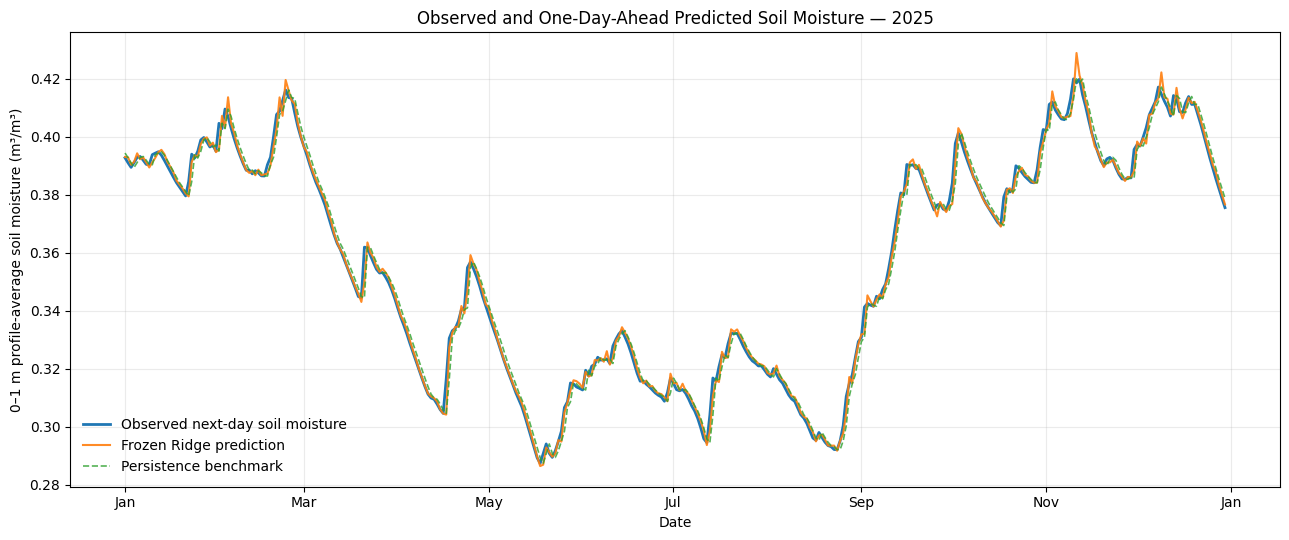

In [64]:
# ============================================================
# Figure 1
# Observed vs Predicted 0–1 m Profile Soil Moisture — 2025
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(
    figsize=(13, 5.5)
)

ax.plot(
    test_error_analysis["valid_time"],
    test_error_analysis[
        "target_next_day_soil_moisture"
    ],
    label="Observed next-day soil moisture",
    linewidth=2.0
)

ax.plot(
    test_error_analysis["valid_time"],
    test_error_analysis[
        "ridge_prediction"
    ],
    label="Frozen Ridge prediction",
    linewidth=1.5,
    alpha=0.9
)

ax.plot(
    test_error_analysis["valid_time"],
    test_error_analysis[
        "persistence_prediction"
    ],
    label="Persistence benchmark",
    linewidth=1.2,
    linestyle="--",
    alpha=0.8
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "0–1 m profile-average soil moisture (m³/m³)"
)

ax.set_title(
    "Observed and One-Day-Ahead Predicted Soil Moisture — 2025"
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

fig.tight_layout()

plt.show()

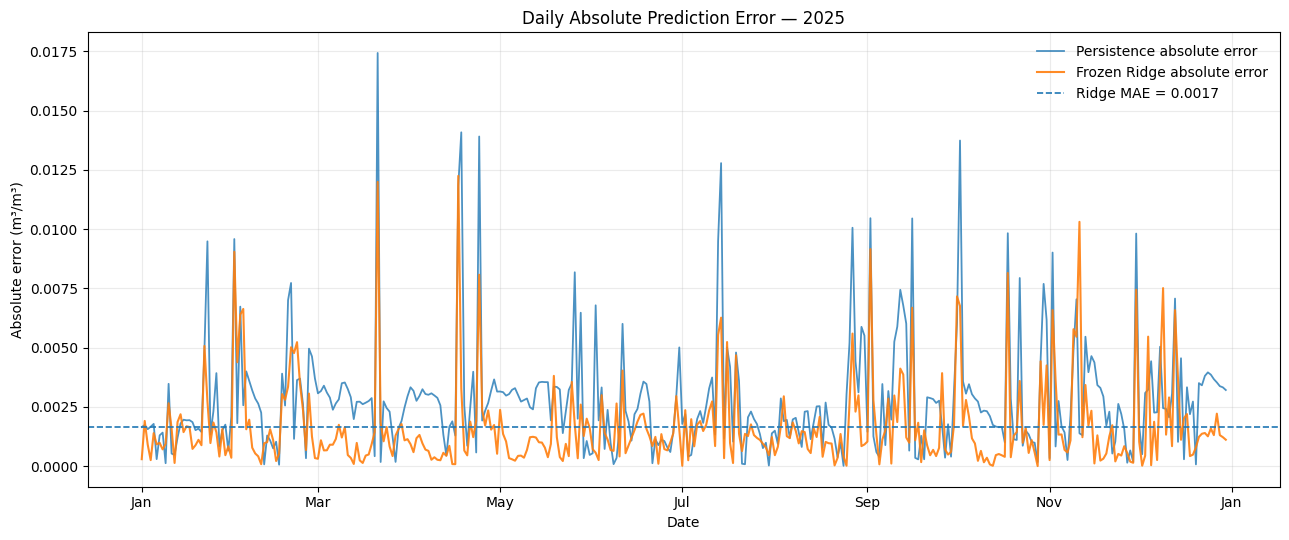

In [65]:
# ============================================================
# Figure 2
# Daily Absolute Prediction Error — 2025
# Frozen Ridge vs Persistence
# ============================================================

test_error_analysis[
    "persistence_absolute_error"
] = (
    test_error_analysis[
        "target_next_day_soil_moisture"
    ]
    - test_error_analysis[
        "persistence_prediction"
    ]
).abs()

fig, ax = plt.subplots(
    figsize=(13, 5.5)
)

ax.plot(
    test_error_analysis["valid_time"],
    test_error_analysis[
        "persistence_absolute_error"
    ],
    label="Persistence absolute error",
    linewidth=1.3,
    alpha=0.8
)

ax.plot(
    test_error_analysis["valid_time"],
    test_error_analysis[
        "absolute_ridge_error"
    ],
    label="Frozen Ridge absolute error",
    linewidth=1.5,
    alpha=0.9
)

ax.axhline(
    final_test_mae,
    linestyle="--",
    linewidth=1.2,
    label=f"Ridge MAE = {final_test_mae:.4f}"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Absolute error (m³/m³)"
)

ax.set_title(
    "Daily Absolute Prediction Error — 2025"
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

fig.tight_layout()

plt.show()

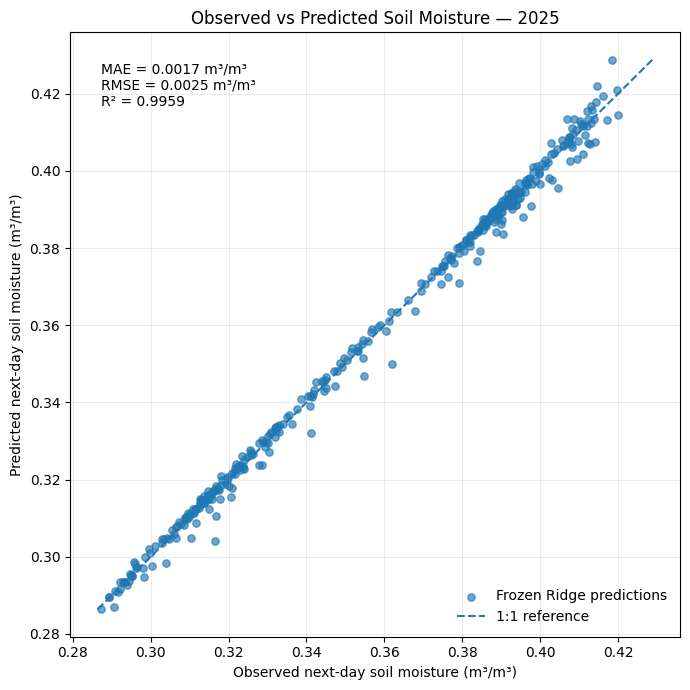

In [66]:
# ============================================================
# Figure 3
# Observed vs Predicted Soil Moisture — 2025
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.scatter(
    y_test,
    final_test_pred,
    alpha=0.65,
    s=28,
    label="Frozen Ridge predictions"
)

# 1:1 reference line
minimum_value = min(
    y_test.min(),
    final_test_pred.min()
)

maximum_value = max(
    y_test.max(),
    final_test_pred.max()
)

ax.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    linewidth=1.5,
    label="1:1 reference"
)

ax.set_xlabel(
    "Observed next-day soil moisture (m³/m³)"
)

ax.set_ylabel(
    "Predicted next-day soil moisture (m³/m³)"
)

ax.set_title(
    "Observed vs Predicted Soil Moisture — 2025"
)

ax.text(
    0.05,
    0.95,
    (
        f"MAE = {final_test_mae:.4f} m³/m³\n"
        f"RMSE = {final_test_rmse:.4f} m³/m³\n"
        f"R² = {final_test_r2:.4f}"
    ),
    transform=ax.transAxes,
    verticalalignment="top"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False,
    loc="lower right"
)

fig.tight_layout()

plt.show()

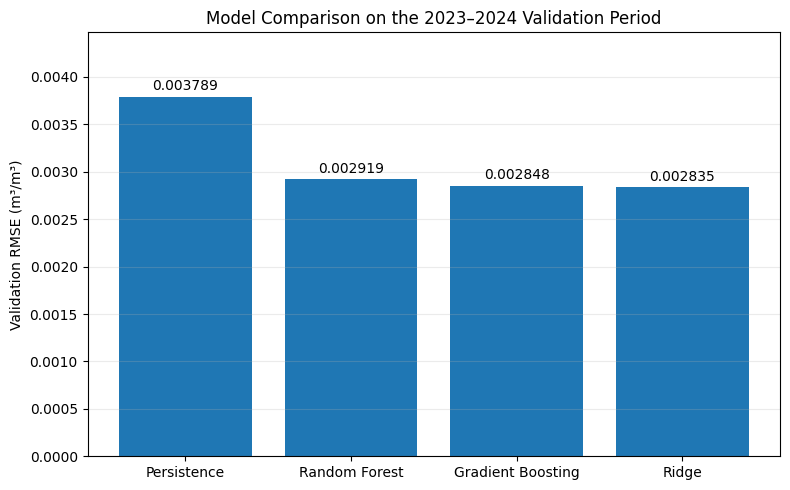

In [67]:
# ============================================================
# Figure 4
# Validation RMSE Comparison — 2023–2024
# Model Selection Stage
# ============================================================

validation_model_plot = pd.DataFrame(
    {
        "Model": [
            "Persistence",
            "Random Forest",
            "Gradient Boosting",
            "Ridge"
        ],
        "RMSE": [
            0.003789,
            0.002919,
            0.002848,
            0.002835
        ]
    }
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    validation_model_plot["Model"],
    validation_model_plot["RMSE"]
)

ax.set_ylabel(
    "Validation RMSE (m³/m³)"
)

ax.set_title(
    "Model Comparison on the 2023–2024 Validation Period"
)

ax.set_ylim(
    0,
    validation_model_plot["RMSE"].max() * 1.18
)

for bar, value in zip(
    bars,
    validation_model_plot["RMSE"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.00004,
        f"{value:.6f}",
        ha="center",
        va="bottom"
    )

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

plt.show()

In [68]:
# ============================================================
# Publication Table
# Final 2025 Held-Out Test Performance
# ============================================================

publication_test_table = pd.DataFrame(
    {
        "Model": [
            "Persistence benchmark",
            "Frozen Ridge regression"
        ],
        "MAE (m³/m³)": [
            persistence_test_mae,
            final_test_mae
        ],
        "RMSE (m³/m³)": [
            persistence_test_rmse,
            final_test_rmse
        ],
        "R²": [
            persistence_test_r2,
            final_test_r2
        ]
    }
)

publication_test_table[
    "RMSE reduction vs persistence (%)"
] = [
    0.0,
    rmse_improvement
]

publication_test_table[
    "MAE reduction vs persistence (%)"
] = [
    0.0,
    mae_improvement
]

display(
    publication_test_table.round(
        {
            "MAE (m³/m³)": 6,
            "RMSE (m³/m³)": 6,
            "R²": 4,
            "RMSE reduction vs persistence (%)": 2,
            "MAE reduction vs persistence (%)": 2
        }
    )
)

,Model,MAE (m³/m³),RMSE (m³/m³),R²,RMSE reduction vs persistence (%),MAE reduction vs persistence (%)
0,Persistence benchmark,0.002808,0.003707,0.9910,0.00,0.00
1,Frozen Ridge regression,0.001670,0.002492,0.9959,32.78,40.55


In [69]:
# ============================================================
# Stormwater-Harvesting Decision-Support Layer
# Step 1: Annual Rainfall Resource Characterisation
# ============================================================

rainfall_resource = (
    daily_climate
    .groupby("year")
    .agg(
        annual_precipitation_mm=(
            "precipitation_total_mm",
            "sum"
        ),
        wet_days_1mm=(
            "precipitation_total_mm",
            lambda x: (x >= 1.0).sum()
        ),
        heavy_rain_days_10mm=(
            "precipitation_total_mm",
            lambda x: (x >= 10.0).sum()
        ),
        max_daily_precipitation_mm=(
            "precipitation_total_mm",
            "max"
        )
    )
    .reset_index()
)

display(
    rainfall_resource.round(2)
)

print("\n2015–2025 rainfall-resource summary")

print(
    "Mean annual precipitation:",
    f"{rainfall_resource['annual_precipitation_mm'].mean():.1f} mm/year"
)

print(
    "Minimum annual precipitation:",
    f"{rainfall_resource['annual_precipitation_mm'].min():.1f} mm/year"
)

print(
    "Maximum annual precipitation:",
    f"{rainfall_resource['annual_precipitation_mm'].max():.1f} mm/year"
)

print(
    "Mean wet days (>=1 mm):",
    f"{rainfall_resource['wet_days_1mm'].mean():.1f} days/year"
)

print(
    "Mean heavy-rain days (>=10 mm):",
    f"{rainfall_resource['heavy_rain_days_10mm'].mean():.1f} days/year"
)

,year,annual_precipitation_mm,wet_days_1mm,heavy_rain_days_10mm,max_daily_precipitation_mm
0,2015,1325.34,192,37,38.18
1,2016,1001.70,186,19,33.08
2,2017,1024.08,183,24,30.22
3,2018,984.38,178,25,22.22
4,2019,1210.70,204,34,32.56
5,2020,1285.11,200,36,29.34
6,2021,1096.57,180,29,24.01
7,2022,1155.94,185,37,25.46
8,2023,1366.86,200,43,27.92
9,2024,1078.16,173,28,44.02



2015–2025 rainfall-resource summary
Mean annual precipitation: 1149.3 mm/year
Minimum annual precipitation: 984.4 mm/year
Maximum annual precipitation: 1366.9 mm/year
Mean wet days (>=1 mm): 187.6 days/year
Mean heavy-rain days (>=10 mm): 31.5 days/year


In [70]:
# ============================================================
# Rainfall Event Distribution
# Descriptive analysis for harvesting decision-support
# ============================================================

rain = daily_climate["precipitation_total_mm"]

# Mutually exclusive daily rainfall classes
rainfall_event_classes = pd.DataFrame({
    "Rainfall class": [
        "Dry / trace (<0.1 mm)",
        "Light (0.1–<1 mm)",
        "Moderate (1–<5 mm)",
        "High (5–<10 mm)",
        "Very high (>=10 mm)"
    ],
    "Number of days": [
        (rain < 0.1).sum(),
        ((rain >= 0.1) & (rain < 1.0)).sum(),
        ((rain >= 1.0) & (rain < 5.0)).sum(),
        ((rain >= 5.0) & (rain < 10.0)).sum(),
        (rain >= 10.0).sum()
    ]
})

rainfall_event_classes["Percentage of days"] = (
    rainfall_event_classes["Number of days"]
    / len(daily_climate)
    * 100
)

display(rainfall_event_classes.round(2))

print("\nTotal days:", len(daily_climate))
print(
    "Classified days:",
    rainfall_event_classes["Number of days"].sum()
)

# ------------------------------------------------------------
# How much of TOTAL rainfall comes from each class?
# ------------------------------------------------------------

rainfall_volume_by_class = pd.DataFrame({
    "Rainfall class": rainfall_event_classes["Rainfall class"],
    "Total rainfall (mm)": [
        rain[rain < 0.1].sum(),
        rain[(rain >= 0.1) & (rain < 1.0)].sum(),
        rain[(rain >= 1.0) & (rain < 5.0)].sum(),
        rain[(rain >= 5.0) & (rain < 10.0)].sum(),
        rain[rain >= 10.0].sum()
    ]
})

total_rainfall = rain.sum()

rainfall_volume_by_class["Share of total rainfall (%)"] = (
    rainfall_volume_by_class["Total rainfall (mm)"]
    / total_rainfall
    * 100
)

display(rainfall_volume_by_class.round(2))

print(
    "\nTotal precipitation across 2015–2025:",
    f"{total_rainfall:.2f} mm"
)

print(
    "Rainfall supplied by >=10 mm days:",
    f"{rain[rain >= 10].sum():.2f} mm"
)

print(
    "Share supplied by >=10 mm days:",
    f"{rain[rain >= 10].sum() / total_rainfall * 100:.2f}%"
)

,Rainfall class,Number of days,Percentage of days
0,Dry / trace (<0.1 mm),850,21.15
1,Light (0.1–<1 mm),1104,27.48
2,Moderate (1–<5 mm),1169,29.09
3,High (5–<10 mm),548,13.64
4,Very high (>=10 mm),347,8.64



Total days: 4018
Classified days: 4018


,Rainfall class,Total rainfall (mm),Share of total rainfall (%)
0,Dry / trace (<0.1 mm),19.84,0.16
1,Light (0.1–<1 mm),481.26,3.81
2,Moderate (1–<5 mm),3014.52,23.84
3,High (5–<10 mm),3899.26,30.84
4,Very high (>=10 mm),5227.40,41.35



Total precipitation across 2015–2025: 12642.28 mm
Rainfall supplied by >=10 mm days: 5227.40 mm
Share supplied by >=10 mm days: 41.35%


In [71]:
# ============================================================
# Consecutive Wet-Spell Analysis
# Exploratory threshold: >= 5 mm/day
# ============================================================

wet_spell_data = (
    daily_climate[
        ["valid_time", "precipitation_total_mm"]
    ]
    .copy()
    .sort_values("valid_time")
    .reset_index(drop=True)
)

WET_DAY_THRESHOLD_MM = 5.0

wet_spell_data["is_wet_day"] = (
    wet_spell_data["precipitation_total_mm"]
    >= WET_DAY_THRESHOLD_MM
)

# New group whenever wet/dry status changes
wet_spell_data["group_id"] = (
    wet_spell_data["is_wet_day"]
    != wet_spell_data["is_wet_day"].shift()
).cumsum()

# Keep only consecutive wet-day groups
wet_spells = (
    wet_spell_data[
        wet_spell_data["is_wet_day"]
    ]
    .groupby("group_id")
    .agg(
        start_date=("valid_time", "min"),
        end_date=("valid_time", "max"),
        duration_days=("valid_time", "size"),
        total_precipitation_mm=("precipitation_total_mm", "sum"),
        max_daily_precipitation_mm=("precipitation_total_mm", "max")
    )
    .reset_index(drop=True)
)

print("Wet-day threshold:", WET_DAY_THRESHOLD_MM, "mm/day")
print("Number of wet spells:", len(wet_spells))

print(
    "Median wet-spell duration:",
    f"{wet_spells['duration_days'].median():.1f} days"
)

print(
    "Maximum wet-spell duration:",
    wet_spells["duration_days"].max(),
    "days"
)

print(
    "Median precipitation per wet spell:",
    f"{wet_spells['total_precipitation_mm'].median():.2f} mm"
)

print(
    "Maximum precipitation in one wet spell:",
    f"{wet_spells['total_precipitation_mm'].max():.2f} mm"
)

print("\nTop 15 wet spells by total precipitation:")

display(
    wet_spells
    .sort_values(
        "total_precipitation_mm",
        ascending=False
    )
    .head(15)
    .round(2)
)

Wet-day threshold: 5.0 mm/day
Number of wet spells: 557
Median wet-spell duration: 1.0 days
Maximum wet-spell duration: 6 days
Median precipitation per wet spell: 12.08 mm
Maximum precipitation in one wet spell: 80.19 mm

Top 15 wet spells by total precipitation:


,start_date,end_date,duration_days,total_precipitation_mm,max_daily_precipitation_mm
52,2015-12-03,2015-12-07,5,80.19,38.18
260,2020-02-19,2020-02-24,6,78.64,20.83
375,2022-06-24,2022-06-28,5,71.76,25.28
361,2022-02-15,2022-02-20,6,67.46,15.78
113,2017-03-02,2017-03-07,6,64.60,24.68
454,2023-12-06,2023-12-11,6,63.09,13.90
309,2021-01-30,2021-02-03,5,54.87,16.36
257,2020-02-07,2020-02-09,3,53.49,25.61
411,2023-03-20,2023-03-24,5,52.63,18.78
405,2023-01-10,2023-01-13,4,52.23,19.84


In [72]:
# Check existing modelling variables without changing anything

keywords = [
    "train", "val", "test",
    "ridge", "rf", "gb",
    "model", "ready"
]

existing_vars = sorted([
    name for name in globals()
    if any(key in name.lower() for key in keywords)
    and not name.startswith("_")
])

print("Existing modelling-related variables:\n")
for name in existing_vars:
    try:
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        if shape is not None:
            print(f"{name:<35} shape = {shape}")
        else:
            print(f"{name:<35} type = {type(obj).__name__}")
    except Exception:
        print(name)

Existing modelling-related variables:

Ridge                               type = ABCMeta
TRAIN_RAIN_QUANTILE                 type = float
X_test                              shape = (364, 10)
X_test_lstm                         shape = (351, 14, 5)
X_train                             shape = (2914, 10)
X_train_2d                          shape = (40712, 5)
X_train_ablation                    shape = (2914, 10)
X_train_gb                          shape = (2914, 10)
X_train_lstm                        shape = (2908, 14, 5)
X_train_lstm_scaled                 shape = (2908, 14, 5)
X_train_rf                          shape = (2914, 10)
X_train_tune                        shape = (2914, 10)
X_val                               shape = (730, 10)
X_val_ablation                      shape = (730, 10)
X_val_lstm                          shape = (717, 14, 5)
X_val_lstm_scaled                   shape = (717, 14, 5)
X_val_rf                            shape = (730, 10)
X_validation                

In [73]:
# ============================================================
# PUBLICATION METHODS AUDIT — MODEL DEVELOPMENT
# Read-only audit: does NOT train, tune, or modify models
# ============================================================

print("=" * 72)
print("PUBLICATION METHODS AUDIT — MODEL DEVELOPMENT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Prediction task and dataset split
# ------------------------------------------------------------
print("\n1. PREDICTION TASK")
print("End-of-day t -> next-day t+1 profile-average soil moisture")

print("\n2. CHRONOLOGICAL DATA SPLIT")
print(f"Training observations   : {len(train_data)}")
print(f"Validation observations : {len(validation_data)}")
print(f"Final test observations : {len(test_data)}")

print("\nTabular predictor dimensions:")
print(f"X_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"X_test  : {X_test.shape}")


# ------------------------------------------------------------
# 2. Final validation comparison
# ------------------------------------------------------------
print("\n3. FINAL VALIDATION COMPARISON")
print(final_validation_results.to_string(index=False))


# ------------------------------------------------------------
# 3. Ridge Regression
# ------------------------------------------------------------
print("\n4. RIDGE REGRESSION")

print("\nParameter grid:")
print(ridge_param_grid)

print("\nBest parameters:")
print(ridge_grid.best_params_)

print("\nBest training-only TimeSeriesSplit CV score:")
print(ridge_grid.best_score_)

print("\nTuned Ridge validation metrics:")
print(f"MAE  : {float(tuned_ridge_mae):.6f}")
print(f"RMSE : {float(tuned_ridge_rmse):.6f}")
print(f"R2   : {float(tuned_ridge_r2):.6f}")


# ------------------------------------------------------------
# 4. Random Forest
# ------------------------------------------------------------
print("\n5. RANDOM FOREST")

print("\nParameter grid:")
print(rf_param_grid)

print("\nBest parameters:")
print(rf_grid.best_params_)

print("\nBest training-only TimeSeriesSplit CV score:")
print(rf_grid.best_score_)


# ------------------------------------------------------------
# 5. Gradient Boosting
# ------------------------------------------------------------
print("\n6. GRADIENT BOOSTING")

print("\nParameter grid:")
print(gb_param_grid)

print("\nBest parameters:")
print(gb_grid.best_params_)

print("\nBest training-only TimeSeriesSplit CV score:")
print(gb_grid.best_score_)


# ------------------------------------------------------------
# 6. LSTM
# ------------------------------------------------------------
print("\n7. LSTM EXPERIMENT")

print(f"Training sequences   : {X_train_lstm.shape}")
print(f"Validation sequences : {X_val_lstm.shape}")
print(f"Test sequences       : {X_test_lstm.shape}")

print("\nLSTM model architecture:")
lstm_model.summary()

print("\nSame-date validation comparison:")
print(f"Number of common validation dates : {len(y_val_lstm)}")

print(f"Persistence MAE  : {float(persistence_same_mae):.6f}"
      if 'persistence_same_mae' in globals()
      else "Persistence same-date MAE variable not found")

print(f"Persistence RMSE : {float(persistence_same_rmse):.6f}"
      if 'persistence_same_rmse' in globals()
      else "Persistence same-date RMSE variable not found")

print(f"Ridge MAE        : {float(ridge_same_mae):.6f}")
print(f"Ridge RMSE       : {float(ridge_same_rmse):.6f}")
print(f"Ridge R2         : {float(ridge_same_r2):.6f}")

if 'lstm_mae' in globals():
    print(f"LSTM MAE         : {float(lstm_mae):.6f}")

if 'lstm_rmse' in globals():
    print(f"LSTM RMSE        : {float(lstm_rmse):.6f}")

if 'lstm_r2' in globals():
    print(f"LSTM R2          : {float(lstm_r2):.6f}")


# ------------------------------------------------------------
# 7. Final selected model
# ------------------------------------------------------------
print("\n8. FINAL SELECTED MODEL")

print("Final model object:")
print(final_ridge_model)

print("\nFinal model status:")
print("FROZEN")

print(
    "No further model architecture, feature-set, or "
    "hyperparameter selection after model selection."
)

print(
    "The 2025 period is reserved for final held-out "
    "model evaluation."
)

print("\n" + "=" * 72)
print("AUDIT COMPLETE")
print("=" * 72)

PUBLICATION METHODS AUDIT — MODEL DEVELOPMENT

1. PREDICTION TASK
End-of-day t -> next-day t+1 profile-average soil moisture

2. CHRONOLOGICAL DATA SPLIT
Training observations   : 2914
Validation observations : 730
Final test observations : 364

Tabular predictor dimensions:
X_train : (2914, 10)
X_val   : (730, 10)
X_test  : (364, 10)

3. FINAL VALIDATION COMPARISON
                  Model      MAE     RMSE       R2
            Tuned Ridge 0.001851 0.002835 0.992825
Tuned Gradient Boosting 0.001894 0.002848 0.992754
    Tuned Random Forest 0.001945 0.002919 0.992390
            Persistence 0.002806 0.003789 0.987176

4. RIDGE REGRESSION

Parameter grid:
{'ridge__alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0]}

Best parameters:
{'ridge__alpha': 0.001}

Best training-only TimeSeriesSplit CV score:
-0.0026401006718460222

Tuned Ridge validation metrics:
MAE  : 0.001851
RMSE : 0.002835
R2   : 0.992825

5. RANDOM FOREST

Parameter grid:
{'n_estimators': [200, 400], 'max_d

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,229 (63.40 KB)

 Trainable params: 5,409 (21.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,820 (42.27 KB)


Same-date validation comparison:
Number of common validation dates : 717
Persistence MAE  : 0.002802
Persistence RMSE : 0.003795
Ridge MAE        : 0.001845
Ridge RMSE       : 0.002816
Ridge R2         : 0.992846
LSTM MAE         : 0.003372
LSTM RMSE        : 0.004528
LSTM R2          : 0.981498

8. FINAL SELECTED MODEL
Final model object:
Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.001))])

Final model status:
FROZEN
No further model architecture, feature-set, or hyperparameter selection after model selection.
The 2025 period is reserved for final held-out model evaluation.

AUDIT COMPLETE


In [74]:
# ============================================================
# PUBLICATION AUDIT — HYPERPARAMETER & MODEL SELECTION
# Read-only verification for Section III-F
# ============================================================

print("=" * 72)
print("HYPERPARAMETER AND MODEL-SELECTION AUDIT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Time-series cross-validation configuration
# ------------------------------------------------------------
print("\n1. TIME-SERIES CROSS-VALIDATION")

for name, obj in [
    ("Ridge", getattr(ridge_grid, "cv", None)),
    ("Random Forest", getattr(rf_grid, "cv", None)),
    ("Gradient Boosting", getattr(gb_grid, "cv", None))
]:
    print(f"\n{name}:")
    print("CV object:", obj)

    if hasattr(obj, "n_splits"):
        print("Number of splits:", obj.n_splits)

    if hasattr(obj, "gap"):
        print("Gap:", obj.gap)

    if hasattr(obj, "test_size"):
        print("Test size:", obj.test_size)

    if hasattr(obj, "max_train_size"):
        print("Maximum train size:", obj.max_train_size)


# ------------------------------------------------------------
# 2. Scoring criterion used during tuning
# ------------------------------------------------------------
print("\n2. GRID-SEARCH SCORING")

print("Ridge scoring            :", ridge_grid.scoring)
print("Random Forest scoring    :", rf_grid.scoring)
print("Gradient Boosting scoring:", gb_grid.scoring)


# ------------------------------------------------------------
# 3. Best hyperparameters and CV scores
# ------------------------------------------------------------
print("\n3. SELECTED HYPERPARAMETERS")

for name, grid in [
    ("Ridge", ridge_grid),
    ("Random Forest", rf_grid),
    ("Gradient Boosting", gb_grid)
]:
    print(f"\n{name}")
    print("Best parameters :", grid.best_params_)
    print("Best CV score   :", grid.best_score_)


# ------------------------------------------------------------
# 4. Validation-period model comparison
# ------------------------------------------------------------
print("\n4. VALIDATION-PERIOD MODEL COMPARISON")
print(final_validation_results.to_string(index=False))


# ------------------------------------------------------------
# 5. Ridge versus Gradient Boosting difference
# ------------------------------------------------------------
ridge_row = final_validation_results[
    final_validation_results["Model"] == "Tuned Ridge"
].iloc[0]

gb_row = final_validation_results[
    final_validation_results["Model"] == "Tuned Gradient Boosting"
].iloc[0]

rmse_difference = float(gb_row["RMSE"] - ridge_row["RMSE"])

relative_difference_pct = (
    rmse_difference / float(ridge_row["RMSE"])
) * 100

print("\n5. RIDGE vs GRADIENT BOOSTING")
print(f"Ridge validation RMSE              : {ridge_row['RMSE']:.6f}")
print(f"Gradient Boosting validation RMSE  : {gb_row['RMSE']:.6f}")
print(f"Absolute RMSE difference           : {rmse_difference:.8f}")
print(f"Relative difference                : {relative_difference_pct:.4f}%")


# ------------------------------------------------------------
# 6. Selected final model
# ------------------------------------------------------------
print("\n6. MODEL-SELECTION DECISION")
print("Selected model: Ridge Regression")
print("Selected alpha:", final_ridge_model.named_steps["ridge"].alpha)

print("\nFinal pipeline:")
print(final_ridge_model)

print("\nModel-selection status: FROZEN BEFORE FINAL 2025 MODEL EVALUATION")

print("\n" + "=" * 72)
print("AUDIT COMPLETE")
print("=" * 72)

HYPERPARAMETER AND MODEL-SELECTION AUDIT

1. TIME-SERIES CROSS-VALIDATION

Ridge:
CV object: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
Number of splits: 5
Gap: 0
Test size: None
Maximum train size: None

Random Forest:
CV object: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
Number of splits: 5
Gap: 0
Test size: None
Maximum train size: None

Gradient Boosting:
CV object: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
Number of splits: 5
Gap: 0
Test size: None
Maximum train size: None

2. GRID-SEARCH SCORING
Ridge scoring            : neg_root_mean_squared_error
Random Forest scoring    : neg_root_mean_squared_error
Gradient Boosting scoring: neg_root_mean_squared_error

3. SELECTED HYPERPARAMETERS

Ridge
Best parameters : {'ridge__alpha': 0.001}
Best CV score   : -0.0026401006718460222

Random Forest
Best parameters : {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV score   : -0.005

In [75]:
# ============================================================
# PUBLICATION AUDIT — EVALUATION METRICS & UNCERTAINTY
# Read-only verification for Section III-G
# ============================================================

print("=" * 72)
print("EVALUATION METRICS AND UNCERTAINTY AUDIT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Final held-out test metrics
# ------------------------------------------------------------
print("\n1. FINAL 2025 HELD-OUT TEST RESULTS")
print(publication_test_table.to_string(index=False))


# ------------------------------------------------------------
# 2. Direct metric variables
# ------------------------------------------------------------
print("\n2. FINAL RIDGE METRICS")
print(f"MAE  : {float(final_test_mae):.9f}")
print(f"RMSE : {float(final_test_rmse):.9f}")
print(f"R2   : {float(final_test_r2):.9f}")

print("\n3. PERSISTENCE BENCHMARK METRICS")
print(f"MAE  : {float(persistence_test_mae):.9f}")
print(f"RMSE : {float(persistence_test_rmse):.9f}")
print(f"R2   : {float(persistence_test_r2):.9f}")


# ------------------------------------------------------------
# 3. Recalculate percentage improvements from stored results
# ------------------------------------------------------------
mae_improvement = (
    (float(persistence_test_mae) - float(final_test_mae))
    / float(persistence_test_mae)
) * 100

rmse_improvement = (
    (float(persistence_test_rmse) - float(final_test_rmse))
    / float(persistence_test_rmse)
) * 100

print("\n4. IMPROVEMENT RELATIVE TO PERSISTENCE")
print(f"MAE reduction  : {mae_improvement:.6f}%")
print(f"RMSE reduction : {rmse_improvement:.6f}%")


# ------------------------------------------------------------
# 4. Bootstrap uncertainty
# ------------------------------------------------------------
print("\n5. MOVING-BLOCK BOOTSTRAP")

if "n_boot" in globals():
    print("Bootstrap repetitions :", n_boot)
else:
    print("Bootstrap repetitions : variable 'n_boot' not found")

if "block_size" in globals():
    print("Block length          :", block_size)
elif "block_length" in globals():
    print("Block length          :", block_length)
else:
    print("Block length          : variable not found")

if "ridge_ci" in globals():
    print(
        "Ridge RMSE 95% CI     : "
        f"[{float(ridge_ci[0]):.9f}, {float(ridge_ci[1]):.9f}]"
    )

if "persistence_ci" in globals():
    print(
        "Persistence RMSE 95% CI: "
        f"[{float(persistence_ci[0]):.9f}, "
        f"{float(persistence_ci[1]):.9f}]"
    )
else:
    print("Persistence RMSE CI variable not found")

# Search existing variables for the improvement CI rather than
# assuming its variable name.
possible_improvement_ci = [
    name for name in globals()
    if "ci" in name.lower()
    and ("improv" in name.lower() or "reduction" in name.lower())
]

print("\nPossible improvement-CI variables:")
print(possible_improvement_ci)

for name in possible_improvement_ci:
    try:
        print(f"{name}: {globals()[name]}")
    except Exception:
        pass


# ------------------------------------------------------------
# 5. Bootstrap arrays / stored results
# ------------------------------------------------------------
print("\n6. STORED BOOTSTRAP OBJECTS")

bootstrap_names = sorted([
    name for name in globals()
    if "boot" in name.lower()
])

for name in bootstrap_names:
    try:
        obj = globals()[name]
        shape = getattr(obj, "shape", None)

        if shape is not None:
            print(f"{name:<35} shape = {shape}")
        elif isinstance(obj, (list, tuple)):
            print(f"{name:<35} length = {len(obj)}")
        else:
            print(f"{name:<35} type = {type(obj).__name__}")
    except Exception:
        print(name)


# ------------------------------------------------------------
# 6. Confirm final sample size
# ------------------------------------------------------------
print("\n7. FINAL TEST SAMPLE")
print(f"Number of 2025 predictions : {len(final_test_pred)}")
print(f"Number of 2025 targets     : {len(y_test)}")


print("\n" + "=" * 72)
print("AUDIT COMPLETE")
print("=" * 72)

EVALUATION METRICS AND UNCERTAINTY AUDIT

1. FINAL 2025 HELD-OUT TEST RESULTS
                  Model  MAE (m³/m³)  RMSE (m³/m³)       R²  RMSE reduction vs persistence (%)  MAE reduction vs persistence (%)
  Persistence benchmark     0.002808      0.003707 0.991007                           0.000000                          0.000000
Frozen Ridge regression     0.001670      0.002492 0.995937                          32.782033                         40.546735

2. FINAL RIDGE METRICS
MAE  : 0.001669578
RMSE : 0.002491941
R2   : 0.995936746

3. PERSISTENCE BENCHMARK METRICS
MAE  : 0.002808220
RMSE : 0.003707254
R2   : 0.991007030

4. IMPROVEMENT RELATIVE TO PERSISTENCE
MAE reduction  : 40.546735%
RMSE reduction : 32.782033%

5. MOVING-BLOCK BOOTSTRAP
Bootstrap repetitions : variable 'n_boot' not found
Block length          : 30
Ridge RMSE 95% CI     : [0.002117094, 0.002868669]
Persistence RMSE 95% CI: [0.003269337, 0.004174733]

Possible improvement-CI variables:
['improvement_ci']
imp

In [76]:
print("\n5. MOVING-BLOCK BOOTSTRAP")

print("Bootstrap repetitions :", N_BOOTSTRAPS)
print("Block length          :", BLOCK_LENGTH, "days")
print("Random seed           :", BOOTSTRAP_SEED)

print(
    "Ridge RMSE 95% CI     : "
    f"[{float(ridge_ci[0]):.9f}, {float(ridge_ci[1]):.9f}]"
)

print(
    "Persistence RMSE 95% CI: "
    f"[{float(persistence_ci[0]):.9f}, "
    f"{float(persistence_ci[1]):.9f}]"
)

print(
    "RMSE reduction 95% CI : "
    f"[{float(improvement_ci[0]):.6f}%, "
    f"{float(improvement_ci[1]):.6f}%]"
)


5. MOVING-BLOCK BOOTSTRAP
Bootstrap repetitions : 2000
Block length          : 7 days
Random seed           : 42
Ridge RMSE 95% CI     : [0.002117094, 0.002868669]
Persistence RMSE 95% CI: [0.003269337, 0.004174733]
RMSE reduction 95% CI : [26.267332%, 38.821779%]


In [77]:
# ============================================================
# Stormwater-Harvesting Decision-Support Layer
# Step 2: Harvestable Runoff Scenarios
# ============================================================

import itertools
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Transparent design scenarios
# These are hypothetical sensitivity scenarios, not measured
# properties of a specific agricultural building.
# ------------------------------------------------------------

CATCHMENT_AREAS_M2 = [
    100,
    250,
    500,
    1000
]

EFFECTIVE_COLLECTION_COEFFICIENTS = [
    0.60,  # conservative
    0.75,  # intermediate
    0.90   # favourable
]

coefficient_labels = {
    0.60: "Conservative",
    0.75: "Intermediate",
    0.90: "Favourable"
}

# ------------------------------------------------------------
# Create scenario combinations
# ------------------------------------------------------------

harvesting_scenarios = pd.DataFrame(
    itertools.product(
        CATCHMENT_AREAS_M2,
        EFFECTIVE_COLLECTION_COEFFICIENTS
    ),
    columns=[
        "catchment_area_m2",
        "effective_collection_coefficient"
    ]
)

harvesting_scenarios["scenario"] = (
    harvesting_scenarios[
        "effective_collection_coefficient"
    ].map(coefficient_labels)
)

print("Number of harvesting scenarios:",
      len(harvesting_scenarios))

display(harvesting_scenarios)

Number of harvesting scenarios: 12


,catchment_area_m2,effective_collection_coefficient,scenario
0,100,0.60,Conservative
1,100,0.75,Intermediate
2,100,0.90,Favourable
3,250,0.60,Conservative
4,250,0.75,Intermediate
5,250,0.90,Favourable
6,500,0.60,Conservative
7,500,0.75,Intermediate
8,500,0.90,Favourable
9,1000,0.60,Conservative


In [78]:
# ============================================================
# Daily Harvestable Rainwater Calculation
# ============================================================

# One millimetre of rainfall falling on one square metre
# corresponds to one litre of water.
#
# Harvestable volume:
# V (m³) = P (mm) × A (m²) × C_eff / 1000

rainfall_for_harvesting = daily_climate[
    [
        "valid_time",
        "year",
        "precipitation_total_mm"
    ]
].copy()

# Cross-join every daily rainfall observation
# with every design scenario
daily_harvest = (
    rainfall_for_harvesting.assign(join_key=1)
    .merge(
        harvesting_scenarios.assign(join_key=1),
        on="join_key",
        how="inner"
    )
    .drop(columns="join_key")
)

daily_harvest["harvestable_volume_m3"] = (
    daily_harvest["precipitation_total_mm"]
    * daily_harvest["catchment_area_m2"]
    * daily_harvest[
        "effective_collection_coefficient"
    ]
    / 1000
)

daily_harvest["harvestable_volume_litres"] = (
    daily_harvest["harvestable_volume_m3"]
    * 1000
)

print("Daily scenario dataset shape:",
      daily_harvest.shape)

print(
    "Missing values:",
    daily_harvest.isna().sum().sum()
)

print(
    "Negative harvested volumes:",
    (
        daily_harvest["harvestable_volume_m3"]
        < 0
    ).sum()
)

display(daily_harvest.head())

Daily scenario dataset shape: (48216, 8)
Missing values: 0
Negative harvested volumes: 0


,valid_time,year,precipitation_total_mm,catchment_area_m2,effective_collection_coefficient,scenario,harvestable_volume_m3,harvestable_volume_litres
0,2015-01-01,2015,11.467695,100,0.60,Conservative,0.688062,688.061714
1,2015-01-01,2015,11.467695,100,0.75,Intermediate,0.860077,860.077143
2,2015-01-01,2015,11.467695,100,0.90,Favourable,1.032093,1032.092572
3,2015-01-01,2015,11.467695,250,0.60,Conservative,1.720154,1720.154286
4,2015-01-01,2015,11.467695,250,0.75,Intermediate,2.150193,2150.192858


In [79]:
# ============================================================
# Annual Harvestable Rainwater by Scenario
# ============================================================

annual_harvest = (
    daily_harvest
    .groupby(
        [
            "year",
            "catchment_area_m2",
            "effective_collection_coefficient",
            "scenario"
        ],
        as_index=False
    )
    .agg(
        annual_rainfall_mm=(
            "precipitation_total_mm",
            "sum"
        ),
        annual_harvestable_volume_m3=(
            "harvestable_volume_m3",
            "sum"
        )
    )
)

scenario_harvest_summary = (
    annual_harvest
    .groupby(
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "scenario"
        ],
        as_index=False
    )
    .agg(
        mean_annual_harvest_m3=(
            "annual_harvestable_volume_m3",
            "mean"
        ),
        minimum_annual_harvest_m3=(
            "annual_harvestable_volume_m3",
            "min"
        ),
        maximum_annual_harvest_m3=(
            "annual_harvestable_volume_m3",
            "max"
        ),
        standard_deviation_m3=(
            "annual_harvestable_volume_m3",
            "std"
        )
    )
)

print("ANNUAL HARVESTABLE RAINWATER SCENARIOS")

display(
    scenario_harvest_summary.round(2)
)

ANNUAL HARVESTABLE RAINWATER SCENARIOS


,catchment_area_m2,effective_collection_coefficient,scenario,mean_annual_harvest_m3,minimum_annual_harvest_m3,maximum_annual_harvest_m3,standard_deviation_m3
0,100,0.60,Conservative,68.96,59.06,82.01,7.92
1,100,0.75,Intermediate,86.20,73.83,102.51,9.90
2,100,0.90,Favourable,103.44,88.59,123.02,11.88
3,250,0.60,Conservative,172.39,147.66,205.03,19.81
4,250,0.75,Intermediate,215.49,184.57,256.29,24.76
5,250,0.90,Favourable,258.59,221.48,307.54,29.71
6,500,0.60,Conservative,344.79,295.31,410.06,39.62
7,500,0.75,Intermediate,430.99,369.14,512.57,49.52
8,500,0.90,Favourable,517.18,442.97,615.09,59.42
9,1000,0.60,Conservative,689.58,590.63,820.12,79.23


In [80]:
# ============================================================
# Stormwater-Harvesting Decision-Support Layer
# Step 3: Storage-Capacity and Water-Demand Scenarios
# ============================================================

import itertools
import pandas as pd

# ------------------------------------------------------------
# Hypothetical non-potable agricultural water-demand scenarios
# These do not represent measured demand at a specific farm.
# ------------------------------------------------------------

DAILY_DEMAND_SCENARIOS_M3 = {
    "Low demand": 0.25,
    "Moderate demand": 0.50,
    "High demand": 1.00,
    "Very high demand": 2.00
}

# Hypothetical storage-capacity scenarios
TANK_CAPACITIES_M3 = [
    1,
    5,
    10,
    20,
    50
]

# ------------------------------------------------------------
# Create demand and storage combinations
# ------------------------------------------------------------

storage_demand_scenarios = pd.DataFrame(
    [
        {
            "demand_scenario": demand_name,
            "daily_demand_m3": daily_demand,
            "daily_demand_litres": daily_demand * 1000,
            "tank_capacity_m3": tank_capacity
        }
        for (
            demand_name,
            daily_demand
        ), tank_capacity in itertools.product(
            DAILY_DEMAND_SCENARIOS_M3.items(),
            TANK_CAPACITIES_M3
        )
    ]
)

print(
    "Number of storage-demand combinations:",
    len(storage_demand_scenarios)
)

display(storage_demand_scenarios)

Number of storage-demand combinations: 20


,demand_scenario,daily_demand_m3,daily_demand_litres,tank_capacity_m3
0,Low demand,0.25,250.0,1
1,Low demand,0.25,250.0,5
2,Low demand,0.25,250.0,10
3,Low demand,0.25,250.0,20
4,Low demand,0.25,250.0,50
5,Moderate demand,0.50,500.0,1
6,Moderate demand,0.50,500.0,5
7,Moderate demand,0.50,500.0,10
8,Moderate demand,0.50,500.0,20
9,Moderate demand,0.50,500.0,50


In [81]:
# ============================================================
# Stormwater-Harvesting Decision-Support Layer
# Step 4: Continuous Daily Tank Water-Balance Simulation
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Simulation assumptions
# ------------------------------------------------------------

SPIN_UP_END_YEAR = 2015
EVALUATION_START_YEAR = 2016

simulation_results = []

# Group daily inflow by harvesting scenario
harvest_groups = daily_harvest.groupby(
    [
        "catchment_area_m2",
        "effective_collection_coefficient",
        "scenario"
    ]
)

for (
    catchment_area,
    collection_coefficient,
    collection_scenario
), harvest_group in harvest_groups:

    harvest_group = (
        harvest_group
        .sort_values("valid_time")
        .reset_index(drop=True)
    )

    # Evaluate every demand and tank combination
    for _, design_row in (
        storage_demand_scenarios.iterrows()
    ):

        demand_scenario = design_row[
            "demand_scenario"
        ]

        daily_demand = float(
            design_row["daily_demand_m3"]
        )

        tank_capacity = float(
            design_row["tank_capacity_m3"]
        )

        # Tank starts empty
        storage = 0.0

        evaluation_records = []

        for _, day in harvest_group.iterrows():

            date = day["valid_time"]

            inflow = float(
                day["harvestable_volume_m3"]
            )

            # --------------------------------------------
            # Daily water balance
            # 1. Rainwater enters the tank
            # 2. Excess water becomes overflow
            # 3. Daily demand is withdrawn
            # --------------------------------------------

            available_before_overflow = (
                storage + inflow
            )

            overflow = max(
                available_before_overflow
                - tank_capacity,
                0.0
            )

            storage = min(
                available_before_overflow,
                tank_capacity
            )

            water_supplied = min(
                storage,
                daily_demand
            )

            unmet_demand = (
                daily_demand
                - water_supplied
            )

            storage = (
                storage
                - water_supplied
            )

            # Use 2015 only to initialise tank behaviour
            if date.year >= EVALUATION_START_YEAR:

                evaluation_records.append(
                    {
                        "valid_time": date,
                        "inflow_m3": inflow,
                        "demand_m3": daily_demand,
                        "water_supplied_m3": (
                            water_supplied
                        ),
                        "unmet_demand_m3": (
                            unmet_demand
                        ),
                        "overflow_m3": overflow,
                        "end_storage_m3": storage
                    }
                )

        evaluation = pd.DataFrame(
            evaluation_records
        )

        total_inflow = (
            evaluation["inflow_m3"].sum()
        )

        total_demand = (
            evaluation["demand_m3"].sum()
        )

        total_supplied = (
            evaluation[
                "water_supplied_m3"
            ].sum()
        )

        total_unmet = (
            evaluation[
                "unmet_demand_m3"
            ].sum()
        )

        total_overflow = (
            evaluation["overflow_m3"].sum()
        )

        fully_supplied_days = (
            evaluation["unmet_demand_m3"]
            <= 1e-12
        ).sum()

        number_of_days = len(evaluation)

        # --------------------------------------------
        # Performance indicators
        # --------------------------------------------

        daily_reliability_pct = (
            fully_supplied_days
            / number_of_days
            * 100
        )

        volumetric_reliability_pct = (
            total_supplied
            / total_demand
            * 100
        )

        overflow_fraction_pct = (
            total_overflow
            / total_inflow
            * 100
            if total_inflow > 0
            else np.nan
        )

        rainwater_utilisation_pct = (
            total_supplied
            / total_inflow
            * 100
            if total_inflow > 0
            else np.nan
        )

        simulation_results.append(
            {
                "catchment_area_m2":
                    catchment_area,

                "effective_collection_coefficient":
                    collection_coefficient,

                "collection_scenario":
                    collection_scenario,

                "demand_scenario":
                    demand_scenario,

                "daily_demand_m3":
                    daily_demand,

                "tank_capacity_m3":
                    tank_capacity,

                "evaluation_days":
                    number_of_days,

                "total_inflow_m3":
                    total_inflow,

                "total_demand_m3":
                    total_demand,

                "total_water_supplied_m3":
                    total_supplied,

                "total_unmet_demand_m3":
                    total_unmet,

                "total_overflow_m3":
                    total_overflow,

                "daily_reliability_pct":
                    daily_reliability_pct,

                "volumetric_reliability_pct":
                    volumetric_reliability_pct,

                "overflow_fraction_pct":
                    overflow_fraction_pct,

                "rainwater_utilisation_pct":
                    rainwater_utilisation_pct,

                "final_storage_m3":
                    storage
            }
        )

tank_simulation_results = pd.DataFrame(
    simulation_results
)

print(
    "Number of simulated configurations:",
    len(tank_simulation_results)
)

print(
    "Evaluation period:",
    EVALUATION_START_YEAR,
    "to",
    daily_harvest["year"].max()
)

print(
    "Evaluation days per configuration:"
)

print(
    tank_simulation_results[
        "evaluation_days"
    ].value_counts()
)

print(
    "Missing values:",
    tank_simulation_results
    .isna()
    .sum()
    .sum()
)

print(
    "Negative result values:",
    (
        tank_simulation_results[
            [
                "total_inflow_m3",
                "total_demand_m3",
                "total_water_supplied_m3",
                "total_unmet_demand_m3",
                "total_overflow_m3",
                "final_storage_m3"
            ]
        ] < -1e-12
    ).sum().sum()
)

display(
    tank_simulation_results
    .head(20)
    .round(2)
)

Number of simulated configurations: 240
Evaluation period: 2016 to 2025
Evaluation days per configuration:
evaluation_days
3653    240
Name: count, dtype: int64
Missing values: 0
Negative result values: 0


,catchment_area_m2,effective_collection_coefficient,collection_scenario,demand_scenario,daily_demand_m3,tank_capacity_m3,evaluation_days,total_inflow_m3,total_demand_m3,total_water_supplied_m3,total_unmet_demand_m3,total_overflow_m3,daily_reliability_pct,volumetric_reliability_pct,overflow_fraction_pct,rainwater_utilisation_pct,final_storage_m3
0,100,0.6,Conservative,Low demand,0.25,1.0,3653,679.02,913.25,559.79,353.46,119.96,49.99,61.30,17.67,82.44,0.00
1,100,0.6,Conservative,Low demand,0.25,5.0,3653,679.02,913.25,672.68,240.57,9.83,65.54,73.66,1.45,99.07,1.24
2,100,0.6,Conservative,Low demand,0.25,10.0,3653,679.02,913.25,686.60,226.65,0.91,67.45,75.18,0.13,101.12,1.24
3,100,0.6,Conservative,Low demand,0.25,20.0,3653,679.02,913.25,689.79,223.46,0.00,67.92,75.53,0.00,101.59,1.24
4,100,0.6,Conservative,Low demand,0.25,50.0,3653,679.02,913.25,689.79,223.46,0.00,67.92,75.53,0.00,101.59,1.24
5,100,0.6,Conservative,Moderate demand,0.50,1.0,3653,679.02,1826.50,642.84,1183.66,36.42,17.08,35.20,5.36,94.67,0.00
6,100,0.6,Conservative,Moderate demand,0.50,5.0,3653,679.02,1826.50,679.86,1146.64,0.00,19.79,37.22,0.00,100.12,0.00
7,100,0.6,Conservative,Moderate demand,0.50,10.0,3653,679.02,1826.50,679.86,1146.64,0.00,19.79,37.22,0.00,100.12,0.00
8,100,0.6,Conservative,Moderate demand,0.50,20.0,3653,679.02,1826.50,679.86,1146.64,0.00,19.79,37.22,0.00,100.12,0.00
9,100,0.6,Conservative,Moderate demand,0.50,50.0,3653,679.02,1826.50,679.86,1146.64,0.00,19.79,37.22,0.00,100.12,0.00


In [82]:
# ============================================================
# Storage Simulation Audit and Spin-Up Correction
# ============================================================

tank_simulation_results_corrected = (
    tank_simulation_results.copy()
)

# ------------------------------------------------------------
# Infer storage present at the start of the evaluation period
#
# Initial storage + inflow =
# supplied water + overflow + final storage
# ------------------------------------------------------------

tank_simulation_results_corrected[
    "evaluation_initial_storage_m3"
] = (
    tank_simulation_results_corrected[
        "total_water_supplied_m3"
    ]
    + tank_simulation_results_corrected[
        "total_overflow_m3"
    ]
    + tank_simulation_results_corrected[
        "final_storage_m3"
    ]
    - tank_simulation_results_corrected[
        "total_inflow_m3"
    ]
)

# Total water available during the evaluation
tank_simulation_results_corrected[
    "total_available_rainwater_m3"
] = (
    tank_simulation_results_corrected[
        "evaluation_initial_storage_m3"
    ]
    + tank_simulation_results_corrected[
        "total_inflow_m3"
    ]
)

# ------------------------------------------------------------
# Correct performance percentages
# ------------------------------------------------------------

tank_simulation_results_corrected[
    "rainwater_utilisation_pct_corrected"
] = (
    tank_simulation_results_corrected[
        "total_water_supplied_m3"
    ]
    / tank_simulation_results_corrected[
        "total_available_rainwater_m3"
    ]
    * 100
)

tank_simulation_results_corrected[
    "overflow_fraction_pct_corrected"
] = (
    tank_simulation_results_corrected[
        "total_overflow_m3"
    ]
    / tank_simulation_results_corrected[
        "total_available_rainwater_m3"
    ]
    * 100
)

# ------------------------------------------------------------
# Explicit water-balance audit
# ------------------------------------------------------------

tank_simulation_results_corrected[
    "water_balance_error_m3"
] = (
    tank_simulation_results_corrected[
        "evaluation_initial_storage_m3"
    ]
    + tank_simulation_results_corrected[
        "total_inflow_m3"
    ]
    - tank_simulation_results_corrected[
        "total_water_supplied_m3"
    ]
    - tank_simulation_results_corrected[
        "total_overflow_m3"
    ]
    - tank_simulation_results_corrected[
        "final_storage_m3"
    ]
)

print("STORAGE-SIMULATION AUDIT")

print(
    "\nMaximum absolute water-balance error:",
    tank_simulation_results_corrected[
        "water_balance_error_m3"
    ].abs().max()
)

print(
    "Minimum inferred initial storage:",
    tank_simulation_results_corrected[
        "evaluation_initial_storage_m3"
    ].min()
)

print(
    "Maximum inferred initial storage:",
    tank_simulation_results_corrected[
        "evaluation_initial_storage_m3"
    ].max()
)

print(
    "Initial storage exceeding tank capacity:",
    (
        tank_simulation_results_corrected[
            "evaluation_initial_storage_m3"
        ]
        >
        tank_simulation_results_corrected[
            "tank_capacity_m3"
        ] + 1e-10
    ).sum()
)

print(
    "Corrected utilisation above 100%:",
    (
        tank_simulation_results_corrected[
            "rainwater_utilisation_pct_corrected"
        ] > 100 + 1e-10
    ).sum()
)

print(
    "Corrected overflow fraction above 100%:",
    (
        tank_simulation_results_corrected[
            "overflow_fraction_pct_corrected"
        ] > 100 + 1e-10
    ).sum()
)

display(
    tank_simulation_results_corrected[
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "demand_scenario",
            "tank_capacity_m3",
            "evaluation_initial_storage_m3",
            "total_inflow_m3",
            "total_water_supplied_m3",
            "total_overflow_m3",
            "final_storage_m3",
            "daily_reliability_pct",
            "volumetric_reliability_pct",
            "rainwater_utilisation_pct_corrected",
            "overflow_fraction_pct_corrected",
            "water_balance_error_m3"
        ]
    ]
    .head(20)
    .round(4)
)

STORAGE-SIMULATION AUDIT

Maximum absolute water-balance error: 1.1084466677857563e-12
Minimum inferred initial storage: -9.094947017729282e-13
Maximum inferred initial storage: 49.75000000000182
Initial storage exceeding tank capacity: 0
Corrected utilisation above 100%: 0
Corrected overflow fraction above 100%: 0


,catchment_area_m2,effective_collection_coefficient,demand_scenario,tank_capacity_m3,evaluation_initial_storage_m3,total_inflow_m3,total_water_supplied_m3,total_overflow_m3,final_storage_m3,daily_reliability_pct,volumetric_reliability_pct,rainwater_utilisation_pct_corrected,overflow_fraction_pct_corrected,water_balance_error_m3
0,100,0.6,Low demand,1.0,0.7405,679.0165,559.7930,119.9640,0.0000,49.9863,61.2968,82.3519,17.6481,-0.0
1,100,0.6,Low demand,5.0,4.7405,679.0165,672.6795,9.8337,1.2437,65.5352,73.6578,98.3799,1.4382,-0.0
2,100,0.6,Low demand,10.0,9.7405,679.0165,686.5993,0.9140,1.2437,67.4514,75.1820,99.6867,0.1327,0.0
3,100,0.6,Low demand,20.0,12.0211,679.0165,689.7939,0.0000,1.2437,67.9168,75.5318,99.8200,0.0000,-0.0
4,100,0.6,Low demand,50.0,12.0211,679.0165,689.7939,0.0000,1.2437,67.9168,75.5318,99.8200,0.0000,-0.0
5,100,0.6,Moderate demand,1.0,0.2405,679.0165,642.8386,36.4183,0.0000,17.0819,35.1951,94.6385,5.3615,-0.0
6,100,0.6,Moderate demand,5.0,0.8459,679.0165,679.8624,0.0000,0.0000,19.7920,37.2221,100.0000,0.0000,0.0
7,100,0.6,Moderate demand,10.0,0.8459,679.0165,679.8624,0.0000,0.0000,19.7920,37.2221,100.0000,0.0000,0.0
8,100,0.6,Moderate demand,20.0,0.8459,679.0165,679.8624,0.0000,0.0000,19.7920,37.2221,100.0000,0.0000,0.0
9,100,0.6,Moderate demand,50.0,0.8459,679.0165,679.8624,0.0000,0.0000,19.7920,37.2221,100.0000,0.0000,0.0


In [83]:
# ============================================================
# Step 5: Minimum Tank Capacity Screening
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Remove negligible floating-point noise
# ------------------------------------------------------------

FLOAT_TOLERANCE = 1e-9

for column in [
    "evaluation_initial_storage_m3",
    "water_balance_error_m3"
]:
    tank_simulation_results_corrected.loc[
        tank_simulation_results_corrected[
            column
        ].abs() < FLOAT_TOLERANCE,
        column
    ] = 0.0

# Analytical screening targets
RELIABILITY_TARGETS_PCT = [
    80,
    90,
    95
]

screening_rows = []

group_columns = [
    "catchment_area_m2",
    "effective_collection_coefficient",
    "collection_scenario",
    "demand_scenario",
    "daily_demand_m3"
]

for group_values, group_data in (
    tank_simulation_results_corrected
    .groupby(group_columns)
):

    group_data = (
        group_data
        .sort_values("tank_capacity_m3")
        .reset_index(drop=True)
    )

    for target in RELIABILITY_TARGETS_PCT:

        # Require both:
        # 1. percentage of fully supplied days
        # 2. percentage of total demand volume supplied
        eligible = group_data[
            (
                group_data[
                    "daily_reliability_pct"
                ] >= target
            )
            &
            (
                group_data[
                    "volumetric_reliability_pct"
                ] >= target
            )
        ]

        result = dict(
            zip(
                group_columns,
                group_values
            )
        )

        result[
            "reliability_target_pct"
        ] = target

        if len(eligible) > 0:

            selected = eligible.iloc[0]

            result[
                "minimum_tested_tank_m3"
            ] = selected[
                "tank_capacity_m3"
            ]

            result[
                "achieved_daily_reliability_pct"
            ] = selected[
                "daily_reliability_pct"
            ]

            result[
                "achieved_volumetric_reliability_pct"
            ] = selected[
                "volumetric_reliability_pct"
            ]

            result[
                "overflow_fraction_pct"
            ] = selected[
                "overflow_fraction_pct_corrected"
            ]

            result[
                "rainwater_utilisation_pct"
            ] = selected[
                "rainwater_utilisation_pct_corrected"
            ]

            result["target_achievable"] = True

        else:

            result[
                "minimum_tested_tank_m3"
            ] = np.nan

            result[
                "achieved_daily_reliability_pct"
            ] = np.nan

            result[
                "achieved_volumetric_reliability_pct"
            ] = np.nan

            result[
                "overflow_fraction_pct"
            ] = np.nan

            result[
                "rainwater_utilisation_pct"
            ] = np.nan

            result["target_achievable"] = False

        screening_rows.append(result)

minimum_tank_screening = pd.DataFrame(
    screening_rows
)

print("MINIMUM TANK-CAPACITY SCREENING")

print(
    "\nNumber of scenario-target combinations:",
    len(minimum_tank_screening)
)

print("\nAchievable combinations by target:")

display(
    minimum_tank_screening
    .groupby("reliability_target_pct")[
        "target_achievable"
    ]
    .agg(
        achievable="sum",
        total="count"
    )
)

print("\nMinimum selected tank sizes:")

display(
    minimum_tank_screening[
        minimum_tank_screening[
            "target_achievable"
        ]
    ][
        "minimum_tested_tank_m3"
    ]
    .value_counts()
    .sort_index()
    .to_frame("number_of_selections")
)

display(
    minimum_tank_screening
    .head(30)
    .round(2)
)

MINIMUM TANK-CAPACITY SCREENING

Number of scenario-target combinations: 144

Achievable combinations by target:


,achievable,total
reliability_target_pct,,
80,29,48
90,27,48
95,24,48



Minimum selected tank sizes:


,number_of_selections
minimum_tested_tank_m3,
1.0,7
5.0,41
10.0,14
20.0,12
50.0,6


,catchment_area_m2,effective_collection_coefficient,collection_scenario,demand_scenario,daily_demand_m3,reliability_target_pct,minimum_tested_tank_m3,achieved_daily_reliability_pct,achieved_volumetric_reliability_pct,overflow_fraction_pct,rainwater_utilisation_pct,target_achievable
0,100,0.60,Conservative,High demand,1.00,80,NaN,NaN,NaN,NaN,NaN,False
1,100,0.60,Conservative,High demand,1.00,90,NaN,NaN,NaN,NaN,NaN,False
2,100,0.60,Conservative,High demand,1.00,95,NaN,NaN,NaN,NaN,NaN,False
3,100,0.60,Conservative,Low demand,0.25,80,NaN,NaN,NaN,NaN,NaN,False
4,100,0.60,Conservative,Low demand,0.25,90,NaN,NaN,NaN,NaN,NaN,False
5,100,0.60,Conservative,Low demand,0.25,95,NaN,NaN,NaN,NaN,NaN,False
6,100,0.60,Conservative,Moderate demand,0.50,80,NaN,NaN,NaN,NaN,NaN,False
7,100,0.60,Conservative,Moderate demand,0.50,90,NaN,NaN,NaN,NaN,NaN,False
8,100,0.60,Conservative,Moderate demand,0.50,95,NaN,NaN,NaN,NaN,NaN,False
9,100,0.60,Conservative,Very high demand,2.00,80,NaN,NaN,NaN,NaN,NaN,False


In [84]:
# ============================================================
# Step 6: Representative Tank-Sizing Tables
# Intermediate Effective Collection Coefficient = 0.75
# ============================================================

representative_screening = (
    minimum_tank_screening[
        minimum_tank_screening[
            "effective_collection_coefficient"
        ] == 0.75
    ]
    .copy()
)

print(
    "REPRESENTATIVE INTERMEDIATE "
    "COLLECTION SCENARIO"
)

print(
    "Effective collection coefficient: 0.75"
)

for target in RELIABILITY_TARGETS_PCT:

    target_table = (
        representative_screening[
            representative_screening[
                "reliability_target_pct"
            ] == target
        ]
        .pivot(
            index="catchment_area_m2",
            columns="demand_scenario",
            values="minimum_tested_tank_m3"
        )
        .reindex(
            columns=[
                "Low demand",
                "Moderate demand",
                "High demand",
                "Very high demand"
            ]
        )
    )

    print(
        f"\nMinimum tested tank capacity "
        f"for {target}% reliability (m³)"
    )

    display(target_table)

REPRESENTATIVE INTERMEDIATE COLLECTION SCENARIO
Effective collection coefficient: 0.75

Minimum tested tank capacity for 80% reliability (m³)


demand_scenario,Low demand,Moderate demand,High demand,Very high demand
catchment_area_m2,,,,
100,5.0,NaN,NaN,NaN
250,5.0,5.0,NaN,NaN
500,1.0,5.0,10.0,NaN
1000,1.0,5.0,5.0,20.0



Minimum tested tank capacity for 90% reliability (m³)


demand_scenario,Low demand,Moderate demand,High demand,Very high demand
catchment_area_m2,,,,
100,20.0,NaN,NaN,NaN
250,5.0,10.0,NaN,NaN
500,5.0,5.0,20.0,NaN
1000,5.0,5.0,10.0,50.0



Minimum tested tank capacity for 95% reliability (m³)


demand_scenario,Low demand,Moderate demand,High demand,Very high demand
catchment_area_m2,,,,
100,NaN,NaN,NaN,NaN
250,5.0,20.0,NaN,NaN
500,5.0,10.0,50.0,NaN
1000,5.0,5.0,20.0,NaN


In [85]:
# ============================================================
# Print Complete Representative Tank-Sizing Tables
# ============================================================

for target in RELIABILITY_TARGETS_PCT:

    target_table = (
        representative_screening[
            representative_screening[
                "reliability_target_pct"
            ] == target
        ]
        .pivot(
            index="catchment_area_m2",
            columns="demand_scenario",
            values="minimum_tested_tank_m3"
        )
        .reindex(
            columns=[
                "Low demand",
                "Moderate demand",
                "High demand",
                "Very high demand"
            ]
        )
    )

    print("\n" + "=" * 72)

    print(
        f"MINIMUM TESTED TANK CAPACITY "
        f"FOR {target}% RELIABILITY (m³)"
    )

    print("=" * 72)

    print(
        target_table.to_string(
            na_rep="Not achievable"
        )
    )


MINIMUM TESTED TANK CAPACITY FOR 80% RELIABILITY (m³)
demand_scenario    Low demand  Moderate demand    High demand  Very high demand
catchment_area_m2                                                              
100                       5.0   Not achievable Not achievable    Not achievable
250                       5.0              5.0 Not achievable    Not achievable
500                       1.0              5.0           10.0    Not achievable
1000                      1.0              5.0            5.0              20.0

MINIMUM TESTED TANK CAPACITY FOR 90% RELIABILITY (m³)
demand_scenario    Low demand  Moderate demand    High demand  Very high demand
catchment_area_m2                                                              
100                      20.0   Not achievable Not achievable    Not achievable
250                       5.0             10.0 Not achievable    Not achievable
500                       5.0              5.0           20.0    Not achievable
1000      

In [86]:
# ============================================================
# Step 7: Diagnose Unachievable Reliability Targets
# Resource-Limited vs Storage-Limited Configurations
# ============================================================

# ------------------------------------------------------------
# Long-term resource adequacy
# Use rainfall inflow only; do not include spin-up storage.
# ------------------------------------------------------------

resource_adequacy = (
    tank_simulation_results_corrected
    .groupby(
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "collection_scenario",
            "demand_scenario",
            "daily_demand_m3"
        ],
        as_index=False
    )
    .agg(
        total_inflow_m3=(
            "total_inflow_m3",
            "first"
        ),
        total_demand_m3=(
            "total_demand_m3",
            "first"
        )
    )
)

resource_adequacy[
    "supply_to_demand_pct"
] = (
    resource_adequacy["total_inflow_m3"]
    / resource_adequacy["total_demand_m3"]
    * 100
)

# ------------------------------------------------------------
# Merge resource adequacy with tank screening results
# ------------------------------------------------------------

screening_diagnosis = (
    minimum_tank_screening
    .merge(
        resource_adequacy,
        on=[
            "catchment_area_m2",
            "effective_collection_coefficient",
            "collection_scenario",
            "demand_scenario",
            "daily_demand_m3"
        ],
        how="left"
    )
)

def diagnose_limitation(row):

    if row["target_achievable"]:
        return "Achievable"

    if (
        row["supply_to_demand_pct"]
        < row["reliability_target_pct"]
    ):
        return "Rainfall/catchment yield limited"

    return "Not achieved with tested tanks <= 50 m3"


screening_diagnosis[
    "limitation_diagnosis"
] = screening_diagnosis.apply(
    diagnose_limitation,
    axis=1
)

print("LIMITATION DIAGNOSIS")

display(
    screening_diagnosis
    .groupby(
        [
            "reliability_target_pct",
            "limitation_diagnosis"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

# ------------------------------------------------------------
# Representative 0.75 coefficient scenario
# ------------------------------------------------------------

representative_diagnosis = (
    screening_diagnosis[
        screening_diagnosis[
            "effective_collection_coefficient"
        ] == 0.75
    ]
    .copy()
)

for target in RELIABILITY_TARGETS_PCT:

    status_table = (
        representative_diagnosis[
            representative_diagnosis[
                "reliability_target_pct"
            ] == target
        ]
        .pivot(
            index="catchment_area_m2",
            columns="demand_scenario",
            values="limitation_diagnosis"
        )
        .reindex(
            columns=[
                "Low demand",
                "Moderate demand",
                "High demand",
                "Very high demand"
            ]
        )
    )

    print("\n" + "=" * 72)

    print(
        f"DIAGNOSIS FOR {target}% "
        "RELIABILITY TARGET"
    )

    print("=" * 72)

    print(status_table.to_string())

LIMITATION DIAGNOSIS


limitation_diagnosis,Achievable,Not achieved with tested tanks <= 50 m3,Rainfall/catchment yield limited
reliability_target_pct,,,
80,29,0,19
90,27,2,19
95,24,1,23



DIAGNOSIS FOR 80% RELIABILITY TARGET
demand_scenario    Low demand                   Moderate demand                       High demand                  Very high demand
catchment_area_m2                                                                                                                  
100                Achievable  Rainfall/catchment yield limited  Rainfall/catchment yield limited  Rainfall/catchment yield limited
250                Achievable                        Achievable  Rainfall/catchment yield limited  Rainfall/catchment yield limited
500                Achievable                        Achievable                        Achievable  Rainfall/catchment yield limited
1000               Achievable                        Achievable                        Achievable                        Achievable

DIAGNOSIS FOR 90% RELIABILITY TARGET
demand_scenario    Low demand                   Moderate demand                       High demand                  Very high demand


In [87]:
# ============================================================
# Step 8: Publication Decision-Support Table
# Intermediate Effective Collection Coefficient = 0.75
# ============================================================

publication_decision_data = (
    representative_diagnosis.copy()
)

def create_design_outcome(row):

    if row["target_achievable"]:

        tank_size = row[
            "minimum_tested_tank_m3"
        ]

        return f"{tank_size:g} m³"

    if (
        row["limitation_diagnosis"]
        == "Rainfall/catchment yield limited"
    ):
        return "Yield-limited"

    return "Not achieved ≤50 m³"


publication_decision_data[
    "design_outcome"
] = publication_decision_data.apply(
    create_design_outcome,
    axis=1
)

publication_decision_table = (
    publication_decision_data
    .pivot(
        index=[
            "reliability_target_pct",
            "catchment_area_m2"
        ],
        columns="demand_scenario",
        values="design_outcome"
    )
    .reindex(
        columns=[
            "Low demand",
            "Moderate demand",
            "High demand",
            "Very high demand"
        ]
    )
)

print(
    "PUBLICATION DECISION-SUPPORT TABLE"
)

print(
    "Intermediate effective collection "
    "coefficient = 0.75"
)

print(
    "\nValues show the minimum tested tank "
    "capacity satisfying both daily and "
    "volumetric reliability."
)

print(
    publication_decision_table.to_string()
)

PUBLICATION DECISION-SUPPORT TABLE
Intermediate effective collection coefficient = 0.75

Values show the minimum tested tank capacity satisfying both daily and volumetric reliability.
demand_scenario                              Low demand Moderate demand    High demand     Very high demand
reliability_target_pct catchment_area_m2                                                                   
80                     100                         5 m³   Yield-limited  Yield-limited        Yield-limited
                       250                         5 m³            5 m³  Yield-limited        Yield-limited
                       500                         1 m³            5 m³          10 m³        Yield-limited
                       1000                        1 m³            5 m³           5 m³                20 m³
90                     100                        20 m³   Yield-limited  Yield-limited        Yield-limited
                       250                         5 m³     

In [88]:
# ============================================================
# Step 9: Final Decision-Support Simulation Audit
# ============================================================

import numpy as np

audit_data = (
    tank_simulation_results_corrected
    .copy()
)

AUDIT_TOLERANCE = 1e-9

# ------------------------------------------------------------
# 1. Physical and accounting checks
# ------------------------------------------------------------

audit_data["demand_balance_error_m3"] = (
    audit_data["total_demand_m3"]
    - audit_data["total_water_supplied_m3"]
    - audit_data["total_unmet_demand_m3"]
)

print("FINAL DECISION-SUPPORT AUDIT")

print(
    "\nMaximum demand-balance error:",
    audit_data[
        "demand_balance_error_m3"
    ].abs().max()
)

print(
    "Final storage exceeding capacity:",
    (
        audit_data["final_storage_m3"]
        >
        audit_data["tank_capacity_m3"]
        + AUDIT_TOLERANCE
    ).sum()
)

reliability_columns = [
    "daily_reliability_pct",
    "volumetric_reliability_pct",
    "rainwater_utilisation_pct_corrected",
    "overflow_fraction_pct_corrected"
]

print(
    "Metrics below 0%:",
    (
        audit_data[reliability_columns]
        < -AUDIT_TOLERANCE
    ).sum().sum()
)

print(
    "Metrics above 100%:",
    (
        audit_data[reliability_columns]
        > 100 + AUDIT_TOLERANCE
    ).sum().sum()
)

# ------------------------------------------------------------
# Helper for monotonicity checks
# ------------------------------------------------------------

def count_monotonicity_violations(
    data,
    group_columns,
    order_column,
    metric_column,
    expected_direction
):

    violations = 0

    for _, group in data.groupby(
        group_columns
    ):

        ordered = group.sort_values(
            order_column
        )

        differences = (
            ordered[metric_column]
            .diff()
            .dropna()
        )

        if expected_direction == "nondecreasing":

            violations += (
                differences
                < -AUDIT_TOLERANCE
            ).sum()

        elif expected_direction == "nonincreasing":

            violations += (
                differences
                > AUDIT_TOLERANCE
            ).sum()

    return int(violations)

# ------------------------------------------------------------
# 2. Larger tanks must not reduce reliability
# ------------------------------------------------------------

tank_daily_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "demand_scenario"
        ],
        "tank_capacity_m3",
        "daily_reliability_pct",
        "nondecreasing"
    )
)

tank_volume_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "demand_scenario"
        ],
        "tank_capacity_m3",
        "volumetric_reliability_pct",
        "nondecreasing"
    )
)

# ------------------------------------------------------------
# 3. Larger catchments must not reduce reliability
# ------------------------------------------------------------

catchment_daily_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "effective_collection_coefficient",
            "demand_scenario",
            "tank_capacity_m3"
        ],
        "catchment_area_m2",
        "daily_reliability_pct",
        "nondecreasing"
    )
)

catchment_volume_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "effective_collection_coefficient",
            "demand_scenario",
            "tank_capacity_m3"
        ],
        "catchment_area_m2",
        "volumetric_reliability_pct",
        "nondecreasing"
    )
)

# ------------------------------------------------------------
# 4. Higher collection coefficients must not reduce reliability
# ------------------------------------------------------------

coefficient_daily_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "demand_scenario",
            "tank_capacity_m3"
        ],
        "effective_collection_coefficient",
        "daily_reliability_pct",
        "nondecreasing"
    )
)

coefficient_volume_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "demand_scenario",
            "tank_capacity_m3"
        ],
        "effective_collection_coefficient",
        "volumetric_reliability_pct",
        "nondecreasing"
    )
)

# ------------------------------------------------------------
# 5. Higher demand must not increase reliability
# ------------------------------------------------------------

demand_daily_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "tank_capacity_m3"
        ],
        "daily_demand_m3",
        "daily_reliability_pct",
        "nonincreasing"
    )
)

demand_volume_violations = (
    count_monotonicity_violations(
        audit_data,
        [
            "catchment_area_m2",
            "effective_collection_coefficient",
            "tank_capacity_m3"
        ],
        "daily_demand_m3",
        "volumetric_reliability_pct",
        "nonincreasing"
    )
)

print("\nMONOTONICITY VIOLATIONS")

print(
    "Tank size — daily reliability:",
    tank_daily_violations
)

print(
    "Tank size — volumetric reliability:",
    tank_volume_violations
)

print(
    "Catchment area — daily reliability:",
    catchment_daily_violations
)

print(
    "Catchment area — volumetric reliability:",
    catchment_volume_violations
)

print(
    "Collection coefficient — daily reliability:",
    coefficient_daily_violations
)

print(
    "Collection coefficient — volumetric reliability:",
    coefficient_volume_violations
)

print(
    "Water demand — daily reliability:",
    demand_daily_violations
)

print(
    "Water demand — volumetric reliability:",
    demand_volume_violations
)

total_violations = sum(
    [
        tank_daily_violations,
        tank_volume_violations,
        catchment_daily_violations,
        catchment_volume_violations,
        coefficient_daily_violations,
        coefficient_volume_violations,
        demand_daily_violations,
        demand_volume_violations
    ]
)

print(
    "\nTotal monotonicity violations:",
    total_violations
)

if total_violations == 0:
    print(
        "AUDIT PASSED: simulation behaviour "
        "is internally consistent."
    )
else:
    print(
        "AUDIT REQUIRES REVIEW."
    )

FINAL DECISION-SUPPORT AUDIT

Maximum demand-balance error: 9.094947017729282e-13
Final storage exceeding capacity: 0
Metrics below 0%: 0
Metrics above 100%: 0

MONOTONICITY VIOLATIONS
Tank size — daily reliability: 0
Tank size — volumetric reliability: 0
Catchment area — daily reliability: 0
Catchment area — volumetric reliability: 0
Collection coefficient — daily reliability: 0
Collection coefficient — volumetric reliability: 0
Water demand — daily reliability: 0
Water demand — volumetric reliability: 0

Total monotonicity violations: 0
AUDIT PASSED: simulation behaviour is internally consistent.


In [89]:
# ============================================================
# Step 10: Effective Collection-Coefficient Sensitivity
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Count each outcome by coefficient and reliability target
# ------------------------------------------------------------

coefficient_outcome_counts = (
    screening_diagnosis
    .groupby(
        [
            "effective_collection_coefficient",
            "reliability_target_pct",
            "limitation_diagnosis"
        ]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

required_outcome_columns = [
    "Achievable",
    "Rainfall/catchment yield limited",
    "Not achieved with tested tanks <= 50 m3"
]

for column in required_outcome_columns:

    if column not in coefficient_outcome_counts.columns:
        coefficient_outcome_counts[column] = 0

# ------------------------------------------------------------
# Minimum-tank statistics among achievable configurations
# ------------------------------------------------------------

achievable_tank_statistics = (
    screening_diagnosis[
        screening_diagnosis[
            "target_achievable"
        ]
    ]
    .groupby(
        [
            "effective_collection_coefficient",
            "reliability_target_pct"
        ],
        as_index=False
    )
    .agg(
        median_minimum_tank_m3=(
            "minimum_tested_tank_m3",
            "median"
        ),
        minimum_selected_tank_m3=(
            "minimum_tested_tank_m3",
            "min"
        ),
        maximum_selected_tank_m3=(
            "minimum_tested_tank_m3",
            "max"
        )
    )
)

coefficient_sensitivity_summary = (
    coefficient_outcome_counts
    .merge(
        achievable_tank_statistics,
        on=[
            "effective_collection_coefficient",
            "reliability_target_pct"
        ],
        how="left"
    )
)

# Each coefficient-target combination contains:
# 4 catchment areas × 4 demand scenarios = 16 cases
SCENARIOS_PER_COEFFICIENT_TARGET = 16

coefficient_sensitivity_summary[
    "achievable_pct"
] = (
    coefficient_sensitivity_summary[
        "Achievable"
    ]
    / SCENARIOS_PER_COEFFICIENT_TARGET
    * 100
)

coefficient_sensitivity_summary[
    "yield_limited_pct"
] = (
    coefficient_sensitivity_summary[
        "Rainfall/catchment yield limited"
    ]
    / SCENARIOS_PER_COEFFICIENT_TARGET
    * 100
)

coefficient_sensitivity_summary[
    "storage_limited_pct"
] = (
    coefficient_sensitivity_summary[
        "Not achieved with tested tanks <= 50 m3"
    ]
    / SCENARIOS_PER_COEFFICIENT_TARGET
    * 100
)

coefficient_sensitivity_summary = (
    coefficient_sensitivity_summary[
        [
            "effective_collection_coefficient",
            "reliability_target_pct",
            "Achievable",
            "Rainfall/catchment yield limited",
            "Not achieved with tested tanks <= 50 m3",
            "achievable_pct",
            "yield_limited_pct",
            "storage_limited_pct",
            "median_minimum_tank_m3",
            "minimum_selected_tank_m3",
            "maximum_selected_tank_m3"
        ]
    ]
    .sort_values(
        [
            "reliability_target_pct",
            "effective_collection_coefficient"
        ]
    )
    .reset_index(drop=True)
)

print(
    "EFFECTIVE COLLECTION-COEFFICIENT "
    "SENSITIVITY SUMMARY"
)

print(
    coefficient_sensitivity_summary
    .round(2)
    .to_string(index=False)
)

EFFECTIVE COLLECTION-COEFFICIENT SENSITIVITY SUMMARY
 effective_collection_coefficient  reliability_target_pct  Achievable  Rainfall/catchment yield limited  Not achieved with tested tanks <= 50 m3  achievable_pct  yield_limited_pct  storage_limited_pct  median_minimum_tank_m3  minimum_selected_tank_m3  maximum_selected_tank_m3
                             0.60                      80           9                                 7                                        0           56.25              43.75                 0.00                     5.0                       1.0                      50.0
                             0.75                      80          10                                 6                                        0           62.50              37.50                 0.00                     5.0                       1.0                      20.0
                             0.90                      80          10                                 6             

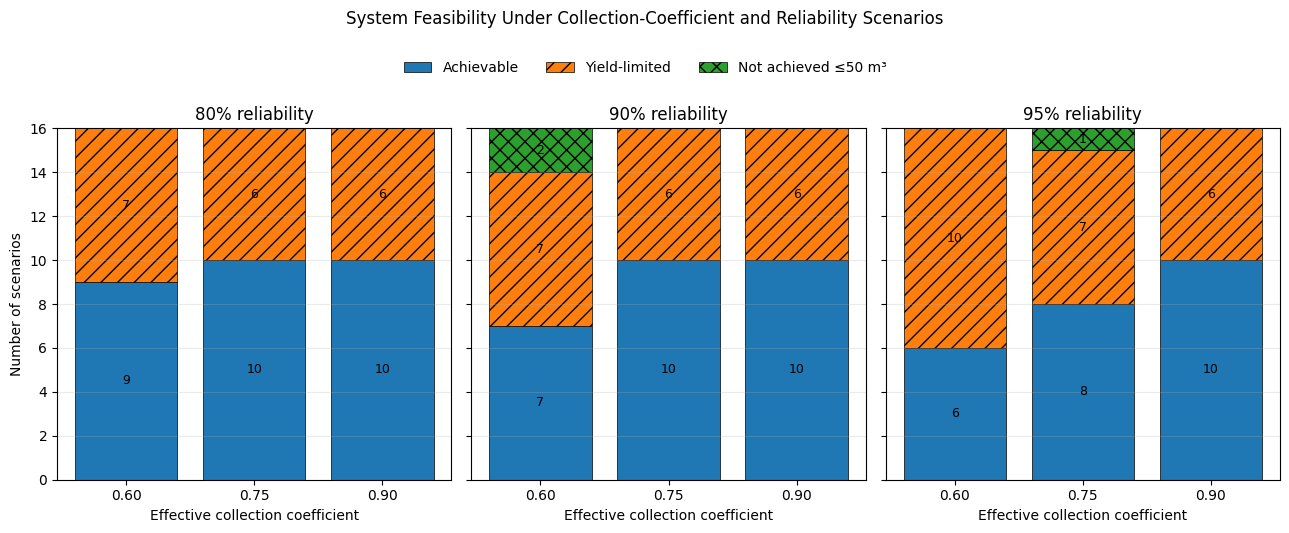

In [90]:
# ============================================================
# Figure 5
# Feasibility Sensitivity to Effective Collection Coefficient
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

reliability_targets = [
    80,
    90,
    95
]

collection_coefficients = [
    0.60,
    0.75,
    0.90
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.8),
    sharey=True
)

for ax, target in zip(
    axes,
    reliability_targets
):

    plot_data = (
        coefficient_sensitivity_summary[
            coefficient_sensitivity_summary[
                "reliability_target_pct"
            ] == target
        ]
        .sort_values(
            "effective_collection_coefficient"
        )
    )

    achievable = (
        plot_data["Achievable"]
        .to_numpy()
    )

    yield_limited = (
        plot_data[
            "Rainfall/catchment yield limited"
        ]
        .to_numpy()
    )

    storage_limited = (
        plot_data[
            "Not achieved with tested tanks <= 50 m3"
        ]
        .to_numpy()
    )

    x_positions = np.arange(
        len(collection_coefficients)
    )

    ax.bar(
        x_positions,
        achievable,
        label="Achievable",
        edgecolor="black",
        linewidth=0.5
    )

    ax.bar(
        x_positions,
        yield_limited,
        bottom=achievable,
        label="Yield-limited",
        edgecolor="black",
        linewidth=0.5,
        hatch="//"
    )

    ax.bar(
        x_positions,
        storage_limited,
        bottom=(
            achievable
            + yield_limited
        ),
        label="Not achieved ≤50 m³",
        edgecolor="black",
        linewidth=0.5,
        hatch="xx"
    )

    # Add segment values
    for index in range(
        len(collection_coefficients)
    ):

        if achievable[index] > 0:
            ax.text(
                index,
                achievable[index] / 2,
                str(achievable[index]),
                ha="center",
                va="center",
                fontsize=9
            )

        if yield_limited[index] > 0:
            ax.text(
                index,
                achievable[index]
                + yield_limited[index] / 2,
                str(yield_limited[index]),
                ha="center",
                va="center",
                fontsize=9
            )

        if storage_limited[index] > 0:
            ax.text(
                index,
                achievable[index]
                + yield_limited[index]
                + storage_limited[index] / 2,
                str(storage_limited[index]),
                ha="center",
                va="center",
                fontsize=9
            )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        [
            "0.60",
            "0.75",
            "0.90"
        ]
    )

    ax.set_xlabel(
        "Effective collection coefficient"
    )

    ax.set_title(
        f"{target}% reliability"
    )

    ax.set_ylim(
        0,
        16
    )

    ax.set_yticks(
        np.arange(
            0,
            17,
            2
        )
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

axes[0].set_ylabel(
    "Number of scenarios"
)

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)

fig.suptitle(
    "System Feasibility Under Collection-Coefficient "
    "and Reliability Scenarios",
    y=1.10
)

fig.tight_layout()

fig.savefig(
    "figure5_coefficient_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

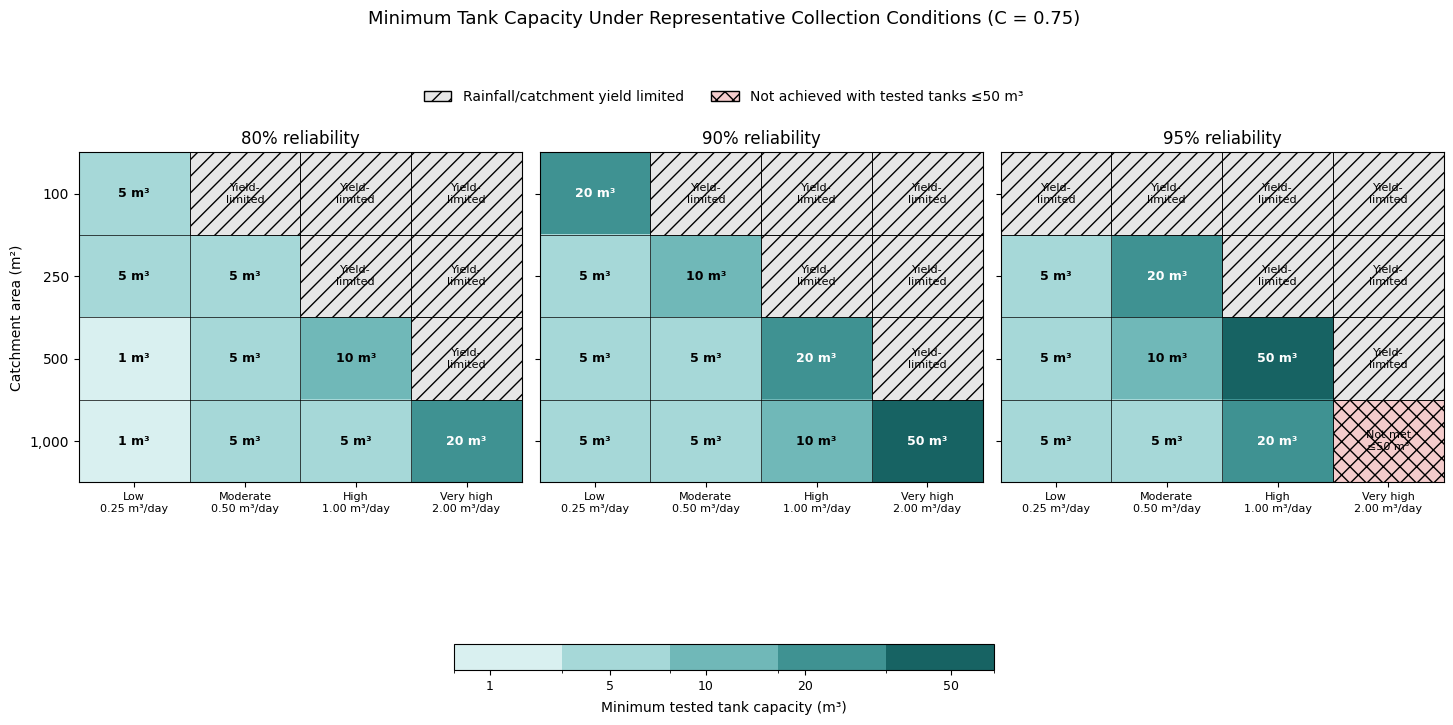

In [94]:
# ============================================================
# Figure 6
# Minimum Tested Tank Capacity — Representative Scenario
# Effective Collection Coefficient = 0.75
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm
)

from matplotlib.patches import (
    Rectangle,
    Patch
)

# Close any previously created versions of Figure 6
plt.close("all")

# ------------------------------------------------------------
# Figure settings
# ------------------------------------------------------------

reliability_targets = [
    80,
    90,
    95
]

catchment_areas = [
    100,
    250,
    500,
    1000
]

demand_order = [
    "Low demand",
    "Moderate demand",
    "High demand",
    "Very high demand"
]

demand_labels = [
    "Low\n0.25 m³/day",
    "Moderate\n0.50 m³/day",
    "High\n1.00 m³/day",
    "Very high\n2.00 m³/day"
]

# ------------------------------------------------------------
# Discrete colours for tested tank capacities
# ------------------------------------------------------------

tank_colours = [
    "#d9f0f0",
    "#a6d8d8",
    "#70b8b8",
    "#3f9292",
    "#176363"
]

tank_cmap = ListedColormap(
    tank_colours
)

tank_cmap.set_bad(
    color="white"
)

tank_boundaries = [
    0,
    3,
    7.5,
    15,
    35,
    60
]

tank_norm = BoundaryNorm(
    tank_boundaries,
    tank_cmap.N
)

# ------------------------------------------------------------
# Create figure and panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 7.5),
    sharey=True
)

# Reserve separate space for:
# - title and legend above the panels
# - demand labels and colour bar below the panels

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.34,
    top=0.78,
    wspace=0.04
)

image_object = None

# ------------------------------------------------------------
# Construct the three reliability panels
# ------------------------------------------------------------

for ax, target in zip(
    axes,
    reliability_targets
):

    target_data = (
        representative_diagnosis[
            representative_diagnosis[
                "reliability_target_pct"
            ] == target
        ]
        .copy()
    )

    tank_matrix = (
        target_data
        .pivot(
            index="catchment_area_m2",
            columns="demand_scenario",
            values="minimum_tested_tank_m3"
        )
        .reindex(
            index=catchment_areas,
            columns=demand_order
        )
    )

    diagnosis_matrix = (
        target_data
        .pivot(
            index="catchment_area_m2",
            columns="demand_scenario",
            values="limitation_diagnosis"
        )
        .reindex(
            index=catchment_areas,
            columns=demand_order
        )
    )

    matrix_values = (
        tank_matrix
        .to_numpy(dtype=float)
    )

    image_object = ax.imshow(
        np.ma.masked_invalid(
            matrix_values
        ),
        cmap=tank_cmap,
        norm=tank_norm,
        aspect="auto"
    )

    # --------------------------------------------------------
    # Annotate every matrix cell
    # --------------------------------------------------------

    for row_index in range(
        len(catchment_areas)
    ):

        for column_index in range(
            len(demand_order)
        ):

            tank_value = matrix_values[
                row_index,
                column_index
            ]

            diagnosis = diagnosis_matrix.iloc[
                row_index,
                column_index
            ]

            # Achievable scenario
            if not np.isnan(tank_value):

                text_colour = (
                    "white"
                    if tank_value >= 20
                    else "black"
                )

                ax.text(
                    column_index,
                    row_index,
                    f"{tank_value:g} m³",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color=text_colour
                )

            # Rainfall/catchment-yield-limited scenario
            elif (
                diagnosis
                == "Rainfall/catchment yield limited"
            ):

                rectangle = Rectangle(
                    (
                        column_index - 0.5,
                        row_index - 0.5
                    ),
                    width=1,
                    height=1,
                    facecolor="#e6e6e6",
                    edgecolor="black",
                    linewidth=0.5,
                    hatch="//"
                )

                ax.add_patch(
                    rectangle
                )

                ax.text(
                    column_index,
                    row_index,
                    "Yield-\nlimited",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black"
                )

            # Target not achieved using tanks up to 50 m³
            else:

                rectangle = Rectangle(
                    (
                        column_index - 0.5,
                        row_index - 0.5
                    ),
                    width=1,
                    height=1,
                    facecolor="#f4cccc",
                    edgecolor="black",
                    linewidth=0.5,
                    hatch="xx"
                )

                ax.add_patch(
                    rectangle
                )

                ax.text(
                    column_index,
                    row_index,
                    "Not met\n≤50 m³",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black"
                )

    # --------------------------------------------------------
    # Cell borders
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, 4, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 4, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="black",
        linewidth=0.5
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(
            len(demand_order)
        )
    )

    ax.set_xticklabels(
        demand_labels,
        fontsize=8
    )

    ax.set_yticks(
        np.arange(
            len(catchment_areas)
        )
    )

    ax.set_yticklabels(
        [
            "100",
            "250",
            "500",
            "1,000"
        ],
        fontsize=10
    )

    ax.set_title(
        f"{target}% reliability",
        fontsize=12
    )

# Shared vertical-axis label
axes[0].set_ylabel(
    "Catchment area (m²)",
    fontsize=10
)

# ------------------------------------------------------------
# Dedicated tank-capacity colour bar
# ------------------------------------------------------------

colour_bar_axis = fig.add_axes([
    0.32,    # left
    0.09,    # bottom
    0.36,    # width
    0.035    # height
])

colour_bar = fig.colorbar(
    image_object,
    cax=colour_bar_axis,
    orientation="horizontal",
    ticks=[
        1,
        5,
        10,
        20,
        50
    ]
)

colour_bar.set_label(
    "Minimum tested tank capacity (m³)",
    fontsize=10,
    labelpad=6
)

colour_bar.ax.tick_params(
    labelsize=9
)

# ------------------------------------------------------------
# Limitation legend
# ------------------------------------------------------------

limitation_legend = [
    Patch(
        facecolor="#e6e6e6",
        edgecolor="black",
        hatch="//",
        label="Rainfall/catchment yield limited"
    ),
    Patch(
        facecolor="#f4cccc",
        edgecolor="black",
        hatch="xx",
        label="Not achieved with tested tanks ≤50 m³"
    )
]

fig.legend(
    handles=limitation_legend,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.88),
    fontsize=10
)

# ------------------------------------------------------------
# Figure title
# ------------------------------------------------------------

fig.suptitle(
    "Minimum Tank Capacity Under Representative "
    "Collection Conditions (C = 0.75)",
    fontsize=13,
    y=0.97
)

# Do not add fig.tight_layout() because the colour-bar axis
# has been positioned manually.

# ------------------------------------------------------------
# Save and display
# ------------------------------------------------------------

fig.savefig(
    "figure6_tank_sizing_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()